In [1]:
import os
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import math
import pickle

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.stats import (
    chi2_contingency,
    fisher_exact,
    mannwhitneyu,
    spearmanr,
    pearsonr,
    skew,
    ttest_ind,
)
from statsmodels.stats.multitest import multipletests

from sklearn.base import BaseEstimator
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RepeatedKFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index, median_survival_times

from sksurv.ensemble import GradientBoostingSurvivalAnalysis, RandomSurvivalForest
from sksurv.linear_model import CoxnetSurvivalAnalysis
from sksurv.metrics import concordance_index_censored, cumulative_dynamic_auc

In [2]:
DIV_CMAP = LinearSegmentedColormap.from_list("lgg_div", ["#6b6b6b", "white", "#154DE6"])

warnings.filterwarnings("ignore", category=ConvergenceWarning)

sns.set_style("whitegrid")
np.random.seed(42)

kmf = KaplanMeierFitter()

# Data Cleaning and Pre-processing

In [3]:
def clean_tcga_id(x):
    return str(x).strip().upper()[:12]

## Clinical

In [4]:
def load_tcga_table(path, cols, skiprows=[2]):
    df = pd.read_csv(path, sep="\t", header=1, skiprows=skiprows)
    df = df[cols]
    return df

In [5]:
clinical_columns = [
    "bcr_patient_barcode",
    "vital_status",
    "days_to_death",
    "days_to_last_followup",
    "age_at_initial_pathologic_diagnosis",
    "gender"
]

In [6]:
clinical_path = r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\TCGA-LGG\Clinical\gdc_download_20260420_113549.245663"

clinical_df = load_tcga_table(
    os.path.join(
        clinical_path,
        "f3a1bc62-9552-4553-b318-7d9c21d21ce7/nationwidechildrens.org_clinical_patient_lgg.txt"
    ),
    clinical_columns
)

In [7]:
clinical_df["bcr_patient_barcode"] = clinical_df["bcr_patient_barcode"].map(clean_tcga_id)

In [8]:
clinical_df = clinical_df[
    clinical_df["vital_status"].str.upper().isin(["DEAD", "ALIVE"])
]

clinical_df["event"] = clinical_df["vital_status"].str.upper().map({
    "DEAD": 1,
    "ALIVE": 0
})

In [9]:
days_to_death = pd.to_numeric(
    clinical_df["days_to_death"], errors="coerce"
)

days_to_last_followup = pd.to_numeric(
    clinical_df["days_to_last_followup"], errors="coerce"
).replace(-1, np.nan)

clinical_df["time"] = days_to_death.fillna(days_to_last_followup)

clinical_df = clinical_df.dropna(subset=["time"])

In [10]:
clinical_df = clinical_df.drop(columns=[
    "days_to_death",
    "days_to_last_followup",
    "vital_status"
])

In [11]:
clinical_df["gender"] = clinical_df["gender"].str.upper().map({
    "MALE": 0,
    "FEMALE": 1
})
assert clinical_df["gender"].notnull().all()

In [12]:
clinical_df["age_at_initial_pathologic_diagnosis"] = pd.to_numeric(
    clinical_df["age_at_initial_pathologic_diagnosis"], errors="coerce")

### Feature Set

In [13]:
clinical_final = clinical_df.dropna(subset=["event", "time"]).set_index('bcr_patient_barcode')

In [14]:
assert clinical_final["time"].notnull().all()
assert clinical_final["event"].isin([0,1]).all()

In [15]:
clinical_final = clinical_final[~clinical_final.index.duplicated(keep='first')]

In [16]:
clinical_final.rename(columns={
    "age_at_initial_pathologic_diagnosis": "age"
}, inplace=True)

In [17]:
clinical_final = clinical_final[
    ["event", "time",
     "gender",
     "age",]
]

In [18]:
clinical_final = clinical_final.astype({
    "event": int,
    "time": float,
    "gender": int,
    "age": float,
})

In [19]:
n_before = len(clinical_final)
clinical_final = clinical_final[~(clinical_final["age"] < 18)]
print(f"Patients under 18 excluded: {n_before - len(clinical_final)}")

Patients under 18 excluded: 2


In [20]:
clinical_final

,event,time,gender,age
bcr_patient_barcode,,,,
TCGA-CS-4938,0,143.0,1,31.0
TCGA-CS-4941,1,234.0,0,67.0
TCGA-CS-4942,1,1335.0,1,44.0
TCGA-CS-4943,0,481.0,0,37.0
TCGA-CS-4944,0,323.0,0,50.0
...,...,...,...,...
TCGA-WY-A85A,0,1320.0,0,20.0
TCGA-WY-A85B,0,1003.0,0,24.0
TCGA-WY-A85C,0,866.0,0,36.0


## Somatic Mutation

In [21]:
mutation_path = r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\TCGA-LGG\Somatic Mutation"

maf_files = []

for root, dirs, files in os.walk(mutation_path):
    for f in files:
        if f.endswith(".maf.gz"):
            maf_files.append(os.path.join(root, f))

In [22]:
maf_list = []

for file in maf_files:
    mutation_df = pd.read_csv(file, sep="\t", comment="#", low_memory=False)
    mutation_df = mutation_df[mutation_df["Tumor_Sample_Barcode"].str[13:15] == "01"].copy()
    mutation_df["patient_id"] = mutation_df["Tumor_Sample_Barcode"].map(clean_tcga_id)
    mutation_df = mutation_df.drop_duplicates(subset=["patient_id", "Hugo_Symbol"])
    mutation_df = mutation_df[["patient_id", "Hugo_Symbol"]].copy()
    maf_list.append(mutation_df)

maf_df = pd.concat(maf_list, ignore_index=True)

In [23]:
mutation_matrix = maf_df.assign(value=1).pivot_table(
    index="patient_id",
    columns="Hugo_Symbol",
    values="value",
    aggfunc="max",
    fill_value=0
)

### Feature Set

In [24]:
selected_mutations_df = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\Biological Feature Selection\Final Feature Sets\somatic_mutation_features.tsv", sep="\t")
mutation_genes = selected_mutations_df["Gene"].tolist()

In [25]:
mutation_final = mutation_matrix.reindex(columns=mutation_genes, fill_value=0)

In [26]:
mutation_final = mutation_final.rename_axis(None, axis=1)

In [27]:
mutation_final = mutation_final.add_suffix("_mut")

In [28]:
mutation_final

,ATRX_mut,CIC_mut,EGFR_mut,FUBP1_mut,IDH1_mut,NF1_mut,NOTCH1_mut,PIK3CA_mut,PTEN_mut,TP53_mut
patient_id,,,,,,,,,,
TCGA-CS-4938,1,0,0,0,1,0,0,0,0,1
TCGA-CS-4941,0,0,0,0,0,0,0,0,0,0
TCGA-CS-4942,0,0,0,0,1,0,0,0,0,1
TCGA-CS-4943,1,0,0,0,1,0,0,0,0,1
TCGA-CS-4944,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
TCGA-WY-A85A,1,0,0,0,0,0,0,0,0,0
TCGA-WY-A85B,1,0,0,0,1,0,0,0,0,1
TCGA-WY-A85C,0,0,0,0,1,0,0,0,0,1


## Gene Expression

In [29]:
lgg_sample_sheet = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\TCGA-LGG\Expression_Sample_Sheet.tsv", sep='\t')
lgg_sample_sheet = lgg_sample_sheet[lgg_sample_sheet['Tumor Descriptor'] == 'Primary']
lgg_sample_sheet['File Name'] = lgg_sample_sheet['File Name'].str.strip().str.lower()
id_map = dict(zip(lgg_sample_sheet['File Name'], lgg_sample_sheet['Case ID']))

In [30]:
expression_path = r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\TCGA-LGG\Gene Expression"

def load_expression_file(file):
    df = pd.read_csv(file, sep="\t", comment="#", low_memory=False)
    df = df[df["gene_name"].notna()]
    df = df[["gene_name", "tpm_unstranded"]]

    return df.groupby("gene_name")["tpm_unstranded"].mean()

In [31]:
tsv_files = [
    os.path.join(r, f)
    for r, d, files in os.walk(expression_path)
    for f in files if f.endswith(".tsv")
]

expression_list = []
mapped = 0
skipped = 0

for file in tsv_files:
    filename = os.path.basename(file).strip().lower()
    case_id = id_map.get(filename)

    if case_id:
        try:
            series = load_expression_file(file)
            series.name = clean_tcga_id(case_id)
            expression_list.append(series)
            mapped += 1
        except Exception as e:
            print(f"Error loading {filename}: {e}")
    else:
        skipped += 1

print(f"Mapped files: {mapped}")
print(f"Skipped files: {skipped}")

if len(expression_list) == 0:
    raise ValueError("No files mapped.")

Mapped files: 516
Skipped files: 18


In [32]:
expression_df = pd.concat(expression_list, axis=1).T
expression_df.head()

gene_name,5S_rRNA,5_8S_rRNA,7SK,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,...,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZYXP1,ZZEF1,ZZZ3,hsa-mir-1253,hsa-mir-423,snoZ196
TCGA-KT-A74X,0.047544,0.000000,0.0,0.7145,0.7124,0.0094,176.8578,0.8615,1.9457,0.0,...,0.0000,0.0,16.5808,104.4518,0.0,17.3475,7.7738,0.0,0.0,1.0192
TCGA-HT-8013,0.055600,0.000000,0.0,0.7296,1.5880,0.0055,528.6767,0.8277,2.7354,0.0,...,0.0000,0.0,27.7131,146.7367,0.0,20.4370,18.4264,0.0,0.0,0.0000
TCGA-WY-A858,0.000000,0.180267,0.0,0.3974,0.6334,0.0000,571.3653,0.9295,0.7352,0.0,...,0.0117,0.0,10.9922,71.8599,0.0,7.8848,6.7710,0.0,0.0,1.8472
TCGA-FG-A6J3,0.085944,0.089900,0.0,0.3690,0.3888,0.0000,1237.9637,2.2805,0.2406,0.0,...,0.0524,0.0,12.4391,152.9849,0.0,9.6551,9.7025,0.0,0.0,0.0000
TCGA-QH-A6CU,0.000000,0.000000,0.0,0.0000,0.2059,0.0000,145.5943,0.7306,4.7674,0.0,...,0.0000,0.0,9.9320,112.2082,0.0,9.0175,4.7668,0.0,0.0,0.0000


### Feature Set

In [33]:
selected_expression_df = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\Biological Feature Selection\Final Feature Sets\gene_expr_features.tsv", sep="\t")
expression_genes = selected_expression_df["Gene"].tolist()

In [34]:
expression_genes = [gene for gene in expression_genes if gene != "EZHIP"]

In [35]:
existing_genes = [gene for gene in expression_genes if gene in expression_df.columns]
expression_original = expression_df[existing_genes].copy()

In [36]:
missing_genes = [gene for gene in expression_genes if gene not in expression_df.columns]

print("Missing genes:")
print(missing_genes)

Missing genes:
['HN1']


In [37]:
expression_duplicates = expression_original.index[expression_original.index.duplicated()].unique()
print(f"Duplicates: {len(expression_duplicates)}")

Duplicates: 0


In [38]:
expression_original = expression_original.groupby(expression_original.index).median()

In [39]:
expression_original = expression_original.add_suffix("_exp")

In [40]:
expression_original = expression_original.rename_axis(None, axis=1)

In [41]:
expression_cols = expression_original.columns
expression_final = np.log1p(expression_original[expression_cols])
expr_cols = expression_final.columns

In [42]:
expression_final.head()

,ACVR1_exp,ALDOB_exp,ALDOC_exp,ALK_exp,ARNTL_exp,ARPC1B_exp,ATRX_exp,AURKB_exp,BRAF_exp,CDC45_exp,...,RPA2_exp,S100A11_exp,SHC1_exp,SOX9_exp,SPP1_exp,TP53_exp,TSC1_exp,TSC2_exp,VAV3_exp,ZYX_exp
TCGA-CS-4938,3.014009,0.523011,6.496409,0.932322,1.752412,0.070552,1.489257,0.485200,1.523008,0.621436,...,4.747829,4.813084,2.232903,5.420257,5.355513,3.421644,2.568075,2.731916,0.154950,4.080148
TCGA-CS-4941,3.482246,0.297954,5.669874,1.892916,3.174845,0.427879,3.044741,1.580791,2.031577,1.892253,...,5.454301,6.379897,3.617668,6.013013,7.628986,3.890258,2.546260,2.970004,3.622884,5.394827
TCGA-CS-4942,2.897739,0.477786,6.531492,0.619716,2.305212,0.421732,2.065279,2.016062,1.886615,1.389041,...,4.786105,5.970332,2.720018,5.333722,7.738627,3.786857,2.482470,3.013607,0.527978,4.745051
TCGA-CS-4943,3.240657,0.224103,6.589341,2.075848,2.072014,0.283599,2.249490,4.245274,1.976481,3.600472,...,5.280211,4.832573,2.730268,6.240975,5.815038,4.679480,2.786584,3.544180,0.394269,4.851228
TCGA-CS-4944,3.298031,0.257815,7.268633,1.690963,2.121291,0.148420,2.247495,0.000000,1.216899,0.158200,...,4.748294,4.743444,2.479165,5.604983,5.409168,2.600895,2.160284,2.518204,0.844709,4.120230


## Final Feature Set

In [43]:
merged_df = pd.concat([clinical_final, mutation_final, expression_final], axis=1, join='inner')

In [44]:
print("Clinical:", clinical_final.shape)
print("Mutation:", mutation_final.shape)
print("Expression:", expression_final.shape)
print("Merged:", merged_df.shape)

Clinical: (508, 4)
Mutation: (509, 10)
Expression: (516, 68)
Merged: (501, 82)


In [45]:
print(f"Patients in clinical: {len(clinical_final)}")
print(f"Patients after adding mutation: {len(clinical_final.index.intersection(mutation_final.index))}")
print(f"Final merged: {len(merged_df)}")

Patients in clinical: 508
Patients after adding mutation: 501
Final merged: 501


In [46]:
merged_df.head(3)

,event,time,gender,age,ATRX_mut,CIC_mut,EGFR_mut,FUBP1_mut,IDH1_mut,NF1_mut,...,RPA2_exp,S100A11_exp,SHC1_exp,SOX9_exp,SPP1_exp,TP53_exp,TSC1_exp,TSC2_exp,VAV3_exp,ZYX_exp
TCGA-CS-4938,0,143.0,1,31.0,1,0,0,0,1,0,...,4.747829,4.813084,2.232903,5.420257,5.355513,3.421644,2.568075,2.731916,0.154950,4.080148
TCGA-CS-4941,1,234.0,0,67.0,0,0,0,0,0,0,...,5.454301,6.379897,3.617668,6.013013,7.628986,3.890258,2.546260,2.970004,3.622884,5.394827
TCGA-CS-4942,1,1335.0,1,44.0,0,0,0,0,1,0,...,4.786105,5.970332,2.720018,5.333722,7.738627,3.786857,2.482470,3.013607,0.527978,4.745051


In [47]:
merged_df.to_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg\merged_df.csv", index=False)

# Exploratory Data Analysis

## Survival Outcomes

event
1    17.9641
0    82.0359
Name: count, dtype: float64


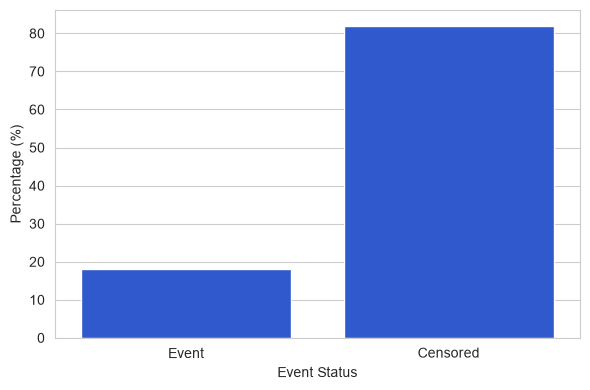

In [48]:
event_counts = merged_df["event"].value_counts().reindex([1, 0])
event_percentages = (event_counts / event_counts.sum() * 100).round(4)
print(event_percentages)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=event_counts.index.map({0: "Censored", 1: "Event"}),
    y=event_percentages.values,
    ax=ax,
    color="#154DE6"
)
ax.set_xlabel("Event Status")
ax.set_ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

count     501.000000
mean      701.942116
std       909.299024
min         0.000000
25%       146.000000
50%       378.000000
75%       886.000000
max      6423.000000
Name: time, dtype: float64


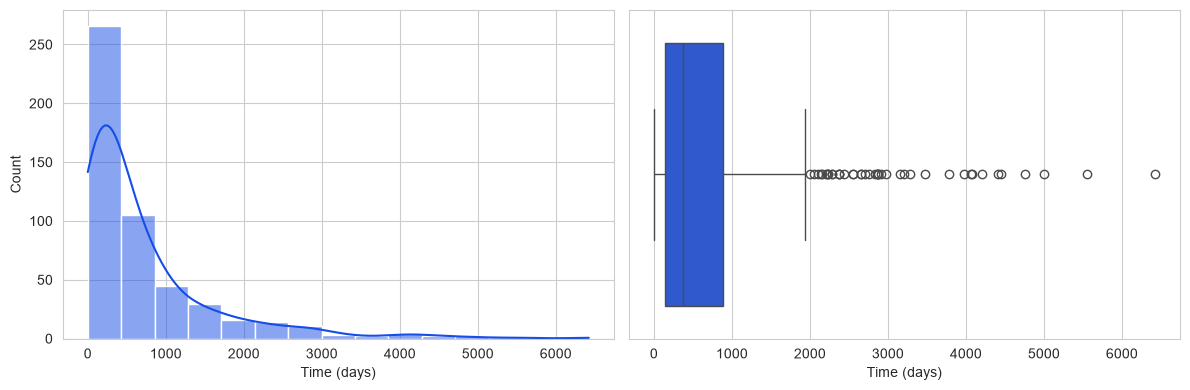

In [49]:
time_described = merged_df["time"].describe()
print(time_described)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(merged_df["time"], bins=15, kde=True, ax=ax1, color="#154DE6")
ax1.set_xlabel("Time (days)")
ax1.set_ylabel("Count")

sns.boxplot(x=merged_df["time"], ax=ax2, color="#154DE6")
ax2.set_xlabel("Time (days)")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

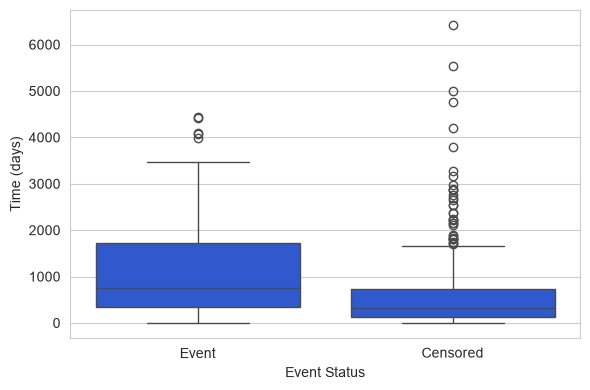

In [50]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(
    x=merged_df["event"].map({0: "Censored", 1: "Event"}),
    y=merged_df["time"],
    order=["Event", "Censored"],
    ax=ax,
    color="#154DE6"
)
ax.set_xlabel("Event Status")
ax.set_ylabel("Time (days)")
plt.tight_layout()
plt.show()

In [51]:
q1, q3 = merged_df["time"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
long_time = merged_df["time"] > upper_fence
outliers, rest = merged_df[long_time], merged_df[~long_time]

print(f"Outlier threshold: {upper_fence:.0f} days; patients beyond it: {len(outliers)} "
      f"({int(outliers['event'].sum())} deceased, {int((outliers['event'] == 0).sum())} censored)")
print(f"Median age: {outliers['age'].median():.0f} vs {rest['age'].median():.0f} years (outliers vs rest)")
print(f"IDH1-mutant: {outliers['IDH1_mut'].mean():.0%} vs {rest['IDH1_mut'].mean():.0%} (outliers vs rest)")

Outlier threshold: 1996 days; patients beyond it: 43 (18 deceased, 25 censored)
Median age: 35 vs 42 years (outliers vs rest)
IDH1-mutant: 86% vs 76% (outliers vs rest)


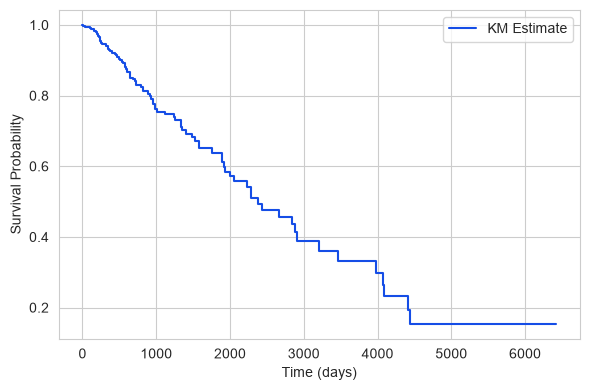

In [52]:
fig, ax = plt.subplots(figsize=(6, 4))

kmf.fit(merged_df["time"], merged_df["event"], label="KM Estimate")
kmf.plot_survival_function(ax=ax, color="#154DE6", ci_show=False)

ax.set_xlabel("Time (days)")
ax.set_ylabel("Survival Probability")
ax.get_legend().set_title(None)
plt.tight_layout()
plt.show()

In [53]:
median_os = kmf.median_survival_time_
median_os_ci = median_survival_times(kmf.confidence_interval_)
print(f"Median overall survival: {median_os:.0f} days "
      f"(95% CI {median_os_ci.iloc[0, 0]:.0f}-{median_os_ci.iloc[0, 1]:.0f})")

kmf_followup = KaplanMeierFitter().fit(merged_df["time"], 1 - merged_df["event"])
print(f"Median follow-up (reverse Kaplan-Meier): {kmf_followup.median_survival_time_:.0f} days")

for label, s in zip(["1-year", "3-year", "5-year"], kmf.survival_function_at_times([365, 1095, 1825]).values):
    print(f"{label} survival: {s:.1%}")

Median overall survival: 2379 days (95% CI 1933-3200)
Median follow-up (reverse Kaplan-Meier): 438 days
1-year survival: 92.9%
3-year survival: 75.5%
5-year survival: 63.9%


## Clinical

gender
1    44.511
0    55.489
Name: count, dtype: float64


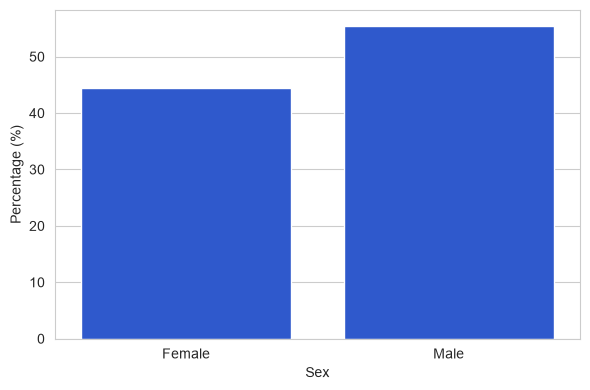

In [54]:
gender_counts = merged_df["gender"].value_counts().reindex([1, 0])
gender_percentages = (gender_counts / gender_counts.sum() * 100).round(4)
print(gender_percentages)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=gender_counts.index.map({0: "Male", 1: "Female"}),
    y=gender_percentages.values,
    ax=ax,
    color="#154DE6"
)
ax.set_xlabel("Sex")
ax.set_ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

count    501.000000
mean      43.129741
std       13.255834
min       18.000000
25%       33.000000
50%       41.000000
75%       53.000000
max       87.000000
Name: age, dtype: float64
Age: mean 43.1 (SD 13.3), median 41.0 years


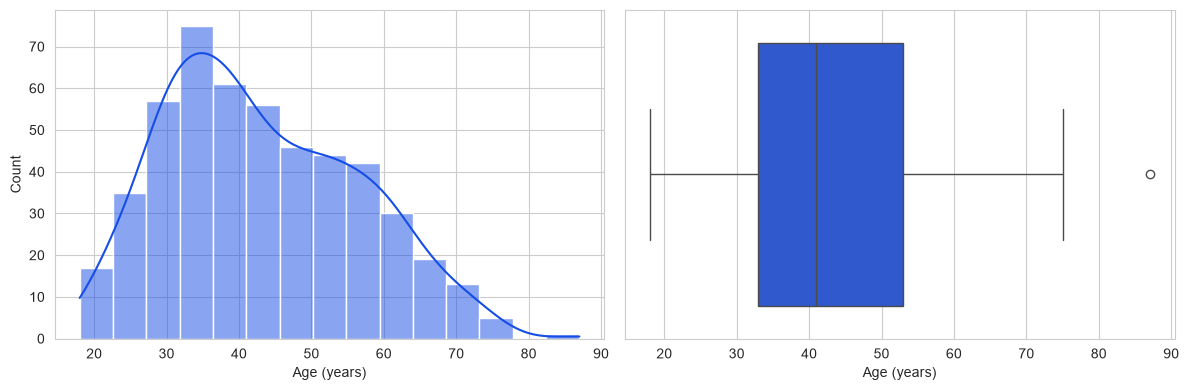

In [55]:
age_described = merged_df["age"].describe()
print(age_described)
print(f"Age: mean {merged_df['age'].mean():.1f} (SD {merged_df['age'].std():.1f}), median {merged_df['age'].median():.1f} years")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(merged_df["age"], bins=15, kde=True, ax=ax1, color="#154DE6")
ax1.set_xlabel("Age (years)")
ax1.set_ylabel("Count")

sns.boxplot(x=merged_df["age"], ax=ax2, color="#154DE6")
ax2.set_xlabel("Age (years)")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

In [56]:
n = len(merged_df)
print(f"Female: {int(merged_df['gender'].sum())}/{n} ({merged_df['gender'].mean():.1%})")
print(f"IDH1-mutant: {int(merged_df['IDH1_mut'].sum())}/{n} ({merged_df['IDH1_mut'].mean():.1%})")

grade_df = load_tcga_table(
    os.path.join(
        clinical_path,
        "f3a1bc62-9552-4553-b318-7d9c21d21ce7/nationwidechildrens.org_clinical_patient_lgg.txt"
    ),
    ["bcr_patient_barcode", "neoplasm_histologic_grade"]
)
grade_df["bcr_patient_barcode"] = grade_df["bcr_patient_barcode"].map(clean_tcga_id)
grade_counts = (grade_df.drop_duplicates("bcr_patient_barcode")
                        .set_index("bcr_patient_barcode")["neoplasm_histologic_grade"]
                        .reindex(merged_df.index)
                        .value_counts(dropna=False))
print("Grade:", grade_counts.to_dict())

Female: 223/501 (44.5%)
IDH1-mutant: 387/501 (77.2%)
Grade: {'G3': 260, 'G2': 240, '[Discrepancy]': 1}


## Somatic Mutation

In [57]:
merged_mutation_df = merged_df[mutation_final.columns]
sparsity = ((merged_mutation_df == 0).sum().sum() / merged_mutation_df.size)
print("Sparsity:", sparsity)

Sparsity: 0.7762475049900199


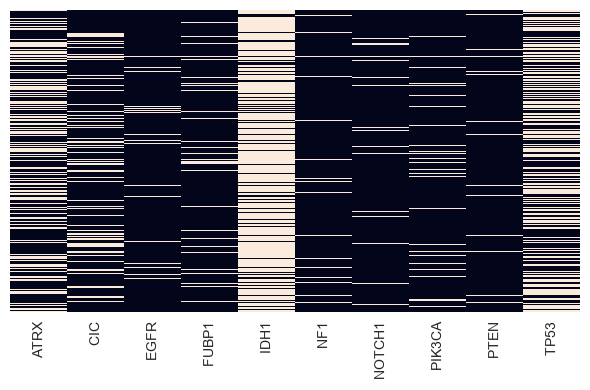

In [58]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(merged_mutation_df.rename(columns=lambda c: c.replace('_mut', '').upper()),
            cbar=False, yticklabels=False, ax=ax)
plt.tight_layout()
plt.show()

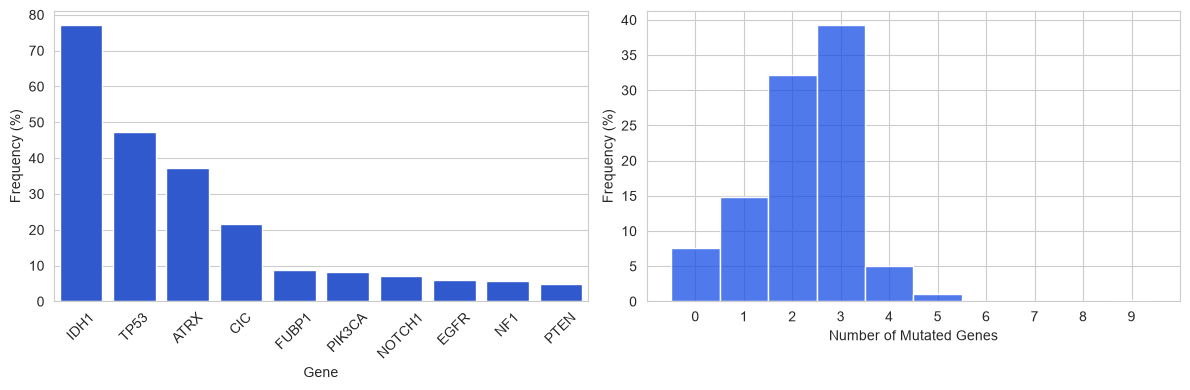

In [59]:
mutation_freq = (merged_mutation_df.mean().sort_values(ascending=False) * 100)
mutation_freq.index = mutation_freq.index.str.replace('_mut', '').str.upper()
mutation_burden = merged_mutation_df.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=mutation_freq.index, y=mutation_freq.values, color="#154DE6", ax=axes[0])
axes[0].set_xlabel("Gene")
axes[0].set_ylabel("Frequency (%)")
axes[0].tick_params(axis='x', rotation=45)

sns.histplot(mutation_burden, discrete=True, color="#154DE6", stat="percent", ax=axes[1])
axes[1].set_xlabel("Number of Mutated Genes")
axes[1].set_ylabel("Frequency (%)")
axes[1].set_xticks(range(int(mutation_burden.max()) + 1))

plt.tight_layout()
plt.show()

In [60]:
print("Mutation frequency (% of patients):")
print((merged_mutation_df.mean() * 100).sort_values(ascending=False)
      .rename(lambda g: g.replace("_mut", "")).round(1).to_string())

mutation_count = merged_mutation_df.sum(axis=1)
print()
print(f"Mutation count: median {mutation_count.median():.0f} "
      f"(IQR {mutation_count.quantile(0.25):.0f}-{mutation_count.quantile(0.75):.0f}), max {mutation_count.max()}")
print(f"Patients with no mutation in the selected genes: {int((mutation_count == 0).sum())} "
      f"({(mutation_count == 0).mean():.1%})")
print("Distribution:", mutation_count.value_counts().sort_index().to_dict())

Mutation frequency (% of patients):
IDH1      77.2
TP53      47.3
ATRX      37.1
CIC       21.6
FUBP1      8.8
PIK3CA     8.2
NOTCH1     7.2
EGFR       6.0
NF1        5.6
PTEN       4.8

Mutation count: median 2 (IQR 2-3), max 9
Patients with no mutation in the selected genes: 38 (7.6%)
Distribution: {0: 38, 1: 74, 2: 161, 3: 197, 4: 25, 5: 5, 9: 1}


## Gene Expression

### Original

In [61]:
original_expression_df = merged_df[expression_original.columns]

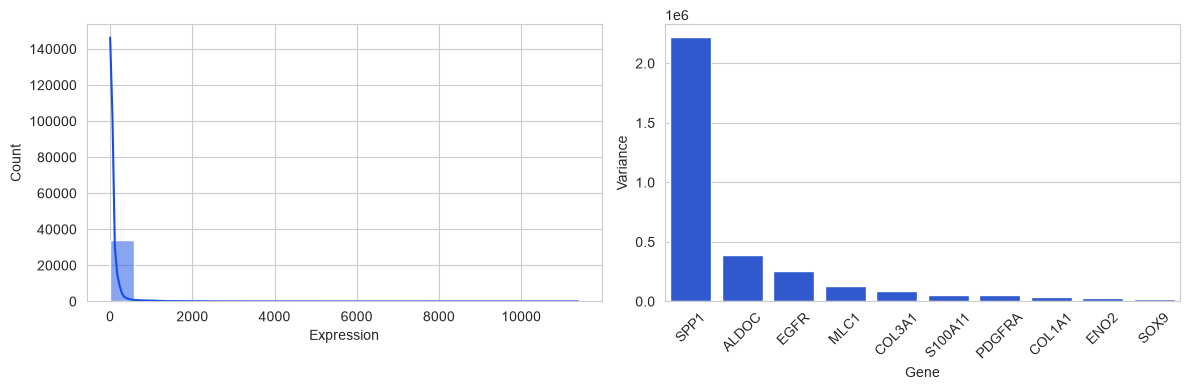

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(expression_original.values.flatten(), bins=20, kde=True, color="#154DE6", ax=axes[0])
axes[0].set_xlabel("Expression")
axes[0].set_ylabel("Count")

top10_var = expression_original.var().sort_values(ascending=False).head(10)
top10_var.index = top10_var.index.str.replace('_exp', '')
sns.barplot(x=top10_var.index, y=top10_var.values, color="#154DE6", ax=axes[1])
axes[1].set_ylabel("Variance")
axes[1].set_xlabel("Gene")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Log-transformed

In [63]:
merged_expression_df = merged_df[expression_final.columns]

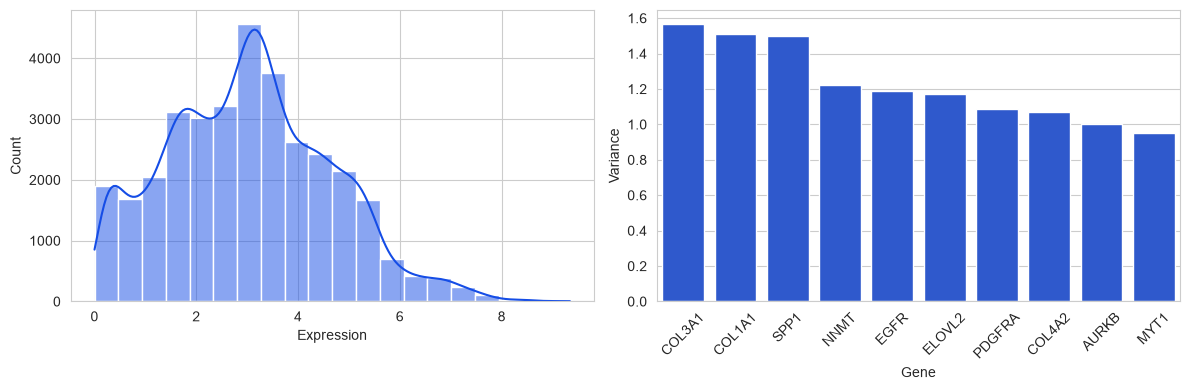

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(merged_expression_df.values.flatten(), bins=20, kde=True, color="#154DE6", ax=axes[0])
axes[0].set_xlabel("Expression")
axes[0].set_ylabel("Count")

top10_var = merged_expression_df.var().sort_values(ascending=False).head(10)
top10_var.index = top10_var.index.str.replace('_exp', '')
sns.barplot(x=top10_var.index, y=top10_var.values, color="#154DE6", ax=axes[1])
axes[1].set_ylabel("Variance")
axes[1].set_xlabel("Gene")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [65]:
log_expr = merged_expression_df
raw_expr = np.expm1(log_expr)
raw_vals, log_vals = raw_expr.values.ravel(), log_expr.values.ravel()
print(f"Original TPM: median {np.median(raw_vals):.1f}, max {raw_vals.max():.0f}, skewness {skew(raw_vals):.2f}")
print(f"log(1 + TPM): median {np.median(log_vals):.2f}, max {log_vals.max():.2f}, skewness {skew(log_vals):.2f}")

top_raw = raw_expr.var().sort_values(ascending=False).head(10).index
top_log = log_expr.var().sort_values(ascending=False).head(10).index
print()
print("Ten most variable genes (original scale):", [g.replace("_exp", "") for g in top_raw])
print("Ten most variable genes (log scale):     ", [g.replace("_exp", "") for g in top_log])
print(f"Genes in both lists: {len(set(top_raw) & set(top_log))}")
ratio = raw_expr[top_raw].median().median() / raw_expr.median().median()
print(f"Median TPM of the original-scale top 10 vs all genes: "
      f"{raw_expr[top_raw].median().median():.0f} vs {raw_expr.median().median():.0f} ({ratio:.1f}x)")

Original TPM: median 19.7, max 11391, skewness 14.16
log(1 + TPM): median 3.03, max 9.34, skewness 0.29

Ten most variable genes (original scale): ['SPP1', 'ALDOC', 'EGFR', 'MLC1', 'COL3A1', 'S100A11', 'PDGFRA', 'COL1A1', 'ENO2', 'SOX9']
Ten most variable genes (log scale):      ['COL3A1', 'COL1A1', 'SPP1', 'NNMT', 'EGFR', 'ELOVL2', 'PDGFRA', 'COL4A2', 'AURKB', 'MYT1']
Genes in both lists: 5
Median TPM of the original-scale top 10 vs all genes: 151 vs 19 (8.1x)


# Association Analysis

## Within-layer Association Analysis

### Clinical

t=-0.687, p=0.493


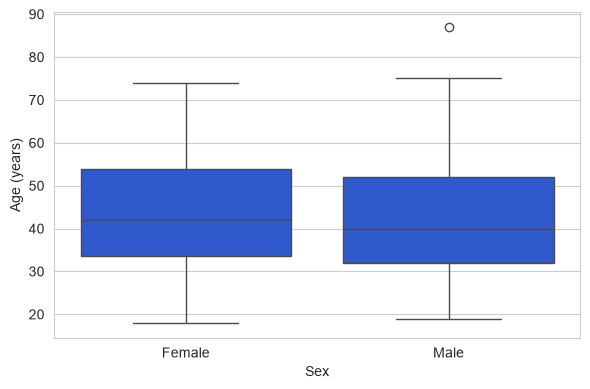

In [66]:
male_age = merged_df[merged_df["gender"] == 0]["age"]
female_age = merged_df[merged_df["gender"] == 1]["age"]
t_stat, p_age = ttest_ind(male_age, female_age, equal_var=False)
print(f"t={t_stat:.3f}, p={p_age:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(x=merged_df["gender"].map({0: "Male", 1: "Female"}),
            y=merged_df["age"],
            order=["Female", "Male"],
            color="#154DE6",
            ax=ax)
ax.set_xlabel("Sex")
ax.set_ylabel("Age (years)")
plt.tight_layout()
plt.show()

### Somatic Mutation

In [67]:
mut_df = merged_mutation_df.copy()
co_occurrence = mut_df.T.dot(mut_df)

In [68]:
mut_counts = merged_mutation_df.sum()
common_muts = mut_counts[mut_counts >= 5].index
mut_df_filtered = merged_mutation_df[common_muts]

co_occurrence = mut_df_filtered.T.dot(mut_df_filtered)
corr_matrix, pval_matrix = spearmanr(mut_df_filtered)
corr_df = pd.DataFrame(corr_matrix, index=common_muts, columns=common_muts)
pval_df = pd.DataFrame(pval_matrix, index=common_muts, columns=common_muts)

clean_labels = [c.replace('_mut', '').upper() for c in common_muts]
co_display = co_occurrence.copy()
co_display.index = co_display.columns = clean_labels

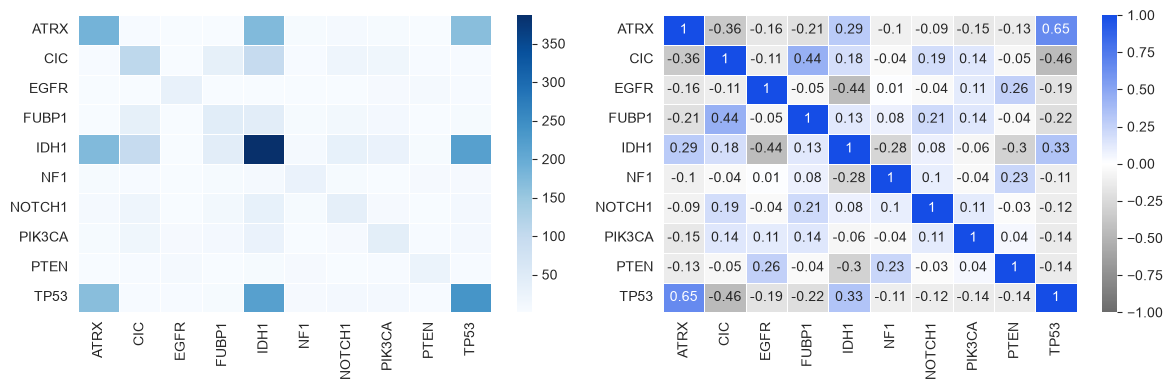

In [69]:
corr_display = corr_df.copy()
corr_display.index = corr_display.columns = clean_labels

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(co_display, cmap='Blues', annot=False, ax=axes[0], linewidths=0.5)

sns.heatmap(corr_display.round(2), annot=True, cmap=DIV_CMAP, center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=axes[1])

plt.tight_layout()
plt.show()

In [70]:
mask = np.triu(np.ones(corr_df.shape), k=1).astype(bool)
corr_pairs = corr_df.where(mask).stack()
pval_pairs = pval_df.where(mask).stack()
sig_pairs = corr_pairs[pval_pairs < 0.05]
top10_sig = sig_pairs.reindex(sig_pairs.abs().sort_values(ascending=False).index).head(10).reset_index()
top10_sig.columns = ["Mutation 1", "Mutation 2", "Correlation"]
top10_sig["P-value"] = pval_pairs[top10_sig.set_index(["Mutation 1", "Mutation 2"]).index].values
top10_sig["P-value"] = top10_sig["P-value"].map("{:.2e}".format)
top10_sig["Mutation 1"] = top10_sig["Mutation 1"].str.replace('_mut', '').str.upper()
top10_sig["Mutation 2"] = top10_sig["Mutation 2"].str.replace('_mut', '').str.upper()
print(top10_sig)

  Mutation 1 Mutation 2  Correlation   P-value
0       ATRX       TP53     0.645522  2.15e-60
1        CIC       TP53    -0.457805  2.53e-27
2       EGFR       IDH1    -0.444934  9.93e-26
3        CIC      FUBP1     0.437563  7.58e-25
4       ATRX        CIC    -0.362639  5.13e-17
5       IDH1       TP53     0.333065  1.92e-14
6       IDH1       PTEN    -0.301821  5.19e-12
7       ATRX       IDH1     0.288956  4.32e-11
8       IDH1        NF1    -0.282472  1.21e-10
9       EGFR       PTEN     0.258521  4.30e-09


### Gene Expression

In [71]:
expr = merged_df[expr_cols]
top_var_genes = expr.var().sort_values(ascending=False).head(30).index
expr_top = expr[top_var_genes]

corr_df = expr_top.corr(method='pearson')
pval_matrix = np.zeros((len(expr_top.columns), len(expr_top.columns)))
for i, col1 in enumerate(expr_top.columns):
    for j, col2 in enumerate(expr_top.columns):
        _, pval_matrix[i, j] = pearsonr(expr_top[col1], expr_top[col2])
pval_df = pd.DataFrame(pval_matrix, index=expr_top.columns, columns=expr_top.columns)

clean_genes = [c.replace('_exp', '') for c in expr_top.columns]

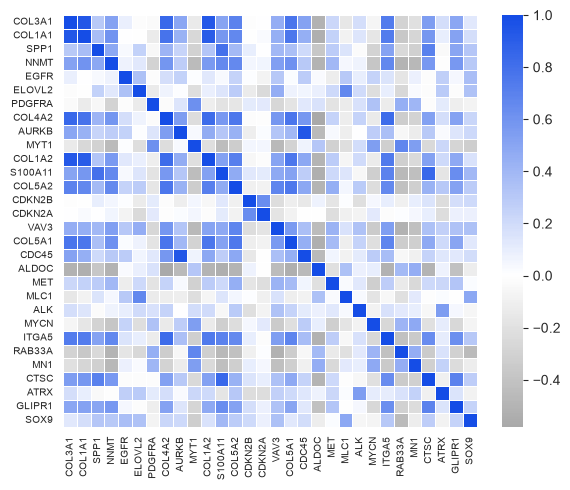

In [72]:
corr_display = corr_df.copy()
corr_display.index = corr_display.columns = clean_genes

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_display, cmap=DIV_CMAP, center=0,
            xticklabels=True, yticklabels=True, linewidth=0.5, ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7.5)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=7.5)
plt.tight_layout()
plt.show()

In [73]:
mask = np.triu(np.ones(corr_df.shape), k=1).astype(bool)
corr_pairs = corr_df.where(mask).stack()
pval_pairs = pval_df.where(mask).stack()
sig_pairs = corr_pairs[pval_pairs < 0.05]
top10_sig = sig_pairs.reindex(sig_pairs.abs().sort_values(ascending=False).index).head(10).reset_index()
top10_sig.columns = ["Gene 1", "Gene 2", "Correlation"]
top10_sig["P-value"] = pval_pairs[top10_sig.set_index(["Gene 1", "Gene 2"]).index].values
top10_sig["P-value"] = top10_sig["P-value"].map("{:.2e}".format)
top10_sig["Gene 1"] = top10_sig["Gene 1"].str.replace('_exp', '')
top10_sig["Gene 2"] = top10_sig["Gene 2"].str.replace('_exp', '')
print(top10_sig)

    Gene 1   Gene 2  Correlation    P-value
0    AURKB    CDC45     0.943273  4.35e-241
1   COL3A1   COL1A1     0.934130  2.10e-225
2   COL3A1   COL1A2     0.926108  2.13e-213
3   COL1A1   COL1A2     0.905200  1.43e-187
4  S100A11     CTSC     0.849114  2.01e-140
5   COL3A1   COL4A2     0.848912  2.73e-140
6   COL4A2    ITGA5     0.822816  1.49e-124
7   COL4A2   COL1A2     0.821497  7.94e-124
8     SPP1  S100A11     0.784955  8.02e-106
9   COL1A1   COL4A2     0.781579  2.45e-104


## Association with Survival Outcomes

### Clinical

In [74]:
gender_map = {0: "Male", 1: "Female"}
event_map = {0: "Censored", 1: "Event"}

ct_gender = pd.crosstab(merged_df["event"].map(event_map), merged_df["gender"].map(gender_map))
chi2, p_gender, _, _ = chi2_contingency(ct_gender)
_, p_age = mannwhitneyu(merged_df.loc[merged_df["event"] == 0, "age"],
                        merged_df.loc[merged_df["event"] == 1, "age"], alternative="two-sided")
u_stat, p_gender_time = mannwhitneyu(merged_df.loc[merged_df["gender"] == 0, "time"],
                                     merged_df.loc[merged_df["gender"] == 1, "time"], alternative="two-sided")
rho_age, p_age_time = spearmanr(merged_df["age"], merged_df["time"])
gbm_age = 60

print(f"Event by Sex: χ²={chi2:.2f}, p={p_gender:.3f}")

Event by Sex: χ²=1.08, p=0.298


Age vs Event: p=0.000


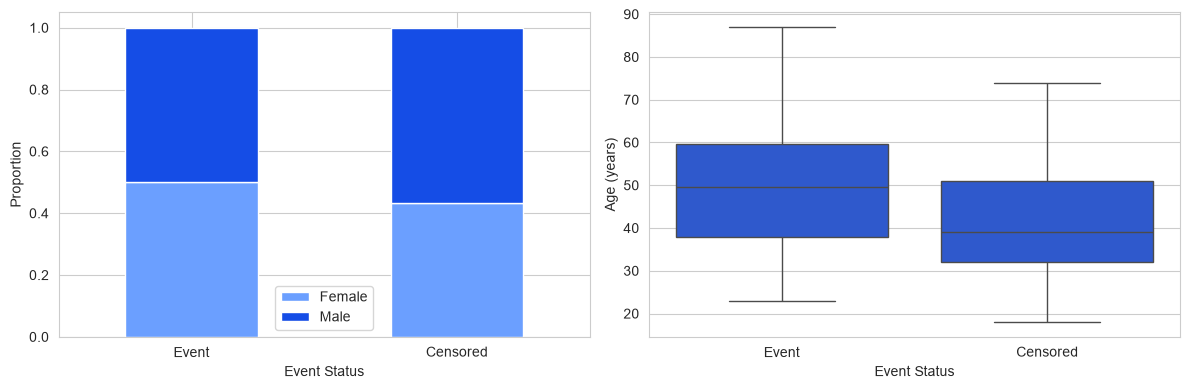

In [75]:
print(f"Age vs Event: p={p_age:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

pd.crosstab(merged_df["event"].map(event_map), merged_df["gender"].map(gender_map), normalize="index").reindex(["Event", "Censored"]).plot(
    kind="bar", stacked=True, ax=axes[0], color=["#6B9FFF", "#154DE6"])
axes[0].set_xlabel("Event Status")
axes[0].set_ylabel("Proportion")
axes[0].tick_params(axis="x", rotation=0)
axes[0].get_legend().set_title(None)

sns.boxplot(
    x=merged_df["event"].map(event_map),
    y=merged_df["age"],
    hue=merged_df["event"].map(event_map),
    order=["Event", "Censored"],
    palette={"Event": "#154DE6", "Censored": "#154DE6"},
    legend=False,
    ax=axes[1]
)
axes[1].set_xlabel("Event Status")
axes[1].set_ylabel("Age (years)")

plt.tight_layout()
plt.show()

Time by Sex: U=30879.0, p=0.942
Age vs Time: Spearman r=-0.086, p=0.053


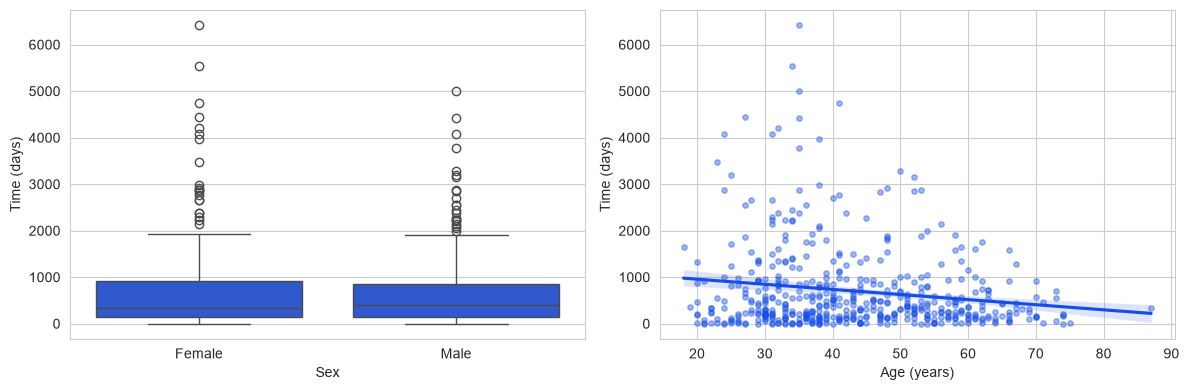

In [76]:
print(f"Time by Sex: U={u_stat:.1f}, p={p_gender_time:.3f}")
print(f"Age vs Time: Spearman r={rho_age:.3f}, p={p_age_time:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(
    x=merged_df["gender"].map(gender_map),
    y=merged_df["time"],
    hue=merged_df["gender"].map(gender_map),
    order=["Female", "Male"],
    palette={"Female": "#154DE6", "Male": "#154DE6"},
    legend=False,
    ax=axes[0]
)
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Time (days)")

sns.regplot(x=merged_df["age"], y=merged_df["time"], ax=axes[1], color= "#154DE6",
            scatter_kws={"alpha": 0.4, "s": 15})
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Time (days)")

plt.tight_layout()
plt.show()

In [77]:
lgg_age = 40

lr_age    = logrank_test(merged_df.loc[merged_df["age"] <  lgg_age, "time"],
                         merged_df.loc[merged_df["age"] >= lgg_age, "time"],
                         event_observed_A=merged_df.loc[merged_df["age"] <  lgg_age, "event"],
                         event_observed_B=merged_df.loc[merged_df["age"] >= lgg_age, "event"])

lr_gender = logrank_test(merged_df.loc[merged_df["gender"] == 0, "time"],
                         merged_df.loc[merged_df["gender"] == 1, "time"],
                         event_observed_A=merged_df.loc[merged_df["gender"] == 0, "event"],
                         event_observed_B=merged_df.loc[merged_df["gender"] == 1, "event"])

print(f"KM Curve by Age: Log-rank p={lr_age.p_value:.3f}")

KM Curve by Age: Log-rank p=0.000


KM Curve by Sex: Log-rank p=0.728


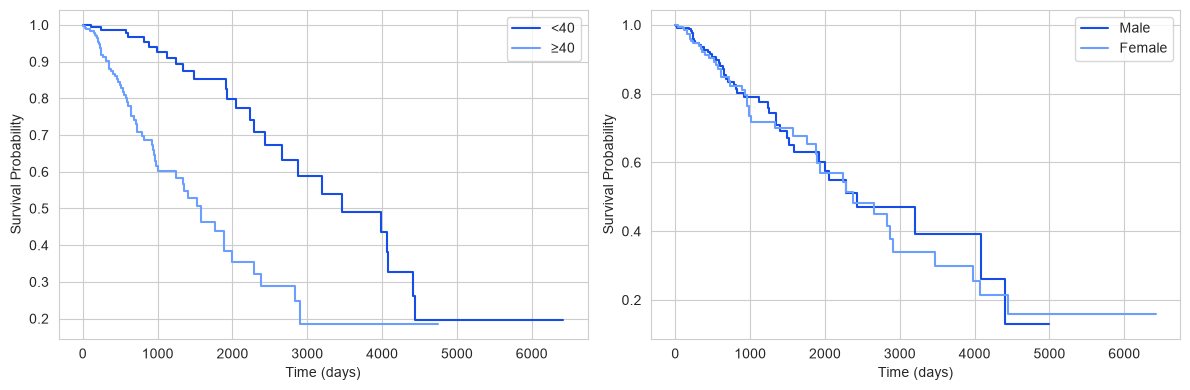

In [78]:
print(f"KM Curve by Sex: Log-rank p={lr_gender.p_value:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for (mask, label), colour in zip(
    [(merged_df["age"] < lgg_age, "<40"), (merged_df["age"] >= lgg_age, "≥40")],
    ["#154DE6", "#6B9FFF"]
):
    KaplanMeierFitter().fit(
        merged_df.loc[mask, "time"],
        event_observed=merged_df.loc[mask, "event"],
        label=label
    ).plot_survival_function(ax=axes[0], ci_show=False, color=colour)
axes[0].set_xlabel("Time (days)")
axes[0].set_ylabel("Survival Probability")
axes[0].get_legend().set_title(None)

for (val, label), colour in zip([(0, "Male"), (1, "Female")], ["#154DE6", "#6B9FFF"]):
    KaplanMeierFitter().fit(
        merged_df.loc[merged_df["gender"] == val, "time"],
        event_observed=merged_df.loc[merged_df["gender"] == val, "event"],
        label=label
    ).plot_survival_function(ax=axes[1], ci_show=False, color=colour)
axes[1].set_xlabel("Time (days)")
axes[1].set_ylabel("Survival Probability")
axes[1].get_legend().set_title(None)

plt.tight_layout()
plt.show()

### Somatic Mutation

In [79]:
mutation_cols = merged_mutation_df.columns

results = []

for gene in mutation_cols:
    not_mut = merged_df[merged_df[gene] == 0]
    mut = merged_df[merged_df[gene] == 1]

    min_n = int(0.05 * len(merged_df))
    if len(mut) < min_n:
        continue

    ct = pd.crosstab(merged_df[gene], merged_df["event"])
    if ct.shape != (2, 2):
        continue

    _, p_event = fisher_exact(ct)
    _, p_time = mannwhitneyu(not_mut["time"], mut["time"], alternative="two-sided")
    lr = logrank_test(
        not_mut["time"], mut["time"],
        event_observed_A=not_mut["event"],
        event_observed_B=mut["event"]
    )

    results.append({
        "Mutation": gene,
        "N Mutated": len(mut),
        "% Event (Not Mutated)": round(ct.loc[0, 1] / ct.loc[0].sum() * 100, 1),
        "% Event (Mutated)": round(ct.loc[1, 1] / ct.loc[1].sum() * 100, 1),
        "p_event (Fisher)": round(p_event, 4),
        "p_time (MWU)": round(p_time, 4),
        "p_logrank": round(lr.p_value, 4),
    })

In [80]:
results_df = pd.DataFrame(results).sort_values("p_logrank")

for raw_col, q_col in [
    ("p_event (Fisher)", "q_event (FDR)"),
    ("p_time (MWU)",     "q_time (FDR)"),
    ("p_logrank",        "q_logrank (FDR)"),
]:
    _, qvals, _, _ = multipletests(results_df[raw_col], method="fdr_bh")
    results_df[q_col] = qvals.round(4)

print(results_df.to_string(index=False))

  Mutation  N Mutated  % Event (Not Mutated)  % Event (Mutated)  p_event (Fisher)  p_time (MWU)  p_logrank  q_event (FDR)  q_time (FDR)  q_logrank (FDR)
  EGFR_mut         30                   16.3               43.3            0.0008        0.0915     0.0000         0.0036        0.2059           0.0000
  IDH1_mut        387                   30.7               14.2            0.0001        0.0896     0.0000         0.0009        0.2059           0.0000
   CIC_mut        108                   19.8               11.1            0.0466        0.9961     0.0079         0.1398        0.9961           0.0237
  ATRX_mut        186                   18.1               17.7            1.0000        0.0689     0.0981         1.0000        0.2059           0.1856
   NF1_mut         28                   17.3               28.6            0.1337        0.8682     0.1031         0.3008        0.9767           0.1856
  TP53_mut        237                   18.2               17.7            0.9078 

In [81]:
def clean_gene(g):
    return g.replace('_mut', '').upper()

EGFR: Fisher exact p = 0.0008, FDR q = 0.0036
IDH1: Fisher exact p = 0.0001, FDR q = 0.0009



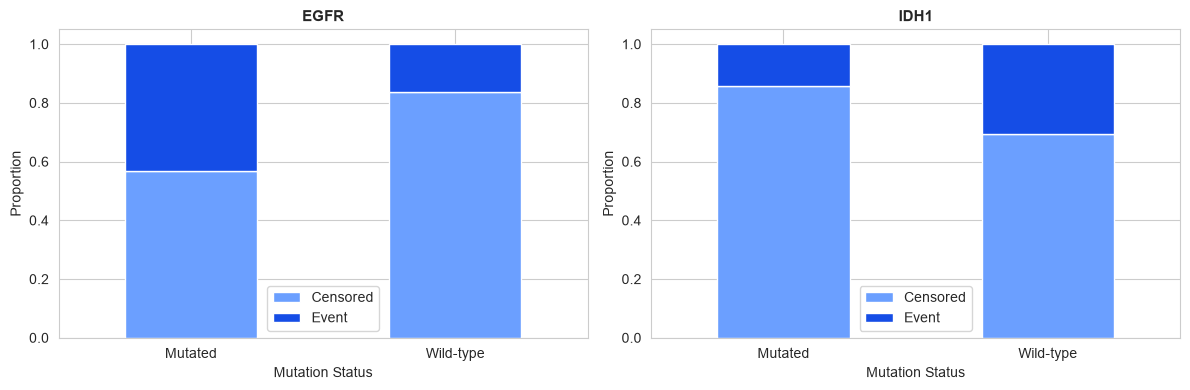

In [82]:
sig_event = results_df[results_df["q_event (FDR)"] < 0.05]["Mutation"].tolist()
n = len(sig_event)
if n == 0:
    print("No mutations significantly associated with event (Fisher exact, FDR q<0.05).")
else:
    for gene in sig_event:
        p = results_df.loc[results_df["Mutation"] == gene, "p_event (Fisher)"].values[0]
        q = results_df.loc[results_df["Mutation"] == gene, "q_event (FDR)"].values[0]
        print(f"{clean_gene(gene)}: Fisher exact p = {p:.3}, FDR q = {q:.3}")
    print()
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 4))
    if n == 1:
        axes = [axes]
    for ax, gene in zip(axes, sig_event):
        pd.crosstab(
            merged_df[gene].map({0: "Wild-type", 1: "Mutated"}),
            merged_df["event"].map(event_map),
            normalize="index"
        ).plot(kind="bar", stacked=True, ax=ax, color=["#6B9FFF", "#154DE6"])
        ax.set_title(clean_gene(gene), fontsize=11, fontweight='bold')
        ax.set_xlabel("Mutation Status")
        ax.set_ylabel("Proportion")
        ax.tick_params(axis="x", rotation=0)
        ax.get_legend().set_title(None)
    plt.tight_layout()
    plt.show()

In [83]:
sig_time = results_df[results_df["q_time (FDR)"] < 0.05]["Mutation"].tolist()
n = len(sig_time)
if n == 0:
    print("No mutations significantly associated with time (MWU, FDR q<0.05).")
else:
    for gene in sig_time:
        p = results_df.loc[results_df["Mutation"] == gene, "p_time (MWU)"].values[0]
        q = results_df.loc[results_df["Mutation"] == gene, "q_time (FDR)"].values[0]
        print(f"{clean_gene(gene)}: MWU p = {p:.3}, FDR q = {q:.3}")
    print()
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 4))
    if n == 1:
        axes = [axes]
    for ax, gene in zip(axes, sig_time):
        mut_status = merged_df[gene].map({0: "Wild-type", 1: "Mutated"})
        sns.boxplot(
            x=mut_status,
            y=merged_df["time"],
            hue=mut_status,
            palette={"Wild-type": "#154DE6", "Mutated": "#154DE6"},
            legend=False,
            ax=ax
        )
        ax.set_title(clean_gene(gene), fontsize=11, fontweight='bold')
        ax.set_xlabel("Mutation Status")
        ax.set_ylabel("Time (days)")
    plt.tight_layout()
    plt.show()

No mutations significantly associated with time (MWU, FDR q<0.05).


In [84]:
plot_mutations = list(dict.fromkeys(
    results_df[results_df["q_logrank (FDR)"] < 0.05]["Mutation"].tolist()
))

for gene in plot_mutations:
    lr = logrank_test(
        merged_df.loc[merged_df[gene] == 0, "time"],
        merged_df.loc[merged_df[gene] == 1, "time"],
        event_observed_A=merged_df.loc[merged_df[gene] == 0, "event"],
        event_observed_B=merged_df.loc[merged_df[gene] == 1, "event"]
    )
    q = results_df.loc[results_df["Mutation"] == gene, "q_logrank (FDR)"].values[0]
    print(f"{clean_gene(gene)}: log-rank p = {lr.p_value:.3}, FDR q = {q:.3}")

EGFR: log-rank p = 9.54e-07, FDR q = 0.0
IDH1: log-rank p = 6.6e-09, FDR q = 0.0
CIC: log-rank p = 0.00786, FDR q = 0.0237


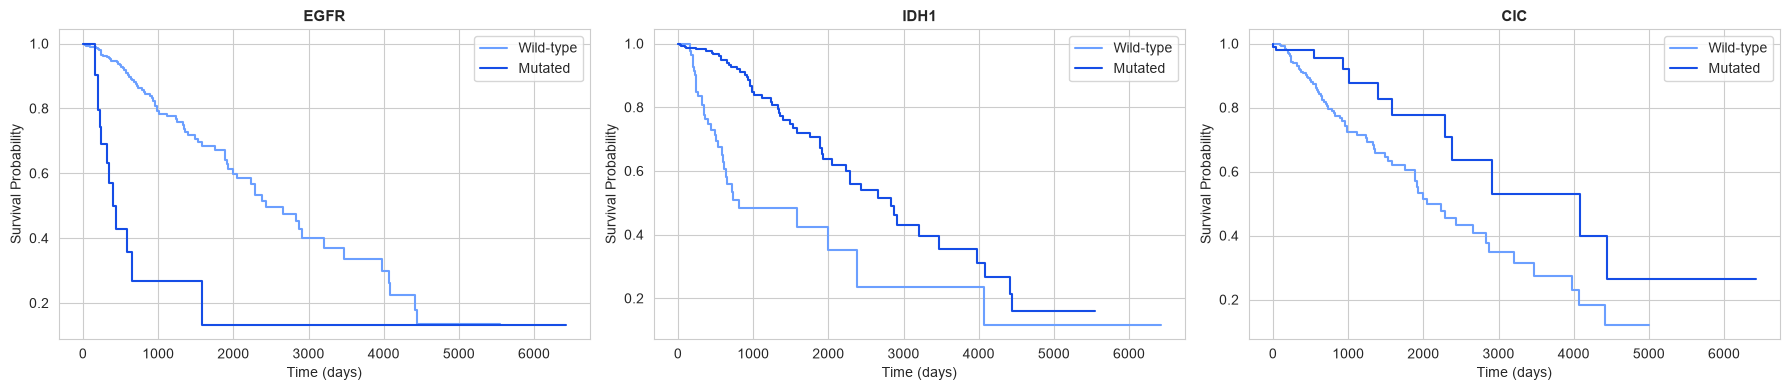

In [85]:
print()

n = len(plot_mutations)
fig, axes = plt.subplots(1, n, figsize=(6 * n, 4))
if n == 1:
    axes = [axes]

for ax, gene in zip(axes, plot_mutations):
    for (val, label), colour in zip(
        [(0, "Wild-type"), (1, "Mutated")],
        ["#6B9FFF", "#154DE6"]
    ):
        KaplanMeierFitter().fit(
            merged_df.loc[merged_df[gene] == val, "time"],
            event_observed=merged_df.loc[merged_df[gene] == val, "event"],
            label=label
        ).plot_survival_function(ax=ax, ci_show=False, color=colour)
    ax.set_title(clean_gene(gene), fontsize=11, fontweight='bold')
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Survival Probability")
    ax.get_legend().set_title(None)

plt.tight_layout()
plt.show()

### Gene Expression

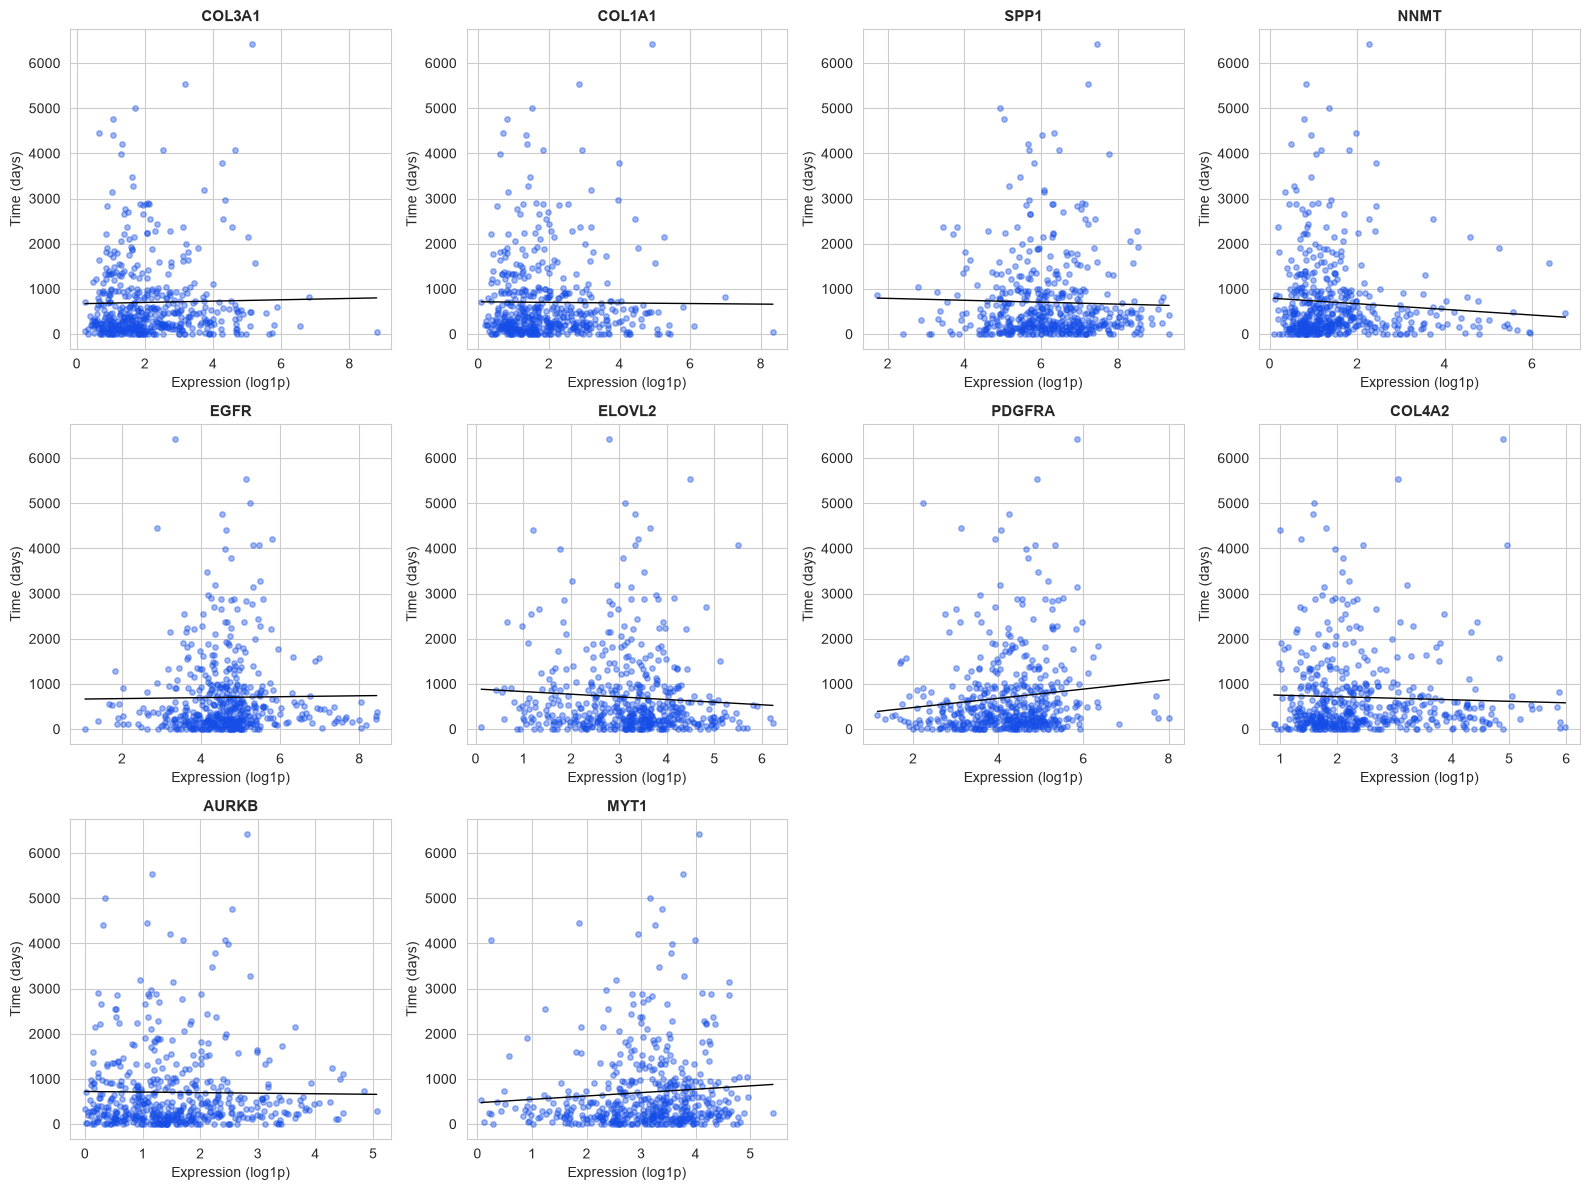

In [86]:
exp_genes = merged_expression_df.var().sort_values(ascending=False).head(10).index.tolist()
available  = [g for g in exp_genes if g in merged_expression_df.columns]
n          = len(available)
ncols      = min(n, 4)
nrows      = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = np.array(axes).flatten()

for ax, gene in zip(axes, available):
    ax.scatter(
        merged_expression_df.loc[merged_df.index, gene],
        merged_df["time"],
        alpha=0.4, s=15, color="#154DE6"
    )
    x = merged_expression_df.loc[merged_df.index, gene].values
    y = merged_df["time"].values
    m, b = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, m * x_line + b, color="black", linewidth=1)
    ax.set_xlabel("Expression (log1p)")
    ax.set_ylabel("Time (days)")
    ax.set_title(gene.replace("_exp", ""), fontsize=11, fontweight="bold")

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

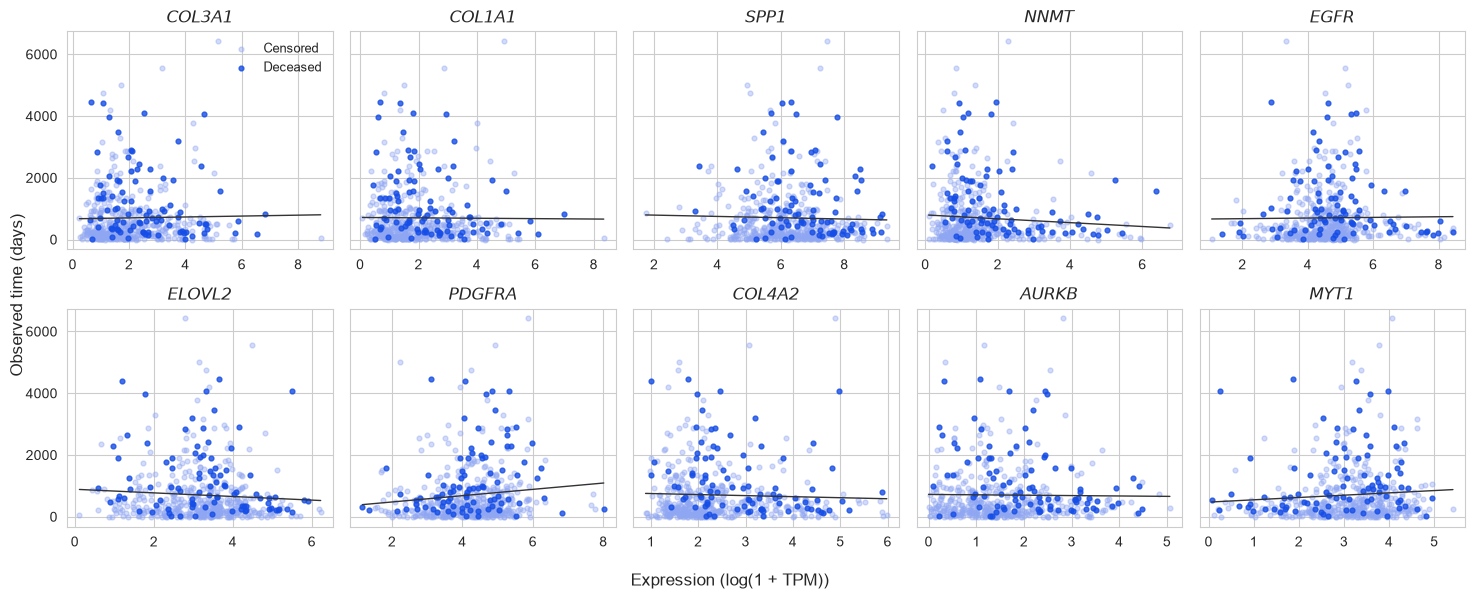

In [87]:
COLOUR, LIGHT = "#154DE6", "#8FA6F2"

exp_genes = merged_expression_df.var().sort_values(ascending=False).head(10).index.tolist()
expr  = merged_expression_df.loc[merged_df.index]
time  = merged_df["time"]
event = merged_df["event"].astype(bool)

fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharey=True)

for ax, gene in zip(axes.flat, exp_genes):
    x = expr[gene]
    ax.scatter(x[~event], time[~event], s=12, alpha=0.4, color=LIGHT, label="Censored", zorder=1)
    ax.scatter(x[event],  time[event],  s=12, alpha=0.8, color=COLOUR, label="Deceased", zorder=2)
    m, b = np.polyfit(x, time, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, m * x_line + b, color="#333333", lw=1, zorder=3)
    ax.set_title(f"$\\it{{{gene.replace('_exp', '')}}}$", fontweight="bold")

axes[0, 0].legend(frameon=False, loc="upper right", fontsize=9)
fig.supxlabel("Expression (log(1 + TPM))")
fig.supylabel("Observed time (days)")
plt.tight_layout()
plt.show()

# Models (Original Features)

## Statistical Models

### Logistic Regression

In [88]:
assert merged_df.index.equals(merged_mutation_df.index)
assert merged_df.index.equals(merged_expression_df.index)

In [89]:
y = merged_df["event"]

clinical_log = merged_df[["gender", "age"]].copy()
mutation_log = merged_mutation_df.copy()
expression_log = merged_expression_df.copy()

In [90]:
model_1_log = clinical_log
model_2_log = pd.concat([clinical_log, mutation_log], axis=1)
model_3_log = pd.concat([clinical_log, expression_log], axis=1)
model_4_log = pd.concat([clinical_log, mutation_log, expression_log], axis=1)

In [91]:
def cv_logreg(X, y, n_splits=5, return_folds=False):
    outer_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    aucs, train_aucs, tprs, best_params_list = [], [], [], []
    mean_fpr = np.linspace(0, 1, 100)
    param_grid = {
        "C": np.logspace(-4, 2, 10),
        "class_weight": [None, "balanced"],
        "l1_ratio": [0.0, 0.5, 1.0]   
    }
    all_y_true, all_y_pred = [], []

    for train_idx, test_idx in outer_cv.split(X, y):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        low_var = X_train.var(axis=0) < 0.01
        X_train = X_train.loc[:, ~low_var]
        X_test = X_test.loc[:, ~low_var]
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        inner_model = GridSearchCV(
            LogisticRegression(solver="saga", max_iter=5000, random_state=42),
            param_grid, scoring="roc_auc", cv=3, n_jobs=2,
        )
        inner_model.fit(X_train, y_train)
        best_params_list.append(inner_model.best_params_)
        preds = inner_model.best_estimator_.predict_proba(X_test)[:, 1]
        aucs.append(roc_auc_score(y_test, preds))
        train_preds = inner_model.best_estimator_.predict_proba(X_train)[:, 1]
        train_aucs.append(roc_auc_score(y_train, train_preds))
        fpr, tpr, _ = roc_curve(y_test, preds)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        all_y_true.extend(y_test)
        all_y_pred.extend(inner_model.best_estimator_.predict(X_test))

    mean_C = np.mean([p["C"] for p in best_params_list])
    if return_folds:
        return np.mean(aucs), np.mean(train_aucs), np.std(aucs), np.std(train_aucs), mean_fpr, np.mean(tprs, axis=0), mean_C, best_params_list, np.array(aucs), all_y_true, all_y_pred
    return np.mean(aucs), np.mean(train_aucs), np.std(aucs), np.std(train_aucs),mean_fpr, np.mean(tprs, axis=0), mean_C, best_params_list, all_y_true, all_y_pred

In [92]:
auc_1_log, train_auc_1_log, std_1_log, train_std_1_log, fpr_1_log, tpr_1_log, C_1_log, params_1_log, yt_1, yp_1 = cv_logreg(model_1_log, y)
auc_2_log, train_auc_2_log, std_2_log, train_std_2_log, fpr_2_log, tpr_2_log, C_2_log, params_2_log, yt_2, yp_2 = cv_logreg(model_2_log, y)
auc_3_log, train_auc_3_log, std_3_log, train_std_3_log, fpr_3_log, tpr_3_log, C_3_log, params_3_log, yt_3, yp_3 = cv_logreg(model_3_log, y)
auc_4_log, train_auc_4_log, std_4_log, train_std_4_log, fpr_4_log, tpr_4_log, C_4_log, params_4_log, yt_4, yp_4 = cv_logreg(model_4_log, y)

results_cv_logreg = {
    "Model 1": (auc_1_log, train_auc_1_log, std_1_log, train_std_1_log, fpr_1_log, tpr_1_log, C_1_log, params_1_log),
    "Model 2": (auc_2_log, train_auc_2_log, std_2_log, train_std_2_log, fpr_2_log, tpr_2_log, C_2_log, params_2_log),
    "Model 3": (auc_3_log, train_auc_3_log, std_3_log, train_std_3_log, fpr_3_log, tpr_3_log, C_3_log, params_3_log),
    "Model 4": (auc_4_log, train_auc_4_log, std_4_log, train_std_4_log, fpr_4_log, tpr_4_log, C_4_log, params_4_log),
}

In [93]:
for name, test_auc, test_std, train_auc, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [auc_1_log, auc_2_log, auc_3_log, auc_4_log],
    [std_1_log, std_2_log, std_3_log, std_4_log],
    [train_auc_1_log, train_auc_2_log, train_auc_3_log, train_auc_4_log],
    [train_std_1_log, train_std_2_log, train_std_3_log, train_std_4_log],
):
    print(f"{name}: Test AUC={test_auc:.3f} +/- {test_std:.3f} | Train AUC={train_auc:.3f} +/- {train_std:.3f}")

Model 1: Test AUC=0.644 +/- 0.071 | Train AUC=0.652 +/- 0.018
Model 2: Test AUC=0.652 +/- 0.027 | Train AUC=0.703 +/- 0.010
Model 3: Test AUC=0.738 +/- 0.022 | Train AUC=0.783 +/- 0.026
Model 4: Test AUC=0.736 +/- 0.023 | Train AUC=0.824 +/- 0.038


In [94]:
for name, result in results_cv_logreg.items():
    print(f"\n{name} best params per fold:")
    for params in result[-1]: 
        print(params)


Model 1 best params per fold:
{'C': np.float64(1.0), 'class_weight': None, 'l1_ratio': 0.5}
{'C': np.float64(0.046415888336127774), 'class_weight': None, 'l1_ratio': 0.5}
{'C': np.float64(1.0), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(1.0), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(0.21544346900318823), 'class_weight': None, 'l1_ratio': 0.0}

Model 2 best params per fold:
{'C': np.float64(0.01), 'class_weight': 'balanced', 'l1_ratio': 0.0}
{'C': np.float64(0.01), 'class_weight': 'balanced', 'l1_ratio': 0.0}
{'C': np.float64(21.54434690031882), 'class_weight': 'balanced', 'l1_ratio': 0.0}
{'C': np.float64(1.0), 'class_weight': None, 'l1_ratio': 0.5}
{'C': np.float64(0.21544346900318823), 'class_weight': 'balanced', 'l1_ratio': 0.5}

Model 3 best params per fold:
{'C': np.float64(0.0001), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(0.046415888336127774), 'class_weight': None, 'l1_ratio': 0.5}
{'C': np.float64(0.00046415888336127773), 'class_weigh

In [95]:
def fit_final_logreg(X, y):
    low_var = X.var(axis=0) < 0.01
    kept_cols = X.columns[~low_var]
    X_filtered = X.loc[:, ~low_var]
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_filtered)
    param_grid = {
        "C": np.logspace(-4, 2, 10),
        "class_weight": [None, "balanced"],
        "l1_ratio": [0.0, 0.5, 1.0]
    }
    search = GridSearchCV(
        LogisticRegression(solver="saga", max_iter=5000, random_state=42),
        param_grid,
        scoring="roc_auc",
        cv=5,
        n_jobs=2,
    )
    search.fit(X_scaled, y)
    model = search.best_estimator_
    best_params = search.best_params_
    y_pred_proba = model.predict_proba(X_scaled)[:, 1]
    auc = roc_auc_score(y, y_pred_proba)
    coef_df = pd.DataFrame({
        "feature": kept_cols,
        "coef": model.coef_[0]
    })
    coef_df["odds_ratio"] = np.exp(coef_df["coef"])
    return model, coef_df, auc, best_params, scaler, kept_cols

In [96]:
results_final_logreg = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [model_1_log, model_2_log, model_3_log, model_4_log]
):
    model, coef_df, auc, best_params, scaler, kept_cols = fit_final_logreg(X, y)
    results_final_logreg[name] = (model, coef_df, auc, best_params, scaler, kept_cols)

### Cox Proportional Hazards

In [97]:
y_surv = np.array(
    [(bool(e), float(t)) for e, t in zip(merged_df["event"], merged_df["time"])],
    dtype=[("event", bool), ("time", float)]
)

In [98]:
clinical_cph = merged_df[["gender", "age"]].copy()
mutation_cph = merged_mutation_df.copy()
expression_cph = merged_expression_df.copy()

In [99]:
model_1_cph = clinical_cph
model_2_cph = pd.concat([clinical_cph, mutation_cph], axis=1)
model_3_cph = pd.concat([clinical_cph, expression_cph], axis=1)
model_4_cph = pd.concat([clinical_cph, mutation_cph, expression_cph], axis=1)

In [100]:
warnings.filterwarnings("ignore")

def cv_cph(X, y_surv, n_splits=5, return_folds=False):
    events = y_surv["event"].astype(int)
    outer_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    c_indices, train_c_indices, best_params_list = [], [], []
    param_grid = {
        "alphas": [[a] for a in np.logspace(-4, 0, 10)],
        "l1_ratio": [0.01, 0.5, 1.0],
    }

    for train_idx, test_idx in outer_cv.split(X, events):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_surv[train_idx], y_surv[test_idx]
        low_var = X_train.var(axis=0) < 0.01
        X_train = X_train.loc[:, ~low_var]
        X_test = X_test.loc[:, ~low_var]
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        inner_model = GridSearchCV(
            CoxnetSurvivalAnalysis(fit_baseline_model=True, max_iter=100000),
            param_grid, cv=3, n_jobs=-1, error_score=np.nan,
        )
        inner_model.fit(X_train, y_train)
        best_params_list.append(inner_model.best_params_)
        best_model = inner_model.best_estimator_
        c_indices.append(best_model.score(X_test, y_test))
        train_c_indices.append(best_model.score(X_train, y_train))

    mean_alpha = np.mean([p["alphas"][0] for p in best_params_list])
    if return_folds:
        return np.mean(c_indices), np.mean(train_c_indices), np.std(c_indices), np.std(train_c_indices), mean_alpha, best_params_list, np.array(c_indices)
    return np.mean(c_indices), np.mean(train_c_indices), np.std(c_indices), np.std(train_c_indices), mean_alpha, best_params_list

In [101]:
c_1_cph, train_c_1_cph, std_1_cph, train_std_1_cph, alpha_1_cph, params_1_cph = cv_cph(model_1_cph, y_surv)
c_2_cph, train_c_2_cph, std_2_cph, train_std_2_cph, alpha_2_cph, params_2_cph = cv_cph(model_2_cph, y_surv)
c_3_cph, train_c_3_cph, std_3_cph, train_std_3_cph, alpha_3_cph, params_3_cph = cv_cph(model_3_cph, y_surv)
c_4_cph, train_c_4_cph, std_4_cph, train_std_4_cph, alpha_4_cph, params_4_cph = cv_cph(model_4_cph, y_surv)

results_cv_cph = {
    "Model 1": (c_1_cph, train_c_1_cph, std_1_cph, train_std_1_cph, alpha_1_cph, params_1_cph),
    "Model 2": (c_2_cph, train_c_2_cph, std_2_cph, train_std_2_cph, alpha_2_cph, params_2_cph),
    "Model 3": (c_3_cph, train_c_3_cph, std_3_cph, train_std_3_cph, alpha_3_cph, params_3_cph),
    "Model 4": (c_4_cph, train_c_4_cph, std_4_cph, train_std_4_cph, alpha_4_cph, params_4_cph),
}

In [102]:
for name, test_c, test_std, train_c, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [c_1_cph, c_2_cph, c_3_cph, c_4_cph],
    [std_1_cph, std_2_cph, std_3_cph, std_4_cph],
    [train_c_1_cph, train_c_2_cph, train_c_3_cph, train_c_4_cph],
    [train_std_1_cph, train_std_2_cph, train_std_3_cph, train_std_4_cph],
):
    print(f"{name}: Test C-Index={test_c:.3f} +/- {test_std:.3f} | Train C-Index={train_c:.3f} +/- {train_std:.3f}")

Model 1: Test C-Index=0.786 +/- 0.053 | Train C-Index=0.780 +/- 0.013
Model 2: Test C-Index=0.807 +/- 0.040 | Train C-Index=0.818 +/- 0.011
Model 3: Test C-Index=0.855 +/- 0.023 | Train C-Index=0.881 +/- 0.011
Model 4: Test C-Index=0.844 +/- 0.031 | Train C-Index=0.886 +/- 0.020


In [103]:
for name, result in results_cv_cph.items():
    print(f"\n{name} best params per fold:")
    for params in result[-1]:
        print(params)


Model 1 best params per fold:
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 1.0}
{'alphas': [np.float64(0.016681005372000592)], 'l1_ratio': 1.0}
{'alphas': [np.float64(1.0)], 'l1_ratio': 0.01}
{'alphas': [np.float64(0.005994842503189409)], 'l1_ratio': 1.0}

Model 2 best params per fold:
{'alphas': [np.float64(0.016681005372000592)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.016681005372000592)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.016681005372000592)], 'l1_ratio': 1.0}
{'alphas': [np.float64(0.016681005372000592)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.016681005372000592)], 'l1_ratio': 1.0}

Model 3 best params per fold:
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.12915496650148828)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.046

In [104]:
def fit_final_cph(X, y_surv):
    low_var = X.var(axis=0) < 0.01
    kept_cols = X.columns[~low_var]
    X_filtered = X.loc[:, ~low_var]
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_filtered)
    param_grid = {
        "alphas": [[a] for a in np.logspace(-4, 0, 10)],
        "l1_ratio": [0.01, 0.5, 1.0],
    }
    search = GridSearchCV(
        CoxnetSurvivalAnalysis(fit_baseline_model=True, max_iter=100000),
        param_grid,
        cv=5,
        n_jobs=2,
        error_score=np.nan,
    )
    search.fit(X_scaled, y_surv)
    model = search.best_estimator_
    best_params = search.best_params_
    coef_df = pd.DataFrame({
        "feature": kept_cols,
        "coef": model.coef_.ravel(),
    })
    coef_df["hazard_ratio"] = np.exp(coef_df["coef"])
    c_index = model.score(X_scaled, y_surv)
    return model, coef_df, c_index, best_params, scaler, kept_cols

In [105]:
results_final_cph = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [model_1_cph, model_2_cph, model_3_cph, model_4_cph]
):
    model, coef_df, c_index, best_params, scaler, kept_cols = fit_final_cph(X, y_surv)
    results_final_cph[name] = (model, coef_df, c_index, best_params, scaler, kept_cols)

## Machine Learning Models

### Random Survival Forest

In [106]:
model_1_rsf = model_1_cph
model_2_rsf = model_2_cph
model_3_rsf = model_3_cph
model_4_rsf = model_4_cph

In [107]:
def cv_rsf(X, y_surv, n_splits=5, return_folds=False):
    events = y_surv["event"].astype(int)
    outer_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    c_indices = []
    train_c_indices = []
    best_params_list = []

    param_grid = {
        "max_depth": [None, 3, 5, 7],
        "min_samples_leaf": [5, 10, 15, 20],
        "max_features": ["sqrt", "log2", 0.3],
    }

    for train_idx, test_idx in outer_cv.split(X, events):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_surv[train_idx], y_surv[test_idx]

        low_var = X_train.var(axis=0) < 0.01
        X_train = X_train.loc[:, ~low_var]
        X_test = X_test.loc[:, ~low_var]

        inner_model = GridSearchCV(
            RandomSurvivalForest(n_estimators=100, random_state=42, n_jobs=1),
            param_grid,
            cv=3,
            n_jobs=-1,
        )
        inner_model.fit(X_train, y_train)
        best_params_list.append(inner_model.best_params_)
        best_model = inner_model.best_estimator_
        c_indices.append(best_model.score(X_test, y_test))
        train_c_indices.append(best_model.score(X_train, y_train))

    if return_folds:
        return np.mean(c_indices), np.mean(train_c_indices), np.std(c_indices), np.std(train_c_indices), best_params_list, np.array(c_indices)
    return np.mean(c_indices), np.mean(train_c_indices), np.std(c_indices), np.std(train_c_indices), best_params_list

In [108]:
c_1_rsf, train_c_1_rsf, std_1_rsf, train_std_1_rsf, params_1_rsf = cv_rsf(model_1_rsf, y_surv)
c_2_rsf, train_c_2_rsf, std_2_rsf, train_std_2_rsf, params_2_rsf = cv_rsf(model_2_rsf, y_surv)
c_3_rsf, train_c_3_rsf, std_3_rsf, train_std_3_rsf, params_3_rsf = cv_rsf(model_3_rsf, y_surv)
c_4_rsf, train_c_4_rsf, std_4_rsf, train_std_4_rsf, params_4_rsf = cv_rsf(model_4_rsf, y_surv)

results_cv_rsf = {
    "Model 1": (c_1_rsf, train_c_1_rsf, std_1_rsf, train_std_1_rsf, params_1_rsf),
    "Model 2": (c_2_rsf, train_c_2_rsf, std_2_rsf, train_std_2_rsf, params_2_rsf),
    "Model 3": (c_3_rsf, train_c_3_rsf, std_3_rsf, train_std_3_rsf, params_3_rsf),
    "Model 4": (c_4_rsf, train_c_4_rsf, std_4_rsf, train_std_4_rsf, params_4_rsf),
}

In [109]:
for name, test_c, test_std, train_c, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [c_1_rsf, c_2_rsf, c_3_rsf, c_4_rsf],
    [std_1_rsf, std_2_rsf, std_3_rsf, std_4_rsf],
    [train_c_1_rsf, train_c_2_rsf, train_c_3_rsf, train_c_4_rsf],
    [train_std_1_rsf, train_std_2_rsf, train_std_3_rsf, train_std_4_rsf],
):
    print(f"{name}: Test C-Index={test_c:.3f} +/- {test_std:.3f} | Train C-Index={train_c:.3f} +/- {train_std:.3f}")

Model 1: Test C-Index=0.745 +/- 0.077 | Train C-Index=0.853 +/- 0.015
Model 2: Test C-Index=0.815 +/- 0.037 | Train C-Index=0.862 +/- 0.023
Model 3: Test C-Index=0.821 +/- 0.058 | Train C-Index=0.910 +/- 0.009
Model 4: Test C-Index=0.813 +/- 0.052 | Train C-Index=0.902 +/- 0.005


In [110]:
for name, (_, _, _, _, best_params_list) in results_cv_rsf.items():
    print(f"\n{name} best params per fold:")
    for params in best_params_list:
        print(params)


Model 1 best params per fold:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 10}
{'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}

Model 2 best params per fold:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 10}
{'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 5}

Model 3 best params per fold:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 20}
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 15}
{'max_depth': 7, 'max_features': 'log2', 'min_samples_leaf': 10}
{'max_depth': 3, 'max_features': 'log2', 'min_samples_l

In [111]:
def fit_final_rsf(X, y_surv):
    low_var = X.var(axis=0) < 0.01
    kept_cols = X.columns[~low_var]
    X_filtered = X.loc[:, ~low_var]

    param_grid = {
        "max_depth": [None, 3, 5, 7],
        "min_samples_leaf": [5, 10, 15, 20],
        "max_features": ["sqrt", "log2", 0.3],
    }
    search = GridSearchCV(
        RandomSurvivalForest(n_estimators=100, random_state=42, n_jobs=1),
        param_grid,
        cv=5,
        n_jobs=-1,
    )
    search.fit(X_filtered, y_surv)
    model = search.best_estimator_

    perm_result = permutation_importance(
        model, X_filtered, y_surv, n_repeats=15, random_state=42, n_jobs=-1
    )
    importance_df = pd.DataFrame({
        "feature": kept_cols,
        "importance": perm_result.importances_mean,
    }).sort_values("importance", ascending=False)

    c_index = model.score(X_filtered, y_surv)
    best_params = search.best_params_

    return model, importance_df, c_index, best_params, kept_cols

In [112]:
results_final_rsf = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [model_1_rsf, model_2_rsf, model_3_rsf, model_4_rsf]
):
    model, importance_df, c_index, best_params, kept_cols = fit_final_rsf(X, y_surv)
    results_final_rsf[name] = (model, importance_df, c_index, best_params, kept_cols)

### Gradient Boosting

In [113]:
model_1_gbm = model_1_cph
model_2_gbm = model_2_cph
model_3_gbm = model_3_cph
model_4_gbm = model_4_cph

In [114]:
def cv_gbm(X, y_surv, n_splits=5, return_folds=False):
    events = y_surv["event"].astype(int)
    outer_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    c_indices = []
    train_c_indices = []
    best_params_list = []
    param_grid = {
        "learning_rate": [0.01, 0.05, 0.1],
        "max_depth": [2, 3, 5],
        "subsample": [0.6, 0.8, 1.0],
        "min_samples_leaf": [5, 10, 15, 20],
        "max_features": ["sqrt", "log2", 0.3],
    }

    for train_idx, test_idx in outer_cv.split(X, events):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_surv[train_idx], y_surv[test_idx]

        low_var = X_train.var(axis=0) < 0.01
        X_train = X_train.loc[:, ~low_var]
        X_test = X_test.loc[:, ~low_var]
        inner_model = GridSearchCV(
            GradientBoostingSurvivalAnalysis(n_estimators=100, random_state=42),
            param_grid,
            cv=3,
            n_jobs=-1,
        )
        inner_model.fit(X_train, y_train)
        best_params_list.append(inner_model.best_params_)
        best_model = inner_model.best_estimator_
        c_indices.append(best_model.score(X_test, y_test))
        train_c_indices.append(best_model.score(X_train, y_train))

    if return_folds:
        return np.mean(c_indices), np.mean(train_c_indices), np.std(c_indices), np.std(train_c_indices), best_params_list, np.array(c_indices)
    return np.mean(c_indices), np.mean(train_c_indices), np.std(c_indices), np.std(train_c_indices), best_params_list

In [115]:
c_1_gbm, train_c_1_gbm, std_1_gbm, train_std_1_gbm, params_1_gbm = cv_gbm(model_1_gbm, y_surv)
c_2_gbm, train_c_2_gbm, std_2_gbm, train_std_2_gbm, params_2_gbm = cv_gbm(model_2_gbm, y_surv)
c_3_gbm, train_c_3_gbm, std_3_gbm, train_std_3_gbm, params_3_gbm = cv_gbm(model_3_gbm, y_surv)
c_4_gbm, train_c_4_gbm, std_4_gbm, train_std_4_gbm, params_4_gbm = cv_gbm(model_4_gbm, y_surv)

results_cv_gbm = {
    "Model 1": (c_1_gbm, train_c_1_gbm, std_1_gbm, train_std_1_gbm, params_1_gbm),
    "Model 2": (c_2_gbm, train_c_2_gbm, std_2_gbm, train_std_2_gbm, params_2_gbm),
    "Model 3": (c_3_gbm, train_c_3_gbm, std_3_gbm, train_std_3_gbm, params_3_gbm),
    "Model 4": (c_4_gbm, train_c_4_gbm, std_4_gbm, train_std_4_gbm, params_4_gbm),
}

In [116]:
for name, test_c, test_std, train_c, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [c_1_gbm, c_2_gbm, c_3_gbm, c_4_gbm],
    [std_1_gbm, std_2_gbm, std_3_gbm, std_4_gbm],
    [train_c_1_gbm, train_c_2_gbm, train_c_3_gbm, train_c_4_gbm],
    [train_std_1_gbm, train_std_2_gbm, train_std_3_gbm, train_std_4_gbm],
):
    print(f"{name}: Test C-Index={test_c:.3f} +/- {test_std:.3f} | Train C-Index={train_c:.3f} +/- {train_std:.3f}")

Model 1: Test C-Index=0.757 +/- 0.074 | Train C-Index=0.819 +/- 0.024
Model 2: Test C-Index=0.832 +/- 0.028 | Train C-Index=0.889 +/- 0.016
Model 3: Test C-Index=0.812 +/- 0.070 | Train C-Index=0.944 +/- 0.022
Model 4: Test C-Index=0.822 +/- 0.046 | Train C-Index=0.947 +/- 0.013


In [117]:
for name, (_, _, _, _, best_params_list) in results_cv_gbm.items():
    print(f"\n{name} best params per fold:")
    for params in best_params_list:
        print(params)


Model 1 best params per fold:
{'learning_rate': 0.01, 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'subsample': 0.6}
{'learning_rate': 0.05, 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'subsample': 1.0}
{'learning_rate': 0.05, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'subsample': 1.0}
{'learning_rate': 0.1, 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'subsample': 1.0}
{'learning_rate': 0.05, 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'subsample': 0.8}

Model 2 best params per fold:
{'learning_rate': 0.05, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'subsample': 1.0}
{'learning_rate': 0.1, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'subsample': 0.8}
{'learning_rate': 0.1, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 15, 'subsample': 0.8}
{'learning_rate': 0.1, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'subsampl

In [118]:
def fit_final_gbm(X, y_surv):
    low_var = X.var(axis=0) < 0.01
    kept_cols = X.columns[~low_var]
    X_filtered = X.loc[:, ~low_var]
    param_grid = {
        "learning_rate": [0.01, 0.05, 0.1],
        "max_depth": [2, 3, 5],
        "subsample": [0.6, 0.8, 1.0],
        "min_samples_leaf": [5, 10, 15, 20],
        "max_features": ["sqrt", "log2", 0.3],
    }

    search = GridSearchCV(
        GradientBoostingSurvivalAnalysis(n_estimators=100, random_state=42),
        param_grid,
        cv=5,
        n_jobs=-1,
    )
    search.fit(X_filtered, y_surv)
    model = search.best_estimator_
    perm_result = permutation_importance(
        model, X_filtered, y_surv, n_repeats=15, random_state=42, n_jobs=-1
    )
    importance_df = pd.DataFrame({
        "feature": kept_cols,
        "importance": perm_result.importances_mean,
    }).sort_values("importance", ascending=False)
    c_index = model.score(X_filtered, y_surv)
    best_params = search.best_params_

    return model, importance_df, c_index, best_params, kept_cols

In [119]:
results_final_gbm = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [model_1_gbm, model_2_gbm, model_3_gbm, model_4_gbm]
):
    model, importance_df, c_index, best_params, kept_cols = fit_final_gbm(X, y_surv)
    results_final_gbm[name] = (model, importance_df, c_index, best_params, kept_cols)

### Artificial Neural Network

In [120]:
def cox_ph_loss(risk, time, event, eps=1e-7):
    order = torch.argsort(time, descending=True)
    risk = risk[order]
    event = event[order]
    log_risk_set = torch.logcumsumexp(risk, dim=0)
    return -((risk - log_risk_set) * event).sum() / (event.sum() + eps)

In [121]:
class DeepSurvNet(nn.Module):
    def __init__(self, input_dim, hidden_dim=16, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

In [122]:
class DeepSurv(BaseEstimator):
    def __init__(self, hidden_dim=16, dropout=0.4, weight_decay=1e-3, lr=1e-3, n_epochs=100, random_state=42):
        self.hidden_dim = hidden_dim
        self.dropout = dropout
        self.weight_decay = weight_decay
        self.lr = lr
        self.n_epochs = n_epochs
        self.random_state = random_state

    def fit(self, X, y_surv):
        torch.manual_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        time = y_surv["time"].astype(np.float32)
        event = y_surv["event"].astype(np.float32)

        self.scaler_ = StandardScaler()
        X_scaled = self.scaler_.fit_transform(X)

        X_t = torch.tensor(X_scaled, dtype=torch.float32)
        time_t = torch.tensor(time, dtype=torch.float32)
        event_t = torch.tensor(event, dtype=torch.float32)

        self.model_ = DeepSurvNet(X_t.shape[1], self.hidden_dim, self.dropout)
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)

        self.model_.train()
        self.loss_history_ = []

        for _ in range(self.n_epochs):
            optimizer.zero_grad()
            risk = self.model_(X_t)
            loss = cox_ph_loss(risk, time_t, event_t)
            loss.backward()
            optimizer.step()
            self.loss_history_.append(loss.item())
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        X_scaled = self.scaler_.transform(X)
        X_t = torch.tensor(X_scaled, dtype=torch.float32)
        self.model_.eval()
        with torch.no_grad():
            risk = self.model_(X_t).numpy()
        return risk

    def score(self, X, y_surv):
        risk = self.predict(X)
        c_index = concordance_index_censored(
            y_surv["event"].astype(bool), y_surv["time"], risk
        )[0]
        return c_index

In [123]:
model_1_ann = model_1_cph
model_2_ann = model_2_cph
model_3_ann = model_3_cph
model_4_ann = model_4_cph

In [124]:
def cv_ann(X, y_surv, n_splits=5, return_folds=False):
    events = y_surv["event"].astype(int)
    outer_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    c_indices = []
    train_c_indices = []
    best_params_list = []
    param_grid = {
        "hidden_dim": [8, 16],
        "dropout": [0.3, 0.5],
        "weight_decay": [1e-3, 1e-2],
    }
    for train_idx, test_idx in outer_cv.split(X, events):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_surv[train_idx], y_surv[test_idx]

        low_var = X_train.var(axis=0) < 0.01
        X_train = X_train.loc[:, ~low_var]
        X_test = X_test.loc[:, ~low_var]
        inner_model = GridSearchCV(
            DeepSurv(lr=1e-3, n_epochs=100, random_state=42),
            param_grid,
            cv=3,
            n_jobs=1,
        )
        inner_model.fit(X_train, y_train)
        best_params_list.append(inner_model.best_params_)
        best_model = inner_model.best_estimator_
        c_indices.append(best_model.score(X_test, y_test))
        train_c_indices.append(best_model.score(X_train, y_train))

    if return_folds:
        return np.mean(c_indices), np.mean(train_c_indices), np.std(c_indices), np.std(train_c_indices), best_params_list, np.array(c_indices)
    return np.mean(c_indices), np.mean(train_c_indices), np.std(c_indices), np.std(train_c_indices), best_params_list

In [125]:
c_1_ann, train_c_1_ann, std_1_ann, train_std_1_ann, params_1_ann = cv_ann(model_1_ann, y_surv)
c_2_ann, train_c_2_ann, std_2_ann, train_std_2_ann, params_2_ann = cv_ann(model_2_ann, y_surv)
c_3_ann, train_c_3_ann, std_3_ann, train_std_3_ann, params_3_ann = cv_ann(model_3_ann, y_surv)
c_4_ann, train_c_4_ann, std_4_ann, train_std_4_ann, params_4_ann = cv_ann(model_4_ann, y_surv)

results_cv_ann = {
    "Model 1": (c_1_ann, train_c_1_ann, std_1_ann, train_std_1_ann, params_1_ann),
    "Model 2": (c_2_ann, train_c_2_ann, std_2_ann, train_std_2_ann, params_2_ann),
    "Model 3": (c_3_ann, train_c_3_ann, std_3_ann, train_std_3_ann, params_3_ann),
    "Model 4": (c_4_ann, train_c_4_ann, std_4_ann, train_std_4_ann, params_4_ann),
}

In [126]:
for name, test_c, test_std, train_c, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [c_1_ann, c_2_ann, c_3_ann, c_4_ann],
    [std_1_ann, std_2_ann, std_3_ann, std_4_ann],
    [train_c_1_ann, train_c_2_ann, train_c_3_ann, train_c_4_ann],
    [train_std_1_ann, train_std_2_ann, train_std_3_ann, train_std_4_ann],
):
    print(f"{name}: Test C-Index={test_c:.3f} +/- {test_std:.3f} | Train C-Index={train_c:.3f} +/- {train_std:.3f}")

Model 1: Test C-Index=0.778 +/- 0.063 | Train C-Index=0.781 +/- 0.010
Model 2: Test C-Index=0.763 +/- 0.047 | Train C-Index=0.791 +/- 0.018
Model 3: Test C-Index=0.800 +/- 0.056 | Train C-Index=0.863 +/- 0.011
Model 4: Test C-Index=0.806 +/- 0.049 | Train C-Index=0.878 +/- 0.004


In [127]:
for name, (_, _, _, _, best_params_list) in results_cv_ann.items():
    print(f"\n{name} best params per fold:")
    for params in best_params_list:
        print(params)


Model 1 best params per fold:
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.5, 'hidden_dim': 8, 'weight_decay': 0.001}
{'dropout': 0.5, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.001}

Model 2 best params per fold:
{'dropout': 0.3, 'hidden_dim': 8, 'weight_decay': 0.01}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.5, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.01}

Model 3 best params per fold:
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.01}
{'dropout': 0.5, 'hidden_dim': 16, 'weight_decay': 0.01}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.01}
{'dropout': 0.3, 'hidden_dim': 8, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.01}

Model 4 best params per fold:
{'dropout': 0.3

In [128]:
def fit_final_ann(X, y_surv):
    low_var = X.var(axis=0) < 0.01
    kept_cols = X.columns[~low_var]
    X_filtered = X.loc[:, ~low_var]
    param_grid = {
        "hidden_dim": [8, 16],
        "dropout": [0.3, 0.5],
        "weight_decay": [1e-3, 1e-2],
    }
    search = GridSearchCV(
        DeepSurv(lr=1e-3, n_epochs=100, random_state=42),
        param_grid,
        cv=5,
        n_jobs=1,
    )
    search.fit(X_filtered, y_surv)
    model = search.best_estimator_
    perm_result = permutation_importance(
        model, X_filtered, y_surv, n_repeats=15, random_state=42, n_jobs=1
    )
    importance_df = pd.DataFrame({
        "feature": kept_cols,
        "importance": perm_result.importances_mean,
    }).sort_values("importance", ascending=False)
    c_index = model.score(X_filtered, y_surv)
    best_params = search.best_params_

    return model, importance_df, c_index, best_params, kept_cols

In [129]:
results_final_ann = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [model_1_ann, model_2_ann, model_3_ann, model_4_ann]
):
    model, importance_df, c_index, best_params, kept_cols = fit_final_ann(X, y_surv)
    results_final_ann[name] = (model, importance_df, c_index, best_params, kept_cols)

# Dimensionality Reduction

In [130]:
dimred_merged_df = merged_df.copy()

## Somatic Mutation

In [131]:
lgg_trio_mutations = ['TP53_mut', 'IDH1_mut', 'ATRX_mut']
not_lgg_trio = [col for col in merged_mutation_df.columns if col not in lgg_trio_mutations]
not_lgg_trio_present = [c for c in not_lgg_trio if c in dimred_merged_df.columns]
dimred_merged_df.drop(columns=not_lgg_trio_present, inplace=True)

## Gene Expression

### Pathway Gene Analysis

In [132]:
g2m_genes         = ["AURKB_exp", "RPA2_exp", "MCM5_exp", "CDC45_exp", "MCM6_exp"]
pi3k_mtor_genes   = ['MAPK1_exp', 'MAPK8_exp', 'MAP3K7_exp', 'MAP2K6_exp', 'MAPK9_exp']
hypoxia_genes     = ['ALDOC_exp', 'ALDOB_exp', 'ENO2_exp', 'ENO3_exp', 'PFKP_exp']
emt_genes         = ['COL1A2_exp', 'COL1A1_exp', 'COL5A1_exp', 'COL3A1_exp', 'COL4A2_exp']
mesenchymal_genes = ['ARPC1B_exp', 'S100A11_exp', 'CTSC_exp', 'GLIPR1_exp', 'NNMT_exp']
proneural_genes   = ['RAB33A_exp', 'HDAC2_exp', 'MYT1_exp', 'MTSS1_exp']
classical_genes   = ['PTPRA_exp', 'ELOVL2_exp', 'MLC1_exp', 'SOX9_exp', 'ARNTL_exp']
farg_genes        = ['RAP1B_exp', 'VAV3_exp', 'ZYX_exp', 'COL5A2_exp', 'SPP1_exp',
                     'COL6A1_exp', 'ITGA5_exp', 'SHC1_exp']

In [133]:
pathway_gene_map = {
    "G2M Pathway":          g2m_genes,
    "PI3K mTOR Pathway":    pi3k_mtor_genes,
    "Hypoxia Pathway":      hypoxia_genes,
    "EMT Pathway":          emt_genes,
    "Mesenchymal Pathway":  mesenchymal_genes,
    "Proneural Pathway":    proneural_genes,
    "Classical Pathway":    classical_genes,
    "FARG Pathway":         farg_genes,
}

pathway_labels = {
    "G2M Pathway":         "G2M",
    "PI3K mTOR Pathway":   "PI3K/AKT/mTOR",
    "Hypoxia Pathway":     "Hypoxia",
    "EMT Pathway":         "EMT",
    "Mesenchymal Pathway": "Mesenchymal",
    "Proneural Pathway":   "Proneural",
    "Classical Pathway":   "Classical",
    "FARG Pathway":        "FARG",
}

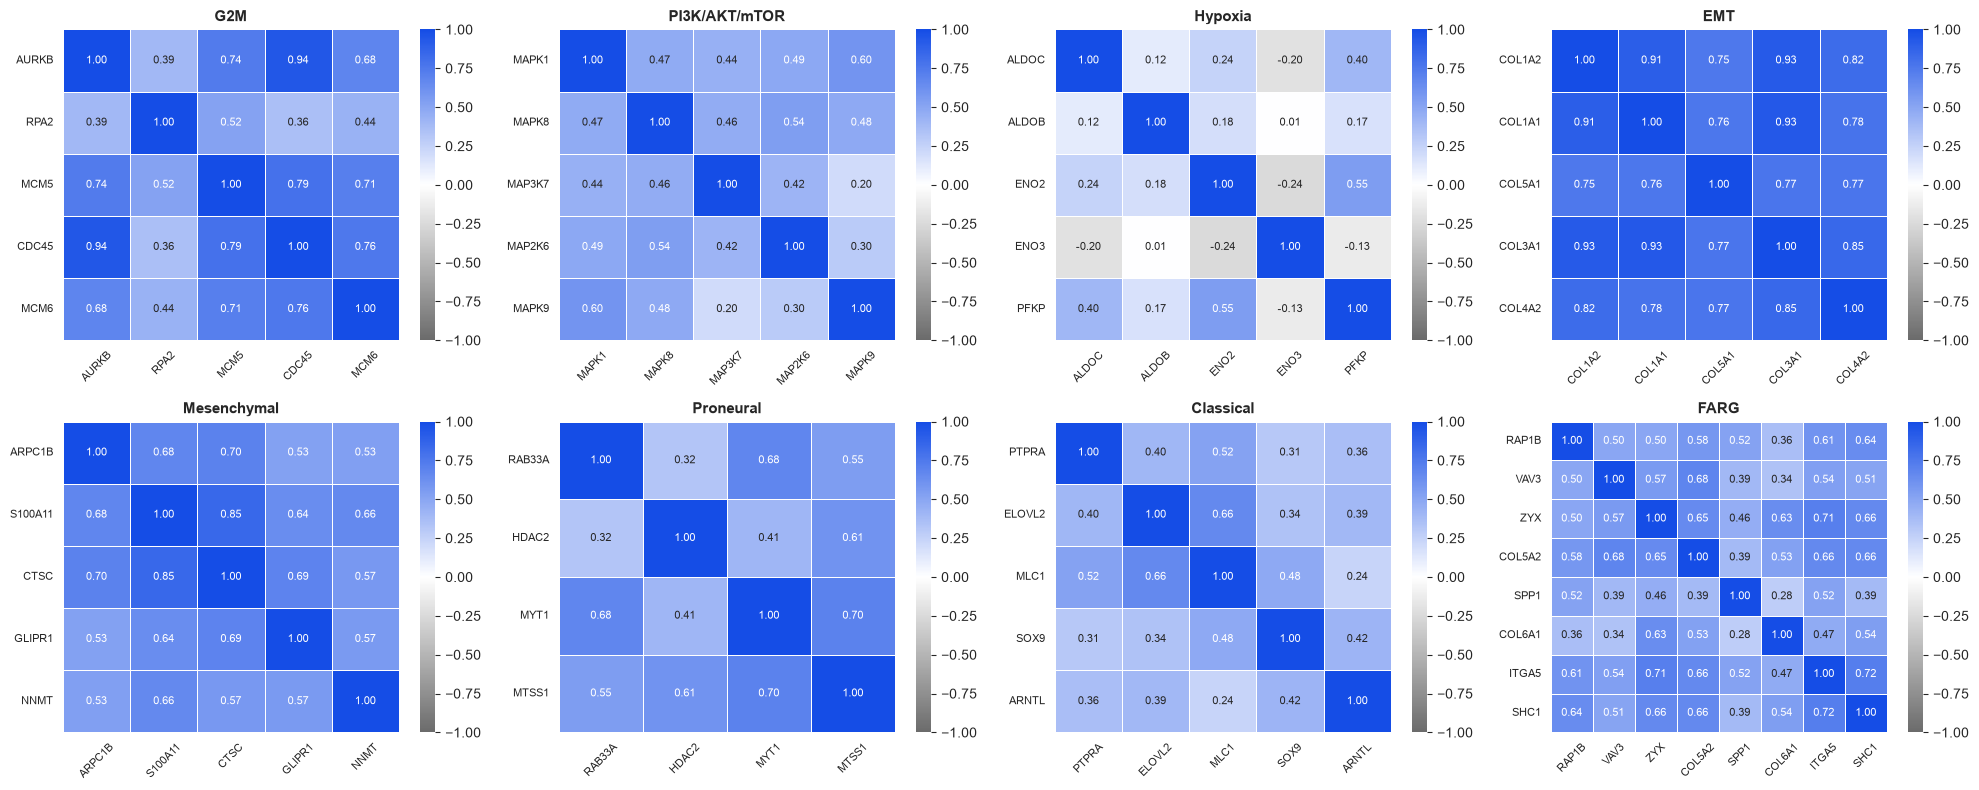

In [134]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for ax, (name, genes) in zip(axes, pathway_gene_map.items()):
    available = [g for g in genes if g in merged_expression_df.columns]
    corr = merged_expression_df[available].corr(method='pearson')
    labels = [g.replace('_exp', '') for g in available]
    corr.index = corr.columns = labels
    sns.heatmap(corr, cmap=DIV_CMAP, vmin=-1, vmax=1,
                annot=True, fmt='.2f', annot_kws={'size': 8},
                linewidths=0.5, ax=ax, cbar=True)
    ax.set_title(pathway_labels.get(name, name), fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.show()

### Pathway Score Construction

In [135]:
pathway_features = {
    'farg_score_exp':          'FARG Pathway',
    'classical_score_exp':     'Classical Pathway',
    'hypoxia_score_exp':       'Hypoxia Pathway',
    'emt_score_exp':           'EMT Pathway',
    'mesenchymal_score_exp':   'Mesenchymal Pathway',
    'g2m_score_exp':           'G2M Pathway',
    'pi3k_akt_mtor_score_exp': 'PI3K mTOR Pathway',
    'proneural_score_exp':     'Proneural Pathway',
}

score_label_map = {
    'g2m':           'G2M',
    'pi3k_akt_mtor': 'PI3K/AKT/mTOR',
    'hypoxia':       'Hypoxia',
    'emt':           'EMT',
    'mesenchymal':   'Mesenchymal',
    'proneural':     'Proneural',
    'classical':     'Classical',
    'farg':          'FARG',
}

In [136]:
# "enet": survival-weighted scores (main analysis); "mean": unweighted scores (Appendix A).
# Both write the same saved files, so the CGGA notebooks use whichever method ran last.
SCORE_METHOD = "enet"

all_features_df = model_4_cph.copy()

y_surv = np.array(
    [(bool(e), float(t)) for e, t in zip(merged_df["event"], merged_df["time"])],
    dtype=[("event", bool), ("time", float)]
)

score_cols = list(pathway_features.keys())

In [137]:
def fit_global_enet(X, y):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    enet_path = CoxnetSurvivalAnalysis(l1_ratio=0.5, alpha_min_ratio=0.01,
                                       fit_baseline_model=True, max_iter=100000)
    enet_path.fit(X_scaled, y)

    cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)
    alpha_scores = {}
    for alpha in enet_path.alphas_:
        fold_scores = []
        for train_idx, val_idx in cv.split(X):
            sc = StandardScaler()
            X_tr = sc.fit_transform(X.iloc[train_idx])
            X_val = sc.transform(X.iloc[val_idx])
            y_tr, y_val = y[train_idx], y[val_idx]
            m = CoxnetSurvivalAnalysis(l1_ratio=0.5, alphas=[alpha],
                                       fit_baseline_model=False, max_iter=100000)
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", UserWarning)
                    m.fit(X_tr, y_tr)
                score = concordance_index_censored(y_val["event"], y_val["time"],
                                                   m.predict(X_val))[0]
                fold_scores.append(score)
            except Exception:
                continue
        if len(fold_scores) == cv.get_n_splits():
            alpha_scores[alpha] = np.mean(fold_scores)

    for best_alpha in sorted(alpha_scores, key=alpha_scores.get, reverse=True):
        model = CoxnetSurvivalAnalysis(l1_ratio=0.5, alphas=[best_alpha],
                                       fit_baseline_model=True, max_iter=100000)
        try:
            model.fit(X_scaled, y)
            break
        except ArithmeticError:
            continue

    coef_df = pd.DataFrame({
        "feature": X.columns.tolist(),
        "coef": model.coef_[:, 0]
    })
    return model, coef_df, scaler, best_alpha, alpha_scores[best_alpha]

In [138]:
def compute_pathway_scores(X, coef_df, scaler):
    X_scaled = pd.DataFrame(scaler.transform(X), index=X.index, columns=X.columns)
    weights_all = coef_df.set_index("feature")["coef"]
    scores = pd.DataFrame(index=X.index)
    for score_col, pathway_name in pathway_features.items():
        available = [g for g in pathway_gene_map[pathway_name] if g in X_scaled.columns]
        scores[score_col] = X_scaled[available].multiply(weights_all.loc[available].values, axis=1).sum(axis=1)
    return scores

In [139]:
if SCORE_METHOD == "enet":
    global_model, global_coef_df, scaler, best_alpha, best_cv = fit_global_enet(all_features_df, y_surv)
    print(f"Global model: best alpha={best_alpha:.6f}, CV score={best_cv:.4f}")

    n_selected = (global_coef_df["coef"] != 0).sum()
    print(f"Global model: {n_selected}/{len(all_features_df.columns)} features selected")
    print(global_coef_df[global_coef_df["coef"] != 0].to_string(index=False))

    global_scores = compute_pathway_scores(all_features_df, global_coef_df, scaler)

    print("\n" + "="*60)
    print("CROSS-FITTED (OUT-OF-FOLD) PATHWAY SCORES")
    print("="*60)

    N_REPEATS = 5

    events = y_surv["event"].astype(int)
    repeat_scores = []
    fold_coefs = {}

    for rep in range(N_REPEATS):
        outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42 + rep)
        rep_scores = pd.DataFrame(index=all_features_df.index, columns=score_cols, dtype=float)

        for fold, (train_idx, test_idx) in enumerate(outer_cv.split(all_features_df, events)):
            X_train = all_features_df.iloc[train_idx]
            X_test = all_features_df.iloc[test_idx]
            _, coef_df_fold, scaler_fold, alpha_fold, cv_fold = fit_global_enet(X_train, y_surv[train_idx])
            fold_scores = compute_pathway_scores(X_test, coef_df_fold, scaler_fold)
            rep_scores.loc[X_test.index, score_cols] = fold_scores[score_cols].values
            fold_coefs[(rep, fold)] = coef_df_fold.set_index("feature")["coef"]
            n_fold = (coef_df_fold["coef"] != 0).sum()
            print(f"  Repeat {rep + 1}, fold {fold + 1}: alpha={alpha_fold:.6f}, inner CV score={cv_fold:.4f}, "
                  f"{n_fold}/{len(all_features_df.columns)} features selected")

        rep_sd = rep_scores.std(ddof=0).replace(0, 1)
        repeat_scores.append((rep_scores - rep_scores.mean()) / rep_sd)

    oof_scores = sum(repeat_scores) / N_REPEATS
    fold_coef_df = pd.DataFrame(fold_coefs)

    print("\n" + "="*60)
    print("PATHWAY SCORE CONSTRUCTION")
    print("="*60)

    for score_col, pathway_name in pathway_features.items():
        genes = pathway_gene_map[pathway_name]
        available = [g for g in genes if g in all_features_df.columns]
        weights = global_coef_df.set_index("feature").loc[available, "coef"]
        selected = weights[weights != 0]
        fold_freq = (fold_coef_df.loc[available] != 0).mean(axis=1)

        print(f"\n{pathway_name}  ({len(selected)}/{len(available)} genes selected in global model)")
        print(f"  {'Gene':<15} {'β (coef)':>10}  {'Status':<11} {'Fold fits sel.':>15}")
        print(f"  {'-'*56}")
        for gene in available:
            coef = weights[gene]
            status = "selected" if coef != 0 else "zeroed out"
            print(f"  {gene:<15} {coef:>10.6f}  {status:<11} {fold_freq[gene]:>15.0%}")

        if len(selected) > 0:
            terms = " + ".join([f"({coef:.4f} × z({g.replace('_exp','')}))"
                                for g, coef in selected.items()])
            print(f"\n  Global score = {terms}")
        else:
            print(f"\n  Global score = 0  (no genes selected)")

        print(f"  Cross-fitted score range: [{oof_scores[score_col].min():.4f}, {oof_scores[score_col].max():.4f}]")

elif SCORE_METHOD == "mean":
    scaler = StandardScaler().fit(all_features_df)
    weights = pd.Series(0.0, index=all_features_df.columns)
    for pathway_name in pathway_features.values():
        genes = [g for g in pathway_gene_map[pathway_name] if g in all_features_df.columns]
        weights[genes] = 1.0 / len(genes)

    global_model = None
    global_coef_df = pd.DataFrame({"feature": all_features_df.columns.tolist(), "coef": weights.values})
    global_scores = compute_pathway_scores(all_features_df, global_coef_df, scaler)
    oof_scores = global_scores.copy()

    print("="*60)
    print("MEAN Z-SCORE PATHWAY SCORES")
    print("="*60)
    for score_col, pathway_name in pathway_features.items():
        genes = [g for g in pathway_gene_map[pathway_name] if g in all_features_df.columns]
        print(f"  {pathway_name}: mean z-score of {len(genes)} genes "
              f"({', '.join(g.replace('_exp', '') for g in genes)})")

else:
    raise ValueError(f"Unknown SCORE_METHOD: {SCORE_METHOD}")

Global model: best alpha=0.057947, CV score=0.8543
Global model: 15/80 features selected
    feature      coef
        age  0.499688
  ALDOB_exp -0.114129
  ALDOC_exp -0.056146
  ARNTL_exp  0.271009
  AURKB_exp  0.052531
 COL6A1_exp  0.105296
   CTSC_exp  0.164133
   ENO2_exp -0.039220
   MCM6_exp  0.029065
    MN1_exp -0.166384
    MYB_exp  0.019944
  MYBL1_exp  0.157513
S100A11_exp  0.021638
   SOX9_exp  0.125011
   SPP1_exp  0.041176

CROSS-FITTED (OUT-OF-FOLD) PATHWAY SCORES
  Repeat 1, fold 1: alpha=0.025360, inner CV score=0.8536, 34/80 features selected
  Repeat 1, fold 2: alpha=0.072813, inner CV score=0.8553, 13/80 features selected
  Repeat 1, fold 3: alpha=0.062332, inner CV score=0.8477, 14/80 features selected
  Repeat 1, fold 4: alpha=0.090201, inner CV score=0.8580, 13/80 features selected
  Repeat 1, fold 5: alpha=0.098304, inner CV score=0.8300, 11/80 features selected
  Repeat 2, fold 1: alpha=0.068251, inner CV score=0.8417, 11/80 features selected
  Repeat 2, fold 2

In [140]:
save_dir = r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg"
os.makedirs(save_dir, exist_ok=True)

zero_var_cols = [c for c in score_cols
                 if oof_scores[c].std() == 0 or global_scores[c].std() == 0]
if zero_var_cols:
    print(f"\nDropping zero-variance pathway scores: {zero_var_cols}")
    score_cols = [c for c in score_cols if c not in zero_var_cols]
    pathway_features = {k: v for k, v in pathway_features.items() if k not in zero_var_cols}

score_scaler = StandardScaler()
global_scores_scaled = pd.DataFrame(score_scaler.fit_transform(global_scores[score_cols]),
                                    index=global_scores.index, columns=score_cols)


Dropping zero-variance pathway scores: ['emt_score_exp', 'pi3k_akt_mtor_score_exp', 'proneural_score_exp']


In [141]:
oof_score_scaler = StandardScaler()
expr_cols = [c for c in dimred_merged_df.columns if c.endswith("_exp")]
dimred_merged_df.drop(columns=expr_cols, inplace=True)
dimred_merged_df[score_cols] = oof_score_scaler.fit_transform(oof_scores.loc[dimred_merged_df.index, score_cols])

joblib.dump((global_model, global_coef_df, scaler),
            os.path.join(save_dir, "global_enet_result.pkl"))
joblib.dump(score_scaler, os.path.join(save_dir, "tcga_score_scaler.pkl"))
if SCORE_METHOD == "enet":
    joblib.dump(fold_coef_df, os.path.join(save_dir, "oof_fold_coefs.pkl"))
joblib.dump(oof_score_scaler, os.path.join(save_dir, "tcga_oof_score_scaler.pkl"))
dimred_merged_df.to_csv(os.path.join(save_dir, "dimred_merged_df.csv"), index=False)

### Pathway Score Exploration

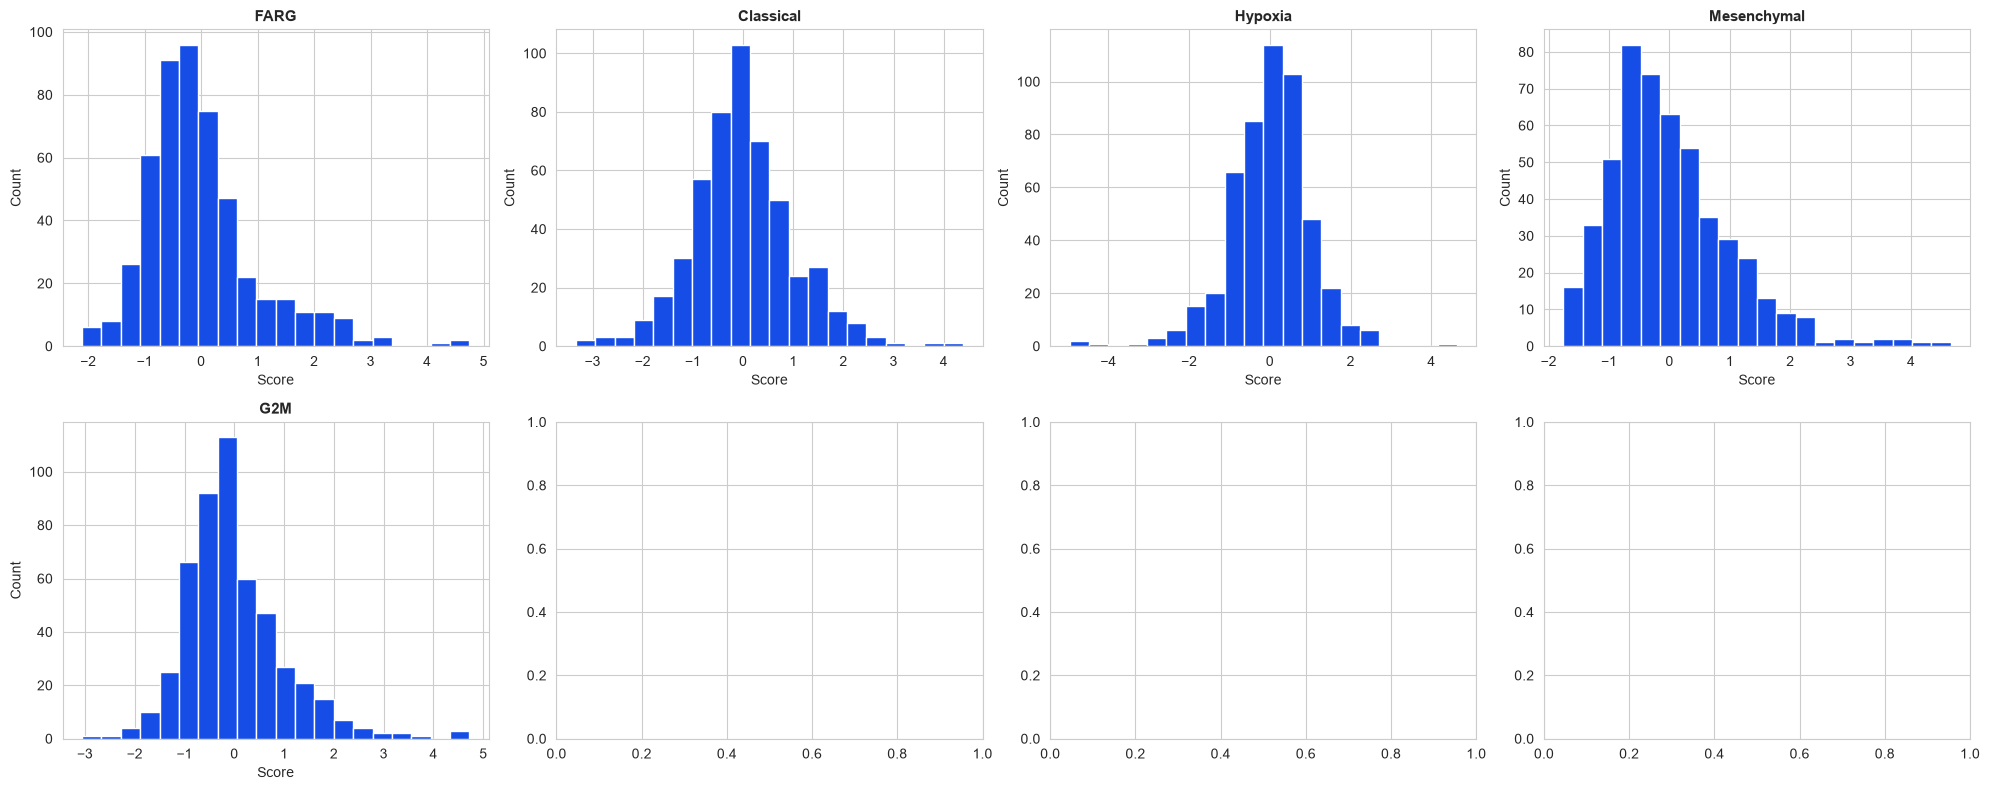

In [142]:
def format_label(col):
    key = col.replace('_score_exp', '')
    return score_label_map.get(key, key.replace('_', ' ').title())

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for ax, col in zip(axes, score_cols):
    ax.hist(dimred_merged_df[col].dropna(), bins=20, color='#154DE6', edgecolor='white')
    ax.set_title(format_label(col), fontsize=11, fontweight='bold')
    ax.set_xlabel('Score')
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

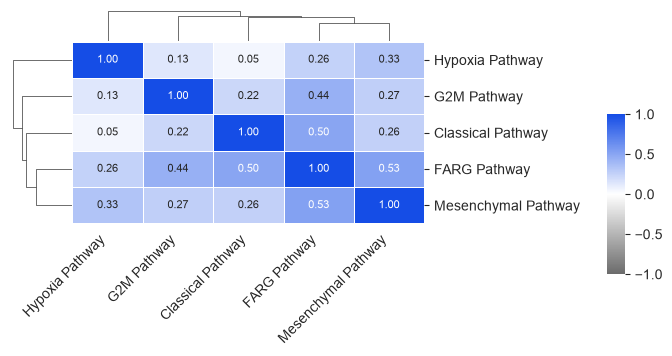

In [143]:
pathway_cols = score_cols
clean_labels = [pathway_features[c] for c in pathway_cols]

corr_df = pd.DataFrame(
    dimred_merged_df[pathway_cols].corr(method='pearson').values,
    index=clean_labels, columns=clean_labels
)

g = sns.clustermap(
    corr_df,
    cmap=DIV_CMAP, vmin=-1, vmax=1,
    annot=True, fmt='.2f', annot_kws={'size': 8},
    figsize=(6, 4),
    linewidths=0.5,
    dendrogram_ratio=0.15,
    cbar_pos=(1.02, 0.3, 0.03, 0.4)
)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right')
plt.show()

# Models (Reduced Features)

## Statistical Models

### Logistic Regression

In [144]:
dimred_mutation_cols = [col for col in dimred_merged_df.columns if col.endswith("_mut")]
dimred_expr_cols = [col for col in dimred_merged_df.columns if col.endswith("_exp")]

In [145]:
assert dimred_merged_df.index.equals(merged_df.index)

In [146]:
y = dimred_merged_df["event"]

dimred_clinical_log = dimred_merged_df[["gender", "age"]].copy()
dimred_mutation_log = dimred_merged_df[dimred_mutation_cols].copy()
dimred_expression_log = dimred_merged_df[dimred_expr_cols].copy()

In [147]:
dimred_model_1_log = dimred_clinical_log
dimred_model_2_log = pd.concat([dimred_clinical_log, dimred_mutation_log], axis=1)
dimred_model_3_log = pd.concat([dimred_clinical_log, dimred_expression_log], axis=1)
dimred_model_4_log = pd.concat([dimred_clinical_log, dimred_mutation_log, dimred_expression_log], axis=1)

In [148]:
dimred_auc_1_log, dimred_train_auc_1_log, dimred_std_1_log, dimred_train_std_1_log, dimred_fpr_1_log, dimred_tpr_1_log, dimred_C_1_log, dimred_params_1_log, dimred_yt_1, dimred_yp_1 = cv_logreg(dimred_model_1_log, y)
dimred_auc_2_log, dimred_train_auc_2_log, dimred_std_2_log, dimred_train_std_2_log, dimred_fpr_2_log, dimred_tpr_2_log, dimred_C_2_log, dimred_params_2_log, dimred_yt_2, dimred_yp_2 = cv_logreg(dimred_model_2_log, y)
dimred_auc_3_log, dimred_train_auc_3_log, dimred_std_3_log, dimred_train_std_3_log, dimred_fpr_3_log, dimred_tpr_3_log, dimred_C_3_log, dimred_params_3_log, dimred_yt_3, dimred_yp_3 = cv_logreg(dimred_model_3_log, y)
dimred_auc_4_log, dimred_train_auc_4_log, dimred_std_4_log, dimred_train_std_4_log, dimred_fpr_4_log, dimred_tpr_4_log, dimred_C_4_log, dimred_params_4_log, dimred_yt_4, dimred_yp_4 = cv_logreg(dimred_model_4_log, y)

dimred_results_cv_logreg = {
    "Model 1": (dimred_auc_1_log, dimred_train_auc_1_log, dimred_std_1_log, dimred_train_std_1_log, dimred_fpr_1_log, dimred_tpr_1_log, dimred_C_1_log, dimred_params_1_log),
    "Model 2": (dimred_auc_2_log, dimred_train_auc_2_log, dimred_std_2_log, dimred_train_std_2_log, dimred_fpr_2_log, dimred_tpr_2_log, dimred_C_2_log, dimred_params_2_log),
    "Model 3": (dimred_auc_3_log, dimred_train_auc_3_log, dimred_std_3_log, dimred_train_std_3_log, dimred_fpr_3_log, dimred_tpr_3_log, dimred_C_3_log, dimred_params_3_log),
    "Model 4": (dimred_auc_4_log, dimred_train_auc_4_log, dimred_std_4_log, dimred_train_std_4_log, dimred_fpr_4_log, dimred_tpr_4_log, dimred_C_4_log, dimred_params_4_log),
}

In [149]:
for name, test_auc, test_std, train_auc, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_auc_1_log, dimred_auc_2_log, dimred_auc_3_log, dimred_auc_4_log],
    [dimred_std_1_log, dimred_std_2_log, dimred_std_3_log, dimred_std_4_log],
    [dimred_train_auc_1_log, dimred_train_auc_2_log, dimred_train_auc_3_log, dimred_train_auc_4_log],
    [dimred_train_std_1_log, dimred_train_std_2_log, dimred_train_std_3_log, dimred_train_std_4_log],
):
    print(f"{name}: Test AUC={test_auc:.3f} +/- {test_std:.3f} | Train AUC={train_auc:.3f} +/- {train_std:.3f}")

Model 1: Test AUC=0.644 +/- 0.071 | Train AUC=0.652 +/- 0.018
Model 2: Test AUC=0.677 +/- 0.030 | Train AUC=0.696 +/- 0.009
Model 3: Test AUC=0.740 +/- 0.037 | Train AUC=0.772 +/- 0.010
Model 4: Test AUC=0.741 +/- 0.025 | Train AUC=0.778 +/- 0.009


In [150]:
for name, result in dimred_results_cv_logreg.items():
    print(f"\n{name} best params per fold:")
    for params in result[-1]:
        print(params)


Model 1 best params per fold:
{'C': np.float64(1.0), 'class_weight': None, 'l1_ratio': 0.5}
{'C': np.float64(0.046415888336127774), 'class_weight': None, 'l1_ratio': 0.5}
{'C': np.float64(1.0), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(1.0), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(0.21544346900318823), 'class_weight': None, 'l1_ratio': 0.0}

Model 2 best params per fold:
{'C': np.float64(100.0), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(1.0), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(100.0), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(21.54434690031882), 'class_weight': 'balanced', 'l1_ratio': 1.0}
{'C': np.float64(1.0), 'class_weight': None, 'l1_ratio': 0.0}

Model 3 best params per fold:
{'C': np.float64(0.00046415888336127773), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(0.046415888336127774), 'class_weight': None, 'l1_ratio': 0.0}
{'C': np.float64(0.002154434690031882), 'class_weight': None, 'l1_rati

In [151]:
dimred_results_final_logreg = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_model_1_log, dimred_model_2_log, dimred_model_3_log, dimred_model_4_log]
):
    model, coef_df, auc, best_params, scaler, kept_cols = fit_final_logreg(X, y)
    dimred_results_final_logreg[name] = (model, coef_df, auc, best_params, scaler, kept_cols)

### Cox Proportional Hazards

In [152]:
y_surv = np.array(
    [(bool(e), float(t)) for e, t in zip(dimred_merged_df["event"], dimred_merged_df["time"])],
    dtype=[("event", bool), ("time", float)]
)

In [153]:
dimred_clinical_cph = dimred_merged_df[["gender", "age"]].copy()
dimred_mutation_cph = dimred_merged_df[dimred_mutation_cols].copy()
dimred_expression_cph = dimred_merged_df[dimred_expr_cols].copy()

In [154]:
dimred_model_1_cph = dimred_clinical_cph
dimred_model_2_cph = pd.concat([dimred_clinical_cph, dimred_mutation_cph], axis=1)
dimred_model_3_cph = pd.concat([dimred_clinical_cph, dimred_expression_cph], axis=1)
dimred_model_4_cph = pd.concat([dimred_clinical_cph, dimred_mutation_cph, dimred_expression_cph], axis=1)

In [155]:
dimred_c_1_cph, dimred_train_c_1_cph, dimred_std_1_cph, dimred_train_std_1_cph, dimred_alpha_1_cph, dimred_params_1_cph = cv_cph(dimred_model_1_cph, y_surv)
dimred_c_2_cph, dimred_train_c_2_cph, dimred_std_2_cph, dimred_train_std_2_cph, dimred_alpha_2_cph, dimred_params_2_cph = cv_cph(dimred_model_2_cph, y_surv)
dimred_c_3_cph, dimred_train_c_3_cph, dimred_std_3_cph, dimred_train_std_3_cph, dimred_alpha_3_cph, dimred_params_3_cph = cv_cph(dimred_model_3_cph, y_surv)
dimred_c_4_cph, dimred_train_c_4_cph, dimred_std_4_cph, dimred_train_std_4_cph, dimred_alpha_4_cph, dimred_params_4_cph = cv_cph(dimred_model_4_cph, y_surv)

dimred_results_cv_cph = {
    "Model 1": (dimred_c_1_cph, dimred_train_c_1_cph, dimred_std_1_cph, dimred_train_std_1_cph, dimred_alpha_1_cph, dimred_params_1_cph),
    "Model 2": (dimred_c_2_cph, dimred_train_c_2_cph, dimred_std_2_cph, dimred_train_std_2_cph, dimred_alpha_2_cph, dimred_params_2_cph),
    "Model 3": (dimred_c_3_cph, dimred_train_c_3_cph, dimred_std_3_cph, dimred_train_std_3_cph, dimred_alpha_3_cph, dimred_params_3_cph),
    "Model 4": (dimred_c_4_cph, dimred_train_c_4_cph, dimred_std_4_cph, dimred_train_std_4_cph, dimred_alpha_4_cph, dimred_params_4_cph),
}

In [156]:
for name, test_c, test_std, train_c, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_c_1_cph, dimred_c_2_cph, dimred_c_3_cph, dimred_c_4_cph],
    [dimred_std_1_cph, dimred_std_2_cph, dimred_std_3_cph, dimred_std_4_cph],
    [dimred_train_c_1_cph, dimred_train_c_2_cph, dimred_train_c_3_cph, dimred_train_c_4_cph],
    [dimred_train_std_1_cph, dimred_train_std_2_cph, dimred_train_std_3_cph, dimred_train_std_4_cph],
):
    print(f"{name}: Test C={test_c:.3f} +/- {test_std:.3f} | Train C={train_c:.3f} +/- {train_std:.3f}")

Model 1: Test C=0.786 +/- 0.053 | Train C=0.780 +/- 0.013
Model 2: Test C=0.795 +/- 0.039 | Train C=0.802 +/- 0.011
Model 3: Test C=0.813 +/- 0.040 | Train C=0.845 +/- 0.007
Model 4: Test C=0.804 +/- 0.045 | Train C=0.841 +/- 0.006


In [157]:
for name, result in dimred_results_cv_cph.items():
    print(f"\n{name} best params per fold:")
    for params in result[-1]:
        print(params)


Model 1 best params per fold:
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 1.0}
{'alphas': [np.float64(0.016681005372000592)], 'l1_ratio': 1.0}
{'alphas': [np.float64(1.0)], 'l1_ratio': 0.01}
{'alphas': [np.float64(0.005994842503189409)], 'l1_ratio': 1.0}

Model 2 best params per fold:
{'alphas': [np.float64(0.002154434690031882)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.016681005372000592)], 'l1_ratio': 1.0}
{'alphas': [np.float64(0.016681005372000592)], 'l1_ratio': 1.0}
{'alphas': [np.float64(0.005994842503189409)], 'l1_ratio': 1.0}
{'alphas': [np.float64(0.0001)], 'l1_ratio': 0.01}

Model 3 best params per fold:
{'alphas': [np.float64(1.0)], 'l1_ratio': 0.01}
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 0.01}
{'alphas': [np.float64(0.046415888336127774)], 'l1_ratio': 0.5}
{'alphas': [np.float64(0.3593813663804626)], 'l1_ratio'

In [158]:
dimred_results_final_cph = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_model_1_cph, dimred_model_2_cph, dimred_model_3_cph, dimred_model_4_cph]
):
    model, coef_df, c_index, best_params, scaler, kept_cols = fit_final_cph(X, y_surv)
    dimred_results_final_cph[name] = (model, coef_df, c_index, best_params, scaler, kept_cols)

## Machine Learning Models

### Random Survival Forest

In [159]:
dimred_model_1_rsf = dimred_model_1_cph
dimred_model_2_rsf = dimred_model_2_cph
dimred_model_3_rsf = dimred_model_3_cph
dimred_model_4_rsf = dimred_model_4_cph

In [160]:
dimred_c_1_rsf, dimred_train_c_1_rsf, dimred_std_1_rsf, dimred_train_std_1_rsf, dimred_params_1_rsf = cv_rsf(dimred_model_1_rsf, y_surv)
dimred_c_2_rsf, dimred_train_c_2_rsf, dimred_std_2_rsf, dimred_train_std_2_rsf, dimred_params_2_rsf = cv_rsf(dimred_model_2_rsf, y_surv)
dimred_c_3_rsf, dimred_train_c_3_rsf, dimred_std_3_rsf, dimred_train_std_3_rsf, dimred_params_3_rsf = cv_rsf(dimred_model_3_rsf, y_surv)
dimred_c_4_rsf, dimred_train_c_4_rsf, dimred_std_4_rsf, dimred_train_std_4_rsf, dimred_params_4_rsf = cv_rsf(dimred_model_4_rsf, y_surv)

dimred_results_cv_rsf = {
    "Model 1": (dimred_c_1_rsf, dimred_train_c_1_rsf, dimred_std_1_rsf, dimred_train_std_1_rsf, dimred_params_1_rsf),
    "Model 2": (dimred_c_2_rsf, dimred_train_c_2_rsf, dimred_std_2_rsf, dimred_train_std_2_rsf, dimred_params_2_rsf),
    "Model 3": (dimred_c_3_rsf, dimred_train_c_3_rsf, dimred_std_3_rsf, dimred_train_std_3_rsf, dimred_params_3_rsf),
    "Model 4": (dimred_c_4_rsf, dimred_train_c_4_rsf, dimred_std_4_rsf, dimred_train_std_4_rsf, dimred_params_4_rsf),
}

In [161]:
for name, test_c, test_std, train_c, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_c_1_rsf, dimred_c_2_rsf, dimred_c_3_rsf, dimred_c_4_rsf],
    [dimred_std_1_rsf, dimred_std_2_rsf, dimred_std_3_rsf, dimred_std_4_rsf],
    [dimred_train_c_1_rsf, dimred_train_c_2_rsf, dimred_train_c_3_rsf, dimred_train_c_4_rsf],
    [dimred_train_std_1_rsf, dimred_train_std_2_rsf, dimred_train_std_3_rsf, dimred_train_std_4_rsf],
):
    print(f"{name}: Test C-Index={test_c:.3f} +/- {test_std:.3f} | Train C-Index={train_c:.3f} +/- {train_std:.3f}")

Model 1: Test C-Index=0.745 +/- 0.077 | Train C-Index=0.853 +/- 0.015
Model 2: Test C-Index=0.796 +/- 0.026 | Train C-Index=0.871 +/- 0.031
Model 3: Test C-Index=0.830 +/- 0.030 | Train C-Index=0.898 +/- 0.015
Model 4: Test C-Index=0.838 +/- 0.023 | Train C-Index=0.905 +/- 0.013


In [162]:
for name, (_, _, _, _, best_params_list) in dimred_results_cv_rsf.items():
    print(f"\n{name} best params per fold:")
    for params in best_params_list:
        print(params)


Model 1 best params per fold:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 10}
{'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}

Model 2 best params per fold:
{'max_depth': 5, 'max_features': 0.3, 'min_samples_leaf': 5}
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 10}
{'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 20}

Model 3 best params per fold:
{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 10}
{'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 10}
{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 15}
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_lea

In [163]:
dimred_results_final_rsf = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_model_1_rsf, dimred_model_2_rsf, dimred_model_3_rsf, dimred_model_4_rsf]
):
    model, importance_df, c_index, best_params, kept_cols = fit_final_rsf(X, y_surv)
    dimred_results_final_rsf[name] = (model, importance_df, c_index, best_params, kept_cols)

### Gradient Boosting

In [164]:
dimred_model_1_gbm = dimred_model_1_cph
dimred_model_2_gbm = dimred_model_2_cph
dimred_model_3_gbm = dimred_model_3_cph
dimred_model_4_gbm = dimred_model_4_cph

In [165]:
dimred_c_1_gbm, dimred_train_c_1_gbm, dimred_std_1_gbm, dimred_train_std_1_gbm, dimred_params_1_gbm = cv_gbm(dimred_model_1_gbm, y_surv)
dimred_c_2_gbm, dimred_train_c_2_gbm, dimred_std_2_gbm, dimred_train_std_2_gbm, dimred_params_2_gbm = cv_gbm(dimred_model_2_gbm, y_surv)
dimred_c_3_gbm, dimred_train_c_3_gbm, dimred_std_3_gbm, dimred_train_std_3_gbm, dimred_params_3_gbm = cv_gbm(dimred_model_3_gbm, y_surv)
dimred_c_4_gbm, dimred_train_c_4_gbm, dimred_std_4_gbm, dimred_train_std_4_gbm, dimred_params_4_gbm = cv_gbm(dimred_model_4_gbm, y_surv)

dimred_results_cv_gbm = {
    "Model 1": (dimred_c_1_gbm, dimred_train_c_1_gbm, dimred_std_1_gbm, dimred_train_std_1_gbm, dimred_params_1_gbm),
    "Model 2": (dimred_c_2_gbm, dimred_train_c_2_gbm, dimred_std_2_gbm, dimred_train_std_2_gbm, dimred_params_2_gbm),
    "Model 3": (dimred_c_3_gbm, dimred_train_c_3_gbm, dimred_std_3_gbm, dimred_train_std_3_gbm, dimred_params_3_gbm),
    "Model 4": (dimred_c_4_gbm, dimred_train_c_4_gbm, dimred_std_4_gbm, dimred_train_std_4_gbm, dimred_params_4_gbm),
}

In [166]:
for name, test_c, test_std, train_c, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_c_1_gbm, dimred_c_2_gbm, dimred_c_3_gbm, dimred_c_4_gbm],
    [dimred_std_1_gbm, dimred_std_2_gbm, dimred_std_3_gbm, dimred_std_4_gbm],
    [dimred_train_c_1_gbm, dimred_train_c_2_gbm, dimred_train_c_3_gbm, dimred_train_c_4_gbm],
    [dimred_train_std_1_gbm, dimred_train_std_2_gbm, dimred_train_std_3_gbm, dimred_train_std_4_gbm],
):
    print(f"{name}: Test C-Index={test_c:.3f} +/- {test_std:.3f} | Train C-Index={train_c:.3f} +/- {train_std:.3f}")

Model 1: Test C-Index=0.757 +/- 0.074 | Train C-Index=0.819 +/- 0.024
Model 2: Test C-Index=0.781 +/- 0.042 | Train C-Index=0.875 +/- 0.026
Model 3: Test C-Index=0.827 +/- 0.044 | Train C-Index=0.879 +/- 0.009
Model 4: Test C-Index=0.828 +/- 0.024 | Train C-Index=0.890 +/- 0.007


In [167]:
for name, (_, _, _, _, best_params_list) in dimred_results_cv_gbm.items():
    print(f"\n{name} best params per fold:")
    for params in best_params_list:
        print(params)


Model 1 best params per fold:
{'learning_rate': 0.01, 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'subsample': 0.6}
{'learning_rate': 0.05, 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'subsample': 1.0}
{'learning_rate': 0.05, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'subsample': 1.0}
{'learning_rate': 0.1, 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'subsample': 1.0}
{'learning_rate': 0.05, 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'subsample': 0.8}

Model 2 best params per fold:
{'learning_rate': 0.1, 'max_depth': 5, 'max_features': 0.3, 'min_samples_leaf': 5, 'subsample': 0.8}
{'learning_rate': 0.1, 'max_depth': 3, 'max_features': 0.3, 'min_samples_leaf': 5, 'subsample': 0.8}
{'learning_rate': 0.1, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'subsample': 0.8}
{'learning_rate': 0.1, 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'subsample': 0.6

In [168]:
dimred_results_final_gbm = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_model_1_gbm, dimred_model_2_gbm, dimred_model_3_gbm, dimred_model_4_gbm]
):
    model, importance_df, c_index, best_params, kept_cols = fit_final_gbm(X, y_surv)
    dimred_results_final_gbm[name] = (model, importance_df, c_index, best_params, kept_cols)

### Artificial Neural Network

In [169]:
dimred_model_1_ann = dimred_model_1_cph
dimred_model_2_ann = dimred_model_2_cph
dimred_model_3_ann = dimred_model_3_cph
dimred_model_4_ann = dimred_model_4_cph

In [170]:
dimred_c_1_ann, dimred_train_c_1_ann, dimred_std_1_ann, dimred_train_std_1_ann, dimred_params_1_ann = cv_ann(dimred_model_1_ann, y_surv)
dimred_c_2_ann, dimred_train_c_2_ann, dimred_std_2_ann, dimred_train_std_2_ann, dimred_params_2_ann = cv_ann(dimred_model_2_ann, y_surv)
dimred_c_3_ann, dimred_train_c_3_ann, dimred_std_3_ann, dimred_train_std_3_ann, dimred_params_3_ann = cv_ann(dimred_model_3_ann, y_surv)
dimred_c_4_ann, dimred_train_c_4_ann, dimred_std_4_ann, dimred_train_std_4_ann, dimred_params_4_ann = cv_ann(dimred_model_4_ann, y_surv)

dimred_results_cv_ann = {
    "Model 1": (dimred_c_1_ann, dimred_train_c_1_ann, dimred_std_1_ann, dimred_train_std_1_ann, dimred_params_1_ann),
    "Model 2": (dimred_c_2_ann, dimred_train_c_2_ann, dimred_std_2_ann, dimred_train_std_2_ann, dimred_params_2_ann),
    "Model 3": (dimred_c_3_ann, dimred_train_c_3_ann, dimred_std_3_ann, dimred_train_std_3_ann, dimred_params_3_ann),
    "Model 4": (dimred_c_4_ann, dimred_train_c_4_ann, dimred_std_4_ann, dimred_train_std_4_ann, dimred_params_4_ann),
}

In [171]:
for name, test_c, test_std, train_c, train_std in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_c_1_ann, dimred_c_2_ann, dimred_c_3_ann, dimred_c_4_ann],
    [dimred_std_1_ann, dimred_std_2_ann, dimred_std_3_ann, dimred_std_4_ann],
    [dimred_train_c_1_ann, dimred_train_c_2_ann, dimred_train_c_3_ann, dimred_train_c_4_ann],
    [dimred_train_std_1_ann, dimred_train_std_2_ann, dimred_train_std_3_ann, dimred_train_std_4_ann],
):
    print(f"{name}: Test C-Index={test_c:.3f} +/- {test_std:.3f} | Train C-Index={train_c:.3f} +/- {train_std:.3f}")

Model 1: Test C-Index=0.778 +/- 0.063 | Train C-Index=0.781 +/- 0.010
Model 2: Test C-Index=0.766 +/- 0.044 | Train C-Index=0.805 +/- 0.013
Model 3: Test C-Index=0.820 +/- 0.049 | Train C-Index=0.841 +/- 0.009
Model 4: Test C-Index=0.770 +/- 0.036 | Train C-Index=0.812 +/- 0.010


In [172]:
for name, (_, _, _, _, best_params_list) in dimred_results_cv_ann.items():
    print(f"\n{name} best params per fold:")
    for params in best_params_list:
        print(params)


Model 1 best params per fold:
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.5, 'hidden_dim': 8, 'weight_decay': 0.001}
{'dropout': 0.5, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.001}

Model 2 best params per fold:
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 8, 'weight_decay': 0.001}
{'dropout': 0.5, 'hidden_dim': 8, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.01}
{'dropout': 0.5, 'hidden_dim': 8, 'weight_decay': 0.001}

Model 3 best params per fold:
{'dropout': 0.5, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.5, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.3, 'hidden_dim': 16, 'weight_decay': 0.01}
{'dropout': 0.5, 'hidden_dim': 16, 'weight_decay': 0.001}
{'dropout': 0.5, 'hidden_dim': 16, 'weight_decay': 0.001}

Model 4 best params per fold:
{'dropout': 

In [173]:
dimred_results_final_ann = {}
for name, X in zip(
    ["Model 1", "Model 2", "Model 3", "Model 4"],
    [dimred_model_1_ann, dimred_model_2_ann, dimred_model_3_ann, dimred_model_4_ann]
):
    model, importance_df, c_index, best_params, kept_cols = fit_final_ann(X, y_surv)
    dimred_results_final_ann[name] = (model, importance_df, c_index, best_params, kept_cols)

# Model and Method Evaluation

## Performance Summary

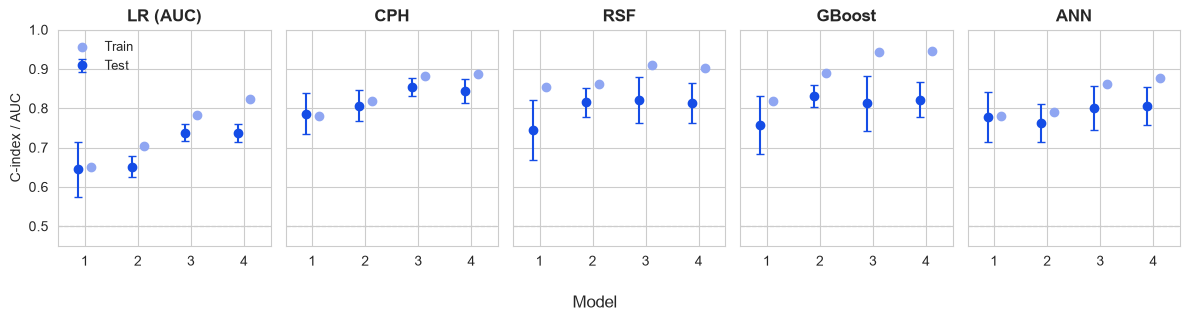

In [174]:
COLOUR, LIGHT = "#154DE6", "#8FA6F2"

methods = {
    "LR":     results_cv_logreg,
    "CPH":    results_cv_cph,
    "RSF":    results_cv_rsf,
    "GBoost": results_cv_gbm,
    "ANN":    results_cv_ann,
}
model_names = ["Model 1", "Model 2", "Model 3", "Model 4"]
x = np.arange(len(model_names))

fig, axes = plt.subplots(1, len(methods), figsize=(12, 3.2), sharey=True)

for ax, (name, res) in zip(axes, methods.items()):
    test  = [res[m][0] for m in model_names]
    train = [res[m][1] for m in model_names]
    sd    = [res[m][2] for m in model_names]
    ax.errorbar(x - 0.12, test, yerr=sd, fmt="o", color=COLOUR, ms=6, capsize=3, lw=1.5, label="Test")
    ax.plot(x + 0.12, train, "o", color=LIGHT, ms=6, label="Train")
    ax.axhline(0.5, color="grey", lw=0.8, ls="--", zorder=0)
    ax.set_title(f"{name} (AUC)" if name == "LR" else name, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(["1", "2", "3", "4"])
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0.45, 1.0)

axes[0].set_ylabel("C-index / AUC")
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
fig.supxlabel("Model")
plt.tight_layout()
plt.show()

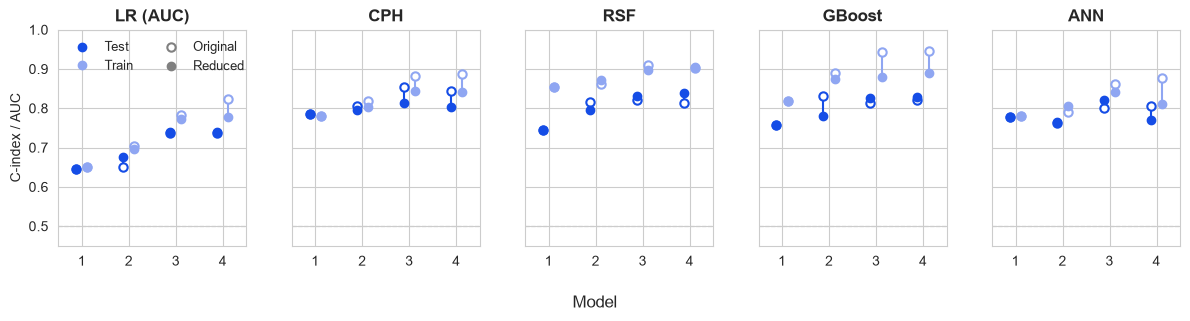

In [175]:
COLOUR, LIGHT = "#154DE6", "#8FA6F2"

methods = {
    "LR":     (dimred_results_cv_logreg, results_cv_logreg),
    "CPH":    (dimred_results_cv_cph,    results_cv_cph),
    "RSF":    (dimred_results_cv_rsf,    results_cv_rsf),
    "GBoost": (dimred_results_cv_gbm,    results_cv_gbm),
    "ANN":    (dimred_results_cv_ann,    results_cv_ann),
}
model_names = ["Model 1", "Model 2", "Model 3", "Model 4"]
x = np.arange(len(model_names))

fig, axes = plt.subplots(1, len(methods), figsize=(12, 3.2), sharey=True)

for ax, (name, (red, orig)) in zip(axes, methods.items()):
    for idx, colour, dx in [(0, COLOUR, -0.12), (1, LIGHT, 0.12)]:
        o = [orig[m][idx] for m in model_names]
        r = [red[m][idx] for m in model_names]
        for xi, oi, ri in zip(x + dx, o, r):
            ax.plot([xi, xi], [oi, ri], color=colour, lw=1.5, zorder=1)
        ax.plot(x + dx, o, "o", mfc="white", mec=colour, mew=1.5, ms=6, zorder=2)
        ax.plot(x + dx, r, "o", color=colour, ms=6, zorder=3)
    ax.axhline(0.5, color="grey", lw=0.8, ls="--", zorder=0)
    ax.set_title(f"{name} (AUC)" if name == "LR" else name, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(["1", "2", "3", "4"])
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0.45, 1.0)

handles = [
    Line2D([], [], marker="o", ls="", color=COLOUR, ms=6, label="Test"),
    Line2D([], [], marker="o", ls="", color=LIGHT,  ms=6, label="Train"),
    Line2D([], [], marker="o", ls="", mfc="white", mec="grey", mew=1.5, ms=6, label="Original"),
    Line2D([], [], marker="o", ls="", color="grey", ms=6, label="Reduced"),
]
axes[0].legend(handles=handles, frameon=False, loc="upper left", fontsize=9, ncol=2)
axes[0].set_ylabel("C-index / AUC")
fig.supxlabel("Model")
plt.tight_layout()
plt.show()

# Prognostic Model

## Feature Selection

In [176]:
clinical_features  = {'age': 'Age', 'gender': 'Sex'}
mutation_features  = {'IDH1_mut': 'IDH1', 'TP53_mut': 'TP53', 'ATRX_mut': 'ATRX'}

all_features = {**clinical_features, **mutation_features, **pathway_features}
reduced_features = list(all_features.keys())

In [177]:
multivariable_cols = ["time", "event"] + reduced_features
df_multi = dimred_merged_df[multivariable_cols].copy()
cph_multi = CoxPHFitter()
cph_multi.fit(df_multi, duration_col="time", event_col="event")
cph_multi.print_summary()

summary = cph_multi.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
sig = summary[summary["p"] < 0.05]
if sig.empty:
    print("No significant features at p < 0.05")

report_labels = {
    "age": "Age (per year)", "gender": "Sex (female)",
    "pi3k_akt_mtor_score_exp": "PI3K/AKT/mTOR", "emt_score_exp": "EMT",
    "hypoxia_score_exp": "Hypoxia", "g2m_score_exp": "G2/M checkpoint",
    "farg_score_exp": "FARG", "classical_score_exp": "Classical",
    "mesenchymal_score_exp": "Mesenchymal", "proneural_score_exp": "Proneural",
}

<lifelines.CoxPHFitter: fitted with 501 total observations, 411 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 501
number of events observed = 90
   partial log-likelihood = -360.72
         time fit was run = 2026-10-26 14:26:39 UTC

---
                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                              
age                    0.07      1.07      0.01            0.05            0.09                1.05                1.09
gender                -0.01      0.99      0.23           -0.45            0.44                0.64                1.55
IDH1_mut              -0.14      0.87      0.34           -0.81            0.52                0.45                1.69
TP53_mut               0.56      1.75      0.37           -0.16            1.29                0.85                3.62
ATRX_mut              -0.28      0.76      0.37           -1.01            0.46                0.36                1.58
farg_score_exp         0.13      1.14      0.14           -0.15            0.41                0.86                1.50
classical_score_exp    0.52      1.68      0.13            0.26            0.78                1.30                2.19
hypoxia_score_exp      0.29      1.34      0.14            0.01            0.57                1.01                1.77
mesenchymal_score_exp  0.13      1.14      0.10           -0.07            0.33                0.93                1.39
g2m_score_exp          0.14      1.16      0.12           -0.08            0.37                0.92                1.45

                       cmp to     z      p  -log2(p)
covariate                                           
age                      0.00  6.45 <0.005     33.08
gender                   0.00 -0.03   0.98      0.03
IDH1_mut                 0.00 -0.42   0.68      0.56
TP53_mut                 0.00  1.52   0.13      2.96
ATRX_mut                 0.00 -0.74   0.46      1.13
farg_score_exp           0.00  0.89   0.37      1.43
classical_score_exp      0.00  3.93 <0.005     13.52
hypoxia_score_exp        0.00  2.05   0.04      4.63
mesenchymal_score_exp    0.00  1.26   0.21      2.28
g2m_score_exp            0.00  1.24   0.21      2.23
---
Concordance = 0.84
Partial AIC = 741.44
log-likelihood ratio test = 119.72 on 10 df
-log2(p) of ll-ratio test = 67.23

In [178]:
for f in reduced_features:
    if f.endswith("_mut"):
        report_labels[f] = f"$\\it{{{f.replace('_mut', '')}}}$"

report_order = (["age", "gender"]
                + [f for f in reduced_features if f.endswith("_mut")]
                + [f for f in report_labels if f.endswith("_score_exp") and f in reduced_features])

In [179]:
def plot_forest(features, cohorts, title=None):
    """Forest plot with an HR (95% CI) and p table. cohorts = [(name, summary, colour, marker), ...],
    where summary is a lifelines summary indexed by feature. Bold rows: p < 0.05."""
    from matplotlib.lines import Line2D
    from matplotlib.ticker import NullLocator
    ink, muted, grid = "#222222", "#6b6b6b", "#ececec"
    n_c = len(cohorts)
    offsets = [0.0] if n_c == 1 else list(np.linspace(-0.2, 0.2, n_c))
    labels = [report_labels.get(f, f) for f in features]

    fig, (ax, ax_t) = plt.subplots(
        1, 2, sharey=True, figsize=(9, max(2.8, len(features) * (0.3 * n_c + 0.12) + 1.0)),
        gridspec_kw={"width_ratios": [3, 2], "wspace": 0.03})

    lo = min(s.loc[features, "exp(coef) lower 95%"].min() for _, s, _, _ in cohorts)
    hi = max(s.loc[features, "exp(coef) upper 95%"].max() for _, s, _, _ in cohorts)
    x_lo, x_hi = min(lo * 0.9, 0.8), max(hi * 1.1, 1.25)

    for k, (name, s, colour, marker) in enumerate(cohorts):
        for i, f in enumerate(features):
            r, y = s.loc[f], i + offsets[k]
            weight = "bold" if r["p"] < 0.05 else "normal"
            ax.plot([r["exp(coef) lower 95%"], r["exp(coef) upper 95%"]], [y, y],
                    color=colour, lw=2, solid_capstyle="round", zorder=2)
            ax.scatter(r["exp(coef)"], y, s=60, marker=marker, zorder=3, linewidths=1.5,
                       edgecolors="white", facecolors=colour)
            if n_c > 1:
                ax_t.scatter(0.0, y, s=28, marker=marker, linewidths=1.4,
                             edgecolors="white", facecolors=colour)
            ci = f"{r['exp(coef)']:.2f} ({r['exp(coef) lower 95%']:.2f}\u2013{r['exp(coef) upper 95%']:.2f})"
            ax_t.text(0.06 if n_c > 1 else 0.0, y, ci, va="center", fontsize=10, color=ink, fontweight=weight)
            ax_t.text(0.8, y, "<0.001" if r["p"] < 0.001 else f"{r['p']:.3f}", va="center",
                      fontsize=10, color=ink, fontweight=weight)

    for a in (ax, ax_t):
        for i in range(len(features) - 1):
            a.axhline(i + 0.5, color=grid, lw=0.8, zorder=0)
    ax_t.text(0.06 if n_c > 1 else 0.0, -0.75, "HR (95% CI)", fontsize=10, color=muted, fontweight="bold", va="center")
    ax_t.text(0.8, -0.75, "p", fontsize=10, color=muted, fontweight="bold", va="center", fontstyle="italic")
    ax_t.set_xlim(-0.05, 1.05)
    ax_t.axis("off")

    ax.set_xscale("log")
    ticks = [t for t in [0.25, 0.33, 0.5, 0.67, 1, 1.5, 2, 3, 4] if x_lo <= t <= x_hi]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(x_lo, x_hi)
    for t in ticks:
        if t != 1:
            ax.axvline(t, color=grid, lw=0.8, zorder=0)
    ax.axvline(1, color="#9a9a9a", lw=1, ls="--", zorder=1)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#bdbdbd")
    ax.set_yticks(range(len(features)))
    ax.set_yticklabels(labels, color=ink, fontsize=11)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors=muted, labelsize=10)
    ax.set_ylim(len(features) - 0.5, -1.1)
    ax.set_xlabel("Hazard ratio (log scale)", color=muted, fontsize=10)

    if n_c > 1:
        handles = [Line2D([0], [0], marker=m, color=c, lw=2, markersize=7, markerfacecolor=c)
                   for _, _, c, m in cohorts]
        ax.legend(handles, [nm for nm, _, _, _ in cohorts], loc="upper left", ncol=n_c,
                  frameon=False, fontsize=10, bbox_to_anchor=(0, 1.02))
    plt.tight_layout()
    plt.show()

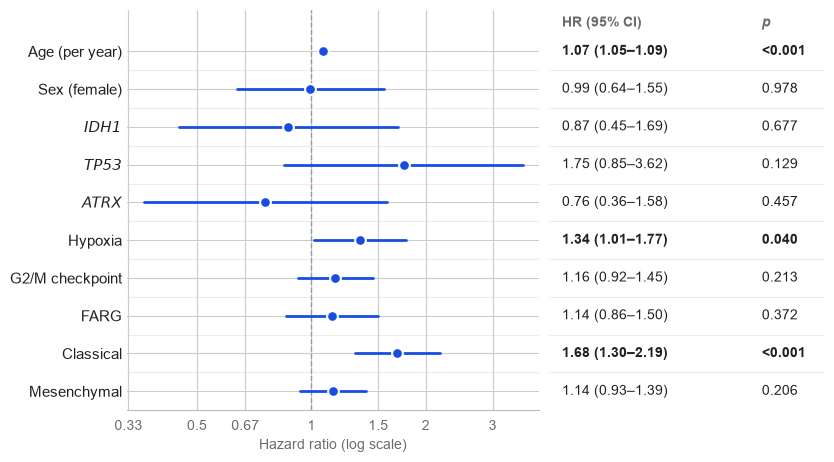

In [180]:
plot_forest(report_order, [("TCGA", summary, "#154DE6", "o")])

In [181]:
cph_multi.check_assumptions(df_multi)

Proportional hazard assumption looks okay.


[]

In [182]:
with open(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg\cph_multi.pkl", "wb") as f:
    pickle.dump(cph_multi, f)

In [183]:
sig_pathways = [f for f in sig.index if f in pathway_features]
sig_keys = [(f, pathway_features[f]) for f in sig_pathways if f in pathway_features]

### Adjustment for Established Markers

#### IDH Status and Age

In [184]:
idh_df = merged_df[["time", "event", "age"]].copy()
idh_df["IDH1_mut"] = merged_df["IDH1_mut"]

print(f"IDH1-mutant: {int(idh_df['IDH1_mut'].sum())}/{len(idh_df)} ({idh_df['IDH1_mut'].mean():.0%})")
print("Median age by IDH status:")
print(idh_df.groupby("IDH1_mut")["age"].median().rename({0: "IDH-wildtype", 1: "IDH-mutant"}).to_string())
print()

for cols in (["age"], ["IDH1_mut"], ["age", "IDH1_mut"]):
    cph_idh = CoxPHFitter().fit(idh_df[cols + ["time", "event"]], "time", "event")
    print(f"Cox model {cols}: C-index = {cph_idh.concordance_index_:.3f}")
    print(cph_idh.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3).to_string())
    print()

IDH1-mutant: 387/501 (77%)
Median age by IDH status:
IDH1_mut
IDH-wildtype    52.5
IDH-mutant      39.0

Cox model ['age']: C-index = 0.779
           exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%    p
covariate                                                          
age            1.072                1.054                1.092  0.0

Cox model ['IDH1_mut']: C-index = 0.679
           exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%    p
covariate                                                          
IDH1_mut       0.301                0.196                0.463  0.0

Cox model ['age', 'IDH1_mut']: C-index = 0.795
           exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%    p
covariate                                                          
age            1.066                1.047                1.086  0.0
IDH1_mut       0.385                0.247                0.602  0.0



In [185]:
grade_df = load_tcga_table(
    os.path.join(
        clinical_path,
        "f3a1bc62-9552-4553-b318-7d9c21d21ce7/nationwidechildrens.org_clinical_patient_lgg.txt"
    ),
    ["bcr_patient_barcode", "neoplasm_histologic_grade"]
)
grade_df["bcr_patient_barcode"] = grade_df["bcr_patient_barcode"].map(clean_tcga_id)
grade = (grade_df.drop_duplicates("bcr_patient_barcode")
                 .set_index("bcr_patient_barcode")["neoplasm_histologic_grade"]
                 .map({"G2": 0, "G3": 1}))

adj_df = dimred_merged_df[["time", "event", "age"] + sig_pathways].copy()
adj_df["IDH1_mut"] = dimred_merged_df["IDH1_mut"]
adj_df["grade_III"] = grade.reindex(adj_df.index)
adj_df = adj_df.dropna()
print(f"Patients with grade available: {len(adj_df)}/{len(dimred_merged_df)}")

adj_labels = {**all_features, "grade_III": "Grade III"}
for label, cols in [
    ("Unadjusted",               ["age"] + sig_pathways),
    ("Adjusted for IDH + grade", ["age"] + sig_pathways + ["IDH1_mut", "grade_III"]),
]:
    cph_adj = CoxPHFitter().fit(adj_df[cols + ["time", "event"]], "time", "event")
    print()
    print(f"{label} (n={len(adj_df)}): C-index = {cph_adj.concordance_index_:.3f}")
    print(cph_adj.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
          .rename(index=adj_labels).round(3).to_string())

Patients with grade available: 500/501

Unadjusted (n=500): C-index = 0.818
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%     p
covariate                                                                   
Age                    1.066                1.047                1.086  0.00
Classical Pathway      1.943                1.558                2.423  0.00
Hypoxia Pathway        1.406                1.085                1.822  0.01

Adjusted for IDH + grade (n=500): C-index = 0.828
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                    
Age                    1.063                1.043                1.084  0.000
Classical Pathway      1.692                1.321                2.167  0.000
Hypoxia Pathway        1.304                1.003                1.694  0.047
IDH1                   0.725                0.421                1.249  0.247
Grade III           

In [186]:
from scipy.stats import chi2
for marker_label, marker_cols in [("age + IDH + grade", ["age", "IDH1_mut", "grade_III"])]:
    print(f"=== Markers: {marker_label} ===")
    nested = {}
    for label, cols in [("Markers only", marker_cols), ("Markers + pathways", marker_cols + sig_pathways)]:
        nested[label] = CoxPHFitter().fit(adj_df[cols + ["time", "event"]], "time", "event")
        print(f"{label} (n={len(adj_df)}): C-index = {nested[label].concordance_index_:.3f}")
    lr_stat = 2 * (nested["Markers + pathways"].log_likelihood_ - nested["Markers only"].log_likelihood_)
    lr_df = len(sig_pathways)
    c_gain = nested["Markers + pathways"].concordance_index_ - nested["Markers only"].concordance_index_
    print(f"Likelihood-ratio test: chi2 = {lr_stat:.2f}, df = {lr_df}, p = {chi2.sf(lr_stat, lr_df):.4f}")
    print(f"C-index gain from adding the pathways: {c_gain:+.3f}")
    print()

=== Markers: age + IDH + grade ===
Markers only (n=500): C-index = 0.815
Markers + pathways (n=500): C-index = 0.828
Likelihood-ratio test: chi2 = 24.81, df = 2, p = 0.0000
C-index gain from adding the pathways: +0.013



## Performance Evaluation

### Discrimination

In [187]:
sig_pathways = [f for f in sig.index if f in pathway_features]

In [188]:
def bootstrap_ci(df, features, n_boot=200, seed=42):
    rng = np.random.default_rng(seed)
    cis = []
    for _ in range(n_boot):
        sample = df.sample(n=len(df), replace=True, random_state=int(rng.integers(1e6))).reset_index(drop=True)
        try:
            cph = CoxPHFitter()
            cph.fit(sample[features + ["time", "event"]], duration_col="time", event_col="event")
            ci = concordance_index(sample["time"], -cph.predict_partial_hazard(sample), sample["event"])
            cis.append(ci)
        except Exception:
            continue
    return np.mean(cis), np.percentile(cis, [2.5, 97.5])

In [189]:
cindex_results = {}
for label, features in [
    ("Age only",       ["age"]),
    ("Pathways only",  sig_pathways),
    ("Age + Pathways", ["age"] + sig_pathways),
]:
    if not features:
        continue
    df_model = dimred_merged_df[features + ["time", "event"]].dropna()
    point, (lo, hi) = bootstrap_ci(df_model, features)
    cindex_results[label] = (point, lo, hi)
    print(f"{label}: C-index = {point:.4f} (95% CI: {lo:.4f}-{hi:.4f})")

Age only: C-index = 0.7782 (95% CI: 0.7105-0.8268)
Pathways only: C-index = 0.7519 (95% CI: 0.6869-0.8165)
Age + Pathways: C-index = 0.8211 (95% CI: 0.7732-0.8629)


In [190]:
time_points = [365, 1095, 1825]
time_labels = ["1-year", "3-year", "5-year"]

features_map = {
    "Age only":       ["age"],
    "Pathways only":  sig_pathways,
    "Age + Pathways": ["age"] + sig_pathways,
}

features_map = {label: f for label, f in features_map.items() if f}

auc_results = {}

for label, features in features_map.items():
    df_model = dimred_merged_df[features + ["time", "event"]].dropna()
    y = np.array(
        [(bool(e), float(t)) for e, t in zip(df_model["event"], df_model["time"])],
        dtype=[("event", bool), ("time", float)]
    )
    cph = CoxPHFitter()
    cph.fit(df_model, duration_col="time", event_col="event")
    risk_scores = cph.predict_partial_hazard(df_model).values
    auc, mean_auc = cumulative_dynamic_auc(y, y, risk_scores, time_points)
    auc_results[label] = list(auc)
    print(f"{label}:")
    for t_label, a in zip(time_labels, auc):
        print(f"  {t_label} AUC = {a:.4f}")
    print(f"  Mean AUC = {mean_auc:.4f}\n")

Age only:
  1-year AUC = 0.8450
  3-year AUC = 0.8021
  5-year AUC = 0.7746
  Mean AUC = 0.8017

Pathways only:
  1-year AUC = 0.7852
  3-year AUC = 0.7887
  5-year AUC = 0.7623
  Mean AUC = 0.7795

Age + Pathways:
  1-year AUC = 0.8821
  3-year AUC = 0.8455
  5-year AUC = 0.8084
  Mean AUC = 0.8408



Age only: Mean AUC = 0.7870
Pathway scores only: Mean AUC = 0.7566
Age + pathway scores: Mean AUC = 0.8267


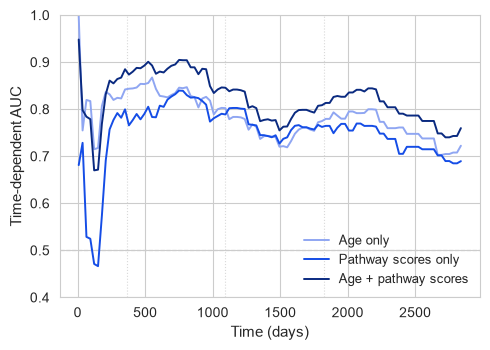

In [191]:
COLOUR, LIGHT, DARK = "#154DE6", "#8FA6F2", "#0A2A80"

event_times = dimred_merged_df.loc[dimred_merged_df["event"] == 1, "time"]
time_grid = np.linspace(event_times.min() + 1, event_times.quantile(0.90), 100)

fig, ax = plt.subplots(figsize=(5, 3.6))

for t in time_points:
    ax.axvline(t, color="#d9d9d9", lw=0.8, ls=":", zorder=0)

for (label, features), colour in zip([
    ("Age only",             ["age"]),
    ("Pathway scores only",  sig_pathways),
    ("Age + pathway scores", ["age"] + sig_pathways),
], [LIGHT, COLOUR, DARK]):
    if not features:
        continue
    df_model = dimred_merged_df[features + ["time", "event"]].dropna()
    y = np.array(
        [(bool(e), float(t)) for e, t in zip(df_model["event"], df_model["time"])],
        dtype=[("event", bool), ("time", float)]
    )
    cph = CoxPHFitter()
    cph.fit(df_model, duration_col="time", event_col="event")
    risk_scores = cph.predict_partial_hazard(df_model).values

    auc, mean_auc = cumulative_dynamic_auc(y, y, risk_scores, time_grid)
    ax.plot(time_grid, auc, label=label, color=colour, lw=1.4)
    print(f"{label}: Mean AUC = {mean_auc:.4f}")

ax.axhline(0.5, color="grey", ls="--", lw=0.8, zorder=0)
ax.set_ylim(0.4, 1.0)
ax.set_xlabel("Time (days)", fontsize=11)
ax.set_ylabel("Time-dependent AUC", fontsize=11)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

### Calibration

1 year:
  Quintile 1: predicted = 0.778, observed = 0.723
  Quintile 2: predicted = 0.945, observed = 0.967
  Quintile 3: predicted = 0.974, observed = 0.988
  Quintile 4: predicted = 0.985, observed = 0.985
  Quintile 5: predicted = 0.993, observed = 1.000
3 years:
  Quintile 1: predicted = 0.331, observed = 0.328
  Quintile 2: predicted = 0.721, observed = 0.705
  Quintile 3: predicted = 0.855, observed = 0.878
  Quintile 4: predicted = 0.916, observed = 0.928
  Quintile 5: predicted = 0.958, observed = 0.957
5 years:
  Quintile 1: predicted = 0.162, observed = 0.000
  Quintile 2: predicted = 0.548, observed = 0.658
  Quintile 3: predicted = 0.748, observed = 0.708
  Quintile 4: predicted = 0.850, observed = 0.817
  Quintile 5: predicted = 0.923, observed = 0.893


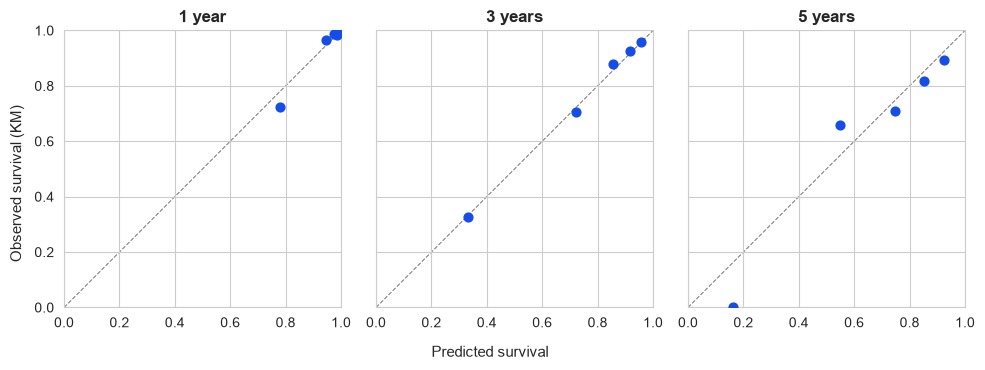

In [192]:
COLOUR = "#154DE6"
panel_titles = {182: "6 months", 365: "1 year", 730: "2 years", 1095: "3 years", 1825: "5 years"}

df_model = dimred_merged_df[["age"] + sig_pathways + ["time", "event"]].dropna().reset_index(drop=True)
cph = CoxPHFitter()
cph.fit(df_model, duration_col="time", event_col="event")

fig, axes = plt.subplots(1, len(time_points), figsize=(10, 3.6), sharey=True)

for ax, t_eval in zip(axes, time_points):
    pred_surv = cph.predict_survival_function(df_model, times=[t_eval]).T.squeeze()
    df_cal = df_model.copy()
    df_cal["pred_surv"] = pred_surv.values
    df_cal["group"] = pd.qcut(df_cal["pred_surv"], q=5, labels=False)

    observed, predicted = [], []
    for g in range(5):
        grp = df_cal[df_cal["group"] == g]
        kmf = KaplanMeierFitter().fit(grp["time"], event_observed=grp["event"])
        observed.append(kmf.survival_function_at_times([t_eval]).values[0])
        predicted.append(grp["pred_surv"].mean())

    print(f"{panel_titles[t_eval]}:")
    for g, (p, o) in enumerate(zip(predicted, observed), start=1):
        print(f"  Quintile {g}: predicted = {p:.3f}, observed = {o:.3f}")

    ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=0.8, zorder=0)
    ax.scatter(predicted, observed, color=COLOUR, s=40, zorder=3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_title(panel_titles[t_eval], fontsize=12, fontweight="bold")
    ax.tick_params(labelsize=10)

fig.supxlabel("Predicted survival", fontsize=11)
fig.supylabel("Observed survival (KM)", fontsize=11)
plt.tight_layout()
plt.show()

### Risk Stratification

In [193]:
COLOUR, LIGHT = "#154DE6", "#8FA6F2"

final_features = ["age"] + sig_pathways

df_model = dimred_merged_df[final_features + ["time", "event"]].dropna().copy()
cph = CoxPHFitter()
cph.fit(df_model, duration_col="time", event_col="event")

df_model["PI"] = cph.predict_partial_hazard(df_model).values

median_pi = df_model["PI"].median()
df_model["risk_group"] = np.where(df_model["PI"] >= median_pi, "High Risk", "Low Risk")

Median PI: 0.8382
High risk n=251, Low risk n=250
Log-rank p = 0.0000
Low Risk median survival: 3470 days (95% CI 2660-NR)
High Risk median survival: 1578 days (95% CI 984-1915)


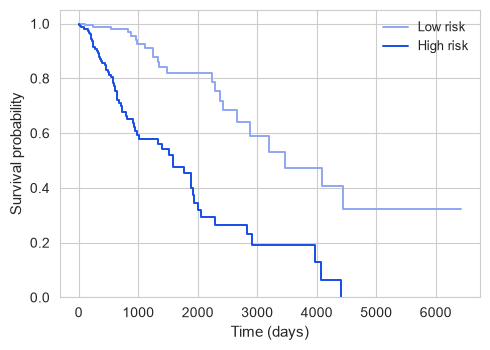

In [194]:
low = df_model[df_model["risk_group"] == "Low Risk"]
high = df_model[df_model["risk_group"] == "High Risk"]
lr = logrank_test(low["time"], high["time"], event_observed_A=low["event"], event_observed_B=high["event"])

fig, ax = plt.subplots(figsize=(5, 3.6))
kmf_objects = {}
for group, label, colour in [("Low Risk", "Low risk", LIGHT), ("High Risk", "High risk", COLOUR)]:
    mask = df_model["risk_group"] == group
    kmf = KaplanMeierFitter()
    kmf.fit(df_model.loc[mask, "time"], event_observed=df_model.loc[mask, "event"], label=label)
    kmf.plot_survival_function(ax=ax, color=colour, ci_show=False, lw=1.4)
    kmf_objects[group] = kmf

print(f"Median PI: {median_pi:.4f}")
print(f"High risk n={high.shape[0]}, Low risk n={low.shape[0]}")
print(f"Log-rank p = {lr.p_value:.4f}")
fmt = lambda v: "NR" if np.isinf(v) else f"{v:.0f}"
for group, kmf in kmf_objects.items():
    ci = median_survival_times(kmf.confidence_interval_)
    print(f"{group} median survival: {fmt(kmf.median_survival_time_)} days "
          f"(95% CI {fmt(ci.iloc[0, 0])}-{fmt(ci.iloc[0, 1])})")

ax.set_xlabel("Time (days)", fontsize=11)
ax.set_ylabel("Survival probability", fontsize=11)
ax.set_ylim(0, 1.05)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

### Group Characterisation

In [195]:
continuous_vars = ["age"] + sig_pathways
var_labels = {f: all_features.get(f, f) for f in continuous_vars}

df_char = dimred_merged_df.copy()
df_char.loc[df_model.index, "PI"] = df_model["PI"]
df_char.loc[df_model.index, "risk_group"] = df_model["risk_group"]
df_char = df_char.dropna(subset=["risk_group"])

for var in continuous_vars:
    low_vals = df_char.loc[df_char["risk_group"] == "Low Risk", var].dropna()
    high_vals = df_char.loc[df_char["risk_group"] == "High Risk", var].dropna()
    stat, p = mannwhitneyu(low_vals, high_vals, alternative="two-sided")
    print(f"{var_labels[var]}:")
    print(f"  Low Risk:  median = {low_vals.median():.3f}, IQR = {low_vals.quantile(0.25):.3f}-{low_vals.quantile(0.75):.3f}")
    print(f"  High Risk: median = {high_vals.median():.3f}, IQR = {high_vals.quantile(0.25):.3f}-{high_vals.quantile(0.75):.3f}")
    print(f"  Mann-Whitney U p = {p:.4e}\n")

Age:
  Low Risk:  median = 33.000, IQR = 29.000-38.750
  High Risk: median = 52.000, IQR = 43.000-60.000
  Mann-Whitney U p = 7.9159e-53

Classical Pathway:
  Low Risk:  median = -0.387, IQR = -0.866-0.037
  High Risk: median = 0.433, IQR = -0.170-1.141
  Mann-Whitney U p = 3.8129e-28

Hypoxia Pathway:
  Low Risk:  median = -0.103, IQR = -0.717-0.352
  High Risk: median = 0.262, IQR = -0.312-0.812
  Mann-Whitney U p = 1.2008e-08



In [196]:
for mut in dimred_mutation_cols:
    if mut not in df_char.columns:
        continue
    ct = pd.crosstab(df_char["risk_group"], df_char[mut])
    if ct.shape == (2, 2):
        _, p = fisher_exact(ct)
        test = "Fisher"
    else:
        _, p, _, _ = chi2_contingency(ct)
        test = "Chi-square"
    print(f"{mut} ({test} p = {p:.4f}):")
    print(ct)
    print()

ATRX_mut (Fisher p = 0.0000):
ATRX_mut      0    1
risk_group          
High Risk   181   70
Low Risk    134  116

IDH1_mut (Fisher p = 0.0000):
IDH1_mut     0    1
risk_group         
High Risk   85  166
Low Risk    29  221

TP53_mut (Fisher p = 0.0001):
TP53_mut      0    1
risk_group          
High Risk   154   97
Low Risk    110  140



Classical by IDH1: Mann-Whitney p < 0.001
Classical by TP53: Mann-Whitney p = 0.055
Classical by ATRX: Mann-Whitney p = 0.030

Hypoxia by IDH1: Mann-Whitney p < 0.001
Hypoxia by TP53: Mann-Whitney p = 0.796
Hypoxia by ATRX: Mann-Whitney p = 0.118



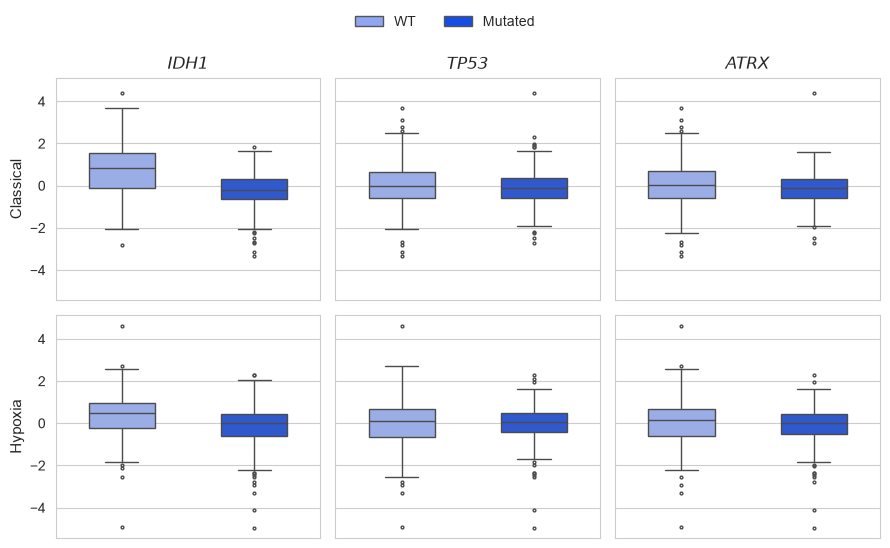

In [197]:
from matplotlib.patches import Patch

COLOUR, LIGHT = "#154DE6", "#8FA6F2"
score_labels = {
    "pi3k_akt_mtor_score_exp": "PI3K/AKT/mTOR", "emt_score_exp": "EMT",
    "hypoxia_score_exp": "Hypoxia", "g2m_score_exp": "G2/M checkpoint",
    "farg_score_exp": "FARG", "classical_score_exp": "Classical",
    "mesenchymal_score_exp": "Mesenchymal", "proneural_score_exp": "Proneural",
}

if len(sig_pathways) == 0:
    print("No significant pathways")
else:
    mutations = [f for f in reduced_features if f.endswith("_mut")]
    n_rows, n_cols = len(sig_pathways), len(mutations)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.5 * n_rows + 0.5),
                             sharey=True, squeeze=False)

    for row, pathway_col in enumerate(sig_pathways):
        for col, mut_col in enumerate(mutations):
            ax = axes[row, col]
            gene = mut_col.replace("_mut", "")
            wt_vals  = dimred_merged_df.loc[dimred_merged_df[mut_col] == 0, pathway_col].dropna()
            mut_vals = dimred_merged_df.loc[dimred_merged_df[mut_col] == 1, pathway_col].dropna()

            _, p = mannwhitneyu(wt_vals, mut_vals, alternative="two-sided")
            p_str = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
            print(f"{score_labels[pathway_col]} by {gene}: Mann-Whitney {p_str}")

            plot_df = pd.DataFrame({
                "status": ["Wild-type"] * len(wt_vals) + ["Mutated"] * len(mut_vals),
                "score":  pd.concat([wt_vals, mut_vals], ignore_index=True),
            })
            sns.boxplot(data=plot_df, x="status", y="score", hue="status",
                        order=["Wild-type", "Mutated"],
                        palette={"Wild-type": LIGHT, "Mutated": COLOUR},
                        width=0.5, linewidth=1, fliersize=2, legend=False, ax=ax)

            ax.set_xlabel("")
            ax.set_xticks([])
            ax.set_ylabel(f"{score_labels[pathway_col]}" if col == 0 else "", fontsize=11)
            ax.tick_params(labelsize=10)
            if row == 0:
                ax.set_title(f"$\\it{{{gene}}}$", fontsize=12, fontweight="bold")
        print()

    fig.legend(handles=[Patch(facecolor=LIGHT, edgecolor="#555555", label="WT"),
                        Patch(facecolor=COLOUR, edgecolor="#555555", label="Mutated")],
               loc="upper center", ncol=2, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.0))
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

## Clinical Application

In [198]:
for gene in global_coef_df[global_coef_df["coef"] != 0]["feature"]:
    if gene not in merged_expression_df.columns:
        continue
    vals = np.expm1(merged_expression_df[gene])
    print(f"{gene:20s}  median={vals.median():.1f},  75th={vals.quantile(0.75):.1f},  90th={vals.quantile(0.90):.1f}")

ALDOB_exp             median=0.6,  75th=0.9,  90th=1.2
ALDOC_exp             median=999.4,  75th=1441.3,  90th=1880.6
ARNTL_exp             median=9.1,  75th=12.4,  90th=18.0
AURKB_exp             median=3.1,  75th=7.4,  90th=19.7
COL6A1_exp            median=100.5,  75th=137.2,  90th=192.2
CTSC_exp              median=3.5,  75th=6.2,  90th=10.8
ENO2_exp              median=214.6,  75th=300.9,  90th=461.9
MCM6_exp              median=24.1,  75th=34.7,  90th=50.2
MN1_exp               median=16.8,  75th=25.9,  90th=37.4
MYB_exp               median=0.2,  75th=0.4,  90th=0.8
MYBL1_exp             median=3.3,  75th=4.7,  90th=6.7
S100A11_exp           median=125.4,  75th=240.0,  90th=504.0
SOX9_exp              median=176.2,  75th=254.9,  90th=358.4
SPP1_exp              median=459.1,  75th=1053.9,  90th=2362.2


In [199]:
patient_age    = 45
patient_gender = 1 

patient_genes_specified = {
    "VAV3_exp":   2.75,
    "SPP1_exp":   1390.9,

    "MLC1_exp":   669.3,
    "SOX9_exp":   273.4,
    "ARNTL_exp":  13.9,

    "ALDOC_exp":  1457.8,
    "ALDOB_exp":  0.970,
    "ENO2_exp":   331.7,
    "ENO3_exp":   5.86,

    "COL1A1_exp": 19.1,
    "COL5A1_exp": 5.09,
    "COL6A1_exp": 147.4,

    "CTSC_exp":   7.76,

    "AURKB_exp":  12.3,
    "MCM6_exp":   37.2,

    "MAP2K6_exp": 6.12,
    "PIK3CA_exp": 10.7,
    "PTEN_exp":   29.1,

    "RAB33A_exp": 91.2,
    "HDAC2_exp":  22.8,

    "ALDOC_exp":  1457.8,
    "CDKN2A_exp": 12.3,
    "CDKN2B_exp": 30.8,
    "EGFR_exp":   174.9,
    "IDH1_exp":   69.0,
    "MN1_exp":    26.7,
    "MYB_exp":    0.460,
    "MYBL1_exp":  4.84,
    "PDGFRA_exp": 140.8,
    "SPP1_exp":   1390.9,
}

In [200]:
score_scaler = joblib.load(os.path.join(save_dir, "tcga_score_scaler.pkl"))
global_model_saved, global_coef_df_saved, global_scaler_saved = joblib.load(
    os.path.join(save_dir, "global_enet_result.pkl"))

all_feature_cols = list(global_scaler_saved.feature_names_in_) \
    if hasattr(global_scaler_saved, "feature_names_in_") \
    else all_features_df.columns.tolist()

patient_full = {}
for col in all_feature_cols:
    if col == "age":
        patient_full[col] = patient_age
    elif col == "gender":
        patient_full[col] = 1                     
    elif col.endswith("_mut"):
        patient_full[col] = 0                     
    elif col.endswith("_exp"):
        raw_median        = float(np.expm1(merged_expression_df[col].median()))
        raw_val           = patient_genes_specified.get(col, raw_median)
        patient_full[col] = np.log1p(raw_val)

In [201]:
patient_feat_df = pd.DataFrame([patient_full])[all_feature_cols]
patient_scaled  = pd.DataFrame(
    global_scaler_saved.transform(patient_feat_df),
    columns=all_feature_cols
)

short_to_full = {
    'FARG': 'FARG Pathway', 'Classical': 'Classical Pathway',
    'Hypoxia': 'Hypoxia Pathway', 'EMT': 'EMT Pathway',
    'Mesenchymal': 'Mesenchymal Pathway', 'G2M': 'G2M Pathway',
    'PI3K/AKT/mTOR': 'PI3K mTOR Pathway', 'Proneural': 'Proneural Pathway',
}

In [202]:
patient_pathway_scores_raw    = {}
patient_pathway_scores_scaled = {}

print("=" * 75)
print("PATIENT PATHWAY SCORE COMPUTATION")
print(f"  Age: {patient_age}  |  Scores = Σ( β_global × z-score(gene) )")
print("=" * 75)

col_header = f"  {'Gene':<14}  {'Raw TPM':>10}  {'z-score':>9}  {'β (enet)':>10}  {'β × z':>10}"

for score_col in sig_pathways:
    pathway_label = pathway_features[score_col]
    full_name     = short_to_full.get(pathway_label, pathway_label)
    genes         = pathway_gene_map[full_name]
    available     = [g for g in genes if g in global_coef_df_saved["feature"].values]
    coef_sel      = global_coef_df_saved.set_index("feature").loc[available]
    n_nonzero     = (coef_sel["coef"] != 0).sum()

    print(f"\n{full_name}  ({n_nonzero}/{len(available)} genes selected by enet):")
    print(col_header)
    print("  " + "-" * 70)

    raw_score = 0
    for gene in available:
        coef = coef_sel.loc[gene, "coef"]
        if coef == 0:
            continue
        z_score      = patient_scaled[gene].values[0]
        raw_val      = float(np.expm1(patient_full[gene]))
        contribution = coef * z_score
        raw_score   += contribution
        tag = " *" if gene in patient_genes_specified else ""
        print(f"  {gene.replace('_exp','') + tag:<14}  {raw_val:>10.2f}  {z_score:>9.4f}  "
              f"{coef:>10.4f}  {contribution:>10.4f}")

    idx    = score_cols.index(score_col)
    scaled = (raw_score - score_scaler.mean_[idx]) / score_scaler.scale_[idx]
    patient_pathway_scores_raw[score_col]    = raw_score
    patient_pathway_scores_scaled[score_col] = scaled
    print(f"\n  Raw score  = Σ(β × z) = {raw_score:.4f}")
    print(f"  Scaled     = (raw - {score_scaler.mean_[idx]:.4f}) / {score_scaler.scale_[idx]:.4f} = {scaled:.4f}")

PATIENT PATHWAY SCORE COMPUTATION
  Age: 45  |  Scores = Σ( β_global × z-score(gene) )

Classical Pathway  (2/5 genes selected by enet):
  Gene               Raw TPM    z-score    β (enet)       β × z
  ----------------------------------------------------------------------
  SOX9 *              273.40     0.7678      0.1250      0.0960
  ARNTL *              13.90     0.7712      0.2710      0.2090

  Raw score  = Σ(β × z) = 0.3050
  Scaled     = (raw - -0.0000) / 0.3425 = 0.8906

Hypoxia Pathway  (3/5 genes selected by enet):
  Gene               Raw TPM    z-score    β (enet)       β × z
  ----------------------------------------------------------------------
  ALDOC *            1457.80     0.7144     -0.0561     -0.0401
  ALDOB *               0.97     0.7582     -0.1141     -0.0865
  ENO2 *              331.70     0.7069     -0.0392     -0.0277

  Raw score  = Σ(β × z) = -0.1544
  Scaled     = (raw - -0.0000) / 0.1481 = -1.0427


In [203]:
patient_df = pd.DataFrame({
    "age": [patient_age],
    **{col: [patient_pathway_scores_scaled[col]] for col in sig_pathways}
})
patient_pi = cph.predict_partial_hazard(patient_df).values[0]
risk_class = "High Risk" if patient_pi >= median_pi else "Low Risk"

print(f"\n{'=' * 75}")
print("PROGNOSTIC INDEX (PI) = exp( Σ β_j × (x_j − TCGA mean_j) )  [predicted partial hazard]")
print(f"  PI = {patient_pi:.4f}  (cohort median = {median_pi:.4f})")
print(f"  Risk Classification: {risk_class}")

print("\nPI contributions (β × (value − TCGA mean)):")


PROGNOSTIC INDEX (PI) = exp( Σ β_j × (x_j − TCGA mean_j) )  [predicted partial hazard]
  PI = 1.4271  (cohort median = 0.8382)
  Risk Classification: High Risk

PI contributions (β × (value − TCGA mean)):


In [204]:
pi_means = df_model[["age"] + sig_pathways].mean()
pi_total = 0.0
for v in ["age"] + sig_pathways:
    b = cph.params_[v]
    x = patient_df[v].values[0]
    c = b * (x - pi_means[v])
    pi_total += c
    print(f"  {v:<24} HR={np.exp(b):.3f}  β={b:.4f}  value={x:.3f}  mean={pi_means[v]:.3f}  contribution={c:.3f}")
print(f"  Sum = {pi_total:.3f}  ->  PI = exp(sum) = {np.exp(pi_total):.4f}")

print("\nPredicted Survival Probabilities:")
for t, label in zip([365, 1095, 1825], ["1-year", "3-year", "5-year"]):
    s = cph.predict_survival_function(patient_df, times=[t]).values[0][0]
    print(f"  {label}: {s:.3f}  ({s * 100:.1f}%)")

  age                      HR=1.066  β=0.0642  value=45.000  mean=43.130  contribution=0.120
  classical_score_exp      HR=1.944  β=0.6649  value=0.891  mean=0.000  contribution=0.592
  hypoxia_score_exp        HR=1.408  β=0.3419  value=-1.043  mean=-0.000  contribution=-0.356
  Sum = 0.356  ->  PI = exp(sum) = 1.4271

Predicted Survival Probabilities:
  1-year: 0.956  (95.6%)
  3-year: 0.769  (76.9%)
  5-year: 0.614  (61.4%)


In [205]:
print("Pipeline Verification (full-cohort reconstruction)")
test_idx = dimred_merged_df.index[0]
print(f"  test patient: {test_idx}")

original_cols = global_scaler_saved.feature_names_in_.tolist() \
    if hasattr(global_scaler_saved, "feature_names_in_") \
    else all_features_df.columns.tolist()

X_original = model_4_cph[original_cols].copy()  

X_scaled_verify = pd.DataFrame(
    global_scaler_saved.transform(X_original),
    index=X_original.index,
    columns=original_cols
)

for score_col in sig_pathways:
    pathway_label = pathway_features[score_col]
    full_name     = short_to_full.get(pathway_label, pathway_label)
    genes         = pathway_gene_map[full_name]
    available     = [g for g in genes if g in X_scaled_verify.columns]
    weights       = global_coef_df.set_index("feature").loc[available, "coef"]
    reconstructed = float(
        X_scaled_verify.loc[test_idx, available].values @ weights.values
    )
    idx        = score_cols.index(score_col)
    rec_scaled = (reconstructed - score_scaler.mean_[idx]) / score_scaler.scale_[idx]
    stored     = global_scores_scaled.loc[test_idx, score_col]
    print(f"  {full_name:30s}  scaled = {rec_scaled:.6f},  stored = {stored:.6f},  "
          f"match = {np.isclose(rec_scaled, stored, atol=1e-4)}")

Pipeline Verification (full-cohort reconstruction)
  test patient: TCGA-CS-4938
  Classical Pathway               scaled = -0.849218,  stored = -0.849218,  match = True
  Hypoxia Pathway                 scaled = 0.199569,  stored = 0.199569,  match = True


# Model Export (CGGA Validation)

In [206]:
model_dir = Path(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg")
model_dir.mkdir(parents=True, exist_ok=True)

for name, results in [
    ("logreg", results_final_logreg),
    ("cph", results_final_cph),
    ("rsf", results_final_rsf),
    ("gbm", results_final_gbm),
    ("ann", results_final_ann),
    ("dimred_logreg", dimred_results_final_logreg),
    ("dimred_cph", dimred_results_final_cph),
    ("dimred_rsf", dimred_results_final_rsf),
    ("dimred_gbm", dimred_results_final_gbm),
    ("dimred_ann", dimred_results_final_ann),
]:
    joblib.dump(results, model_dir / f"{name}.joblib")

joblib.dump(results_cv_logreg, model_dir / "cv_logreg.joblib")
joblib.dump(results_cv_cph,    model_dir / "cv_cph.joblib")
joblib.dump(results_cv_rsf,    model_dir / "cv_rsf.joblib")
joblib.dump(results_cv_gbm,    model_dir / "cv_gbm.joblib")
joblib.dump(results_cv_ann,    model_dir / "cv_ann.joblib")
joblib.dump(dimred_results_cv_logreg, model_dir / "dimred_cv_logreg.joblib")
joblib.dump(dimred_results_cv_cph,    model_dir / "dimred_cv_cph.joblib")
joblib.dump(dimred_results_cv_rsf,    model_dir / "dimred_cv_rsf.joblib")
joblib.dump(dimred_results_cv_gbm,    model_dir / "dimred_cv_gbm.joblib")
joblib.dump(dimred_results_cv_ann,    model_dir / "dimred_cv_ann.joblib")

['C:\\Users\\abbyn\\OneDrive\\Desktop\\Research Project\\TCGA\\saved_models\\tcga_lgg\\dimred_cv_ann.joblib']